# Telco Customer Churn Prediction
**Enterprise Data Science Bootcamp 2026 — Group 2 (`EDSB26_G2`)**


### Project Team

**André Capote** - 20251637 | **João Gonçalves** - 20210781 | **Paulo Amaro** - 20251643 | **Tomás Ramos** - 20251625
 

## **Introduction**

### **Research question** : How can we use customer churn risk estimates to prioritize retention interventions under limited operational capacity?



### **Defining the Business Problem**

### **Problem 1** — Which customer characteristics are associated with churn?
We aim to understand which customer attributes are linked to a higher likelihood of churn.

**Research Questions:**
* Do customers on month-to-month contracts exhibit a higher churn rate compared to those on annual contracts?
* Is customer tenure associated with churn?
* Are monthly charges, payment methods, or subscribed services correlated with customer attrition?

---

### **Problem 2** — Which customers are at the highest risk of churn?
We aim to build a model that estimates the probability of churn for each eligible customer.

**Research Questions:**
* Can we accurately identify churned customers in the test set?
* How well can the model discriminate between customers who left and those who stayed?
* Which model delivers the best performance for retention objectives?

---

### **Problem 3** — Whom should we contact first?
The business lacks the operational capacity to contact every customer and must prioritize outreach.

**Research Questions:**
* How many at-risk customers can we identify if outreach is capped at 5%, 10%, or 20% of the customer base?
* What proportion of total churners is captured within each top percentile tier?
* How does model-driven prioritization compare against random selection (cumulative gains/lift)?

---

### Table of Contents

- **Introduction**
- **0. Setup & Data Loading**
    - 0.1 Libraries
    - 0.2 Paths and File Loading
    - 0.3 Merge and Integrity Checks
    - 0.4 Analytical Population
- **1. Exploratory Data Analysis (EDA)**
    - 1.1 Demographics (demographics)
    - 1.2 Location & Population (location and population)
    - 1.3 Services (services)
    - 1.4 Status (status)
    - 1.5 Cross-Dataset Relationships
    - 1.6 Which Characteristics Are Associated with Churn? (Problem 1)
- **2. Feature Selection & Engineering**
    - 2.1 Feature Selection
    - 2.2 Feature Engineering
    - 2.3 Do the New Variables Improve the Model?
    - 2.4 Final Feature Set
- **3. Baseline Model: Logistic Regression**
    - 3.1 Train / Test Split
    - 3.2 Preprocessing (Numerical and Categorical)
    - 3.3 Model Evaluation
    - 3.4 Turning the Probabilities into a Priority List
    - 3.5 Data Leakage
    - 3.6 Conclusion — Logistic Regression
- **4. Model Comparison (Train / Validation / Test)**
    - 4.1 Train, Validation and Test Split
    - 4.2 Preprocessor and Experiments Table
    - 4.3 Winner Selection (Validation Only)
    - 4.4 Final Evaluation on the Test Set (Once)
- **5. Customer Prioritization (Problem 3)**
    - 5.1 Top-k: Precision, Recall and Lift by Fraction of Customers Contacted
    - 5.2 Ranking by Expected Value (P(churn) × Monthly Revenue)
    - 5.3 Conclusion — Model Comparison and Prioritization
- **6. Conclusions — Answers to the Problems**
    - 6.1 Answer to Problem 1 — Which characteristics are associated with churn?
    - 6.2 Answer to Problem 2 — Which customers have the highest churn risk?
    - 6.3 Answer to Problem 3 — Whom should we contact first?

## 0. Setup & Data Loading

### 0.1 Libraries

In this section, we import the core Python libraries required for the pipeline. These include data manipulation tools, statistical analysis, visualization libraries, machine learning algorithms and preprocessing pipelines, and specialized metrics designed to evaluate model performance on imbalanced classification tasks.

In [1]:
import os
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import date
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mtick
from scipy import stats
from sklearn import metrics
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap, PowerNorm 
from matplotlib.legend_handler import HandlerTuple

### 0.2 Paths and File Loading

In [2]:
# Base path - Tomas
# BASE = Path(
#          r"C:\Users\ramos\OneDrive\Ambiente de Trabalho\PG EDSA\2º Semestre\Enterprise Data Science Bootcamp\Project_TELCO"
#  )
# RAW = BASE/ "data" / "raw"

# Base path - Andre
BASE = Path(
    r"C:\Users\andre\Desktop\Nova_IMS\2ºSemestre\Bootcamp\Project\Project Datasets-20260918\TELCO_CHURN\Telco_customer_churn"
)
RAW = BASE

# # Base path - Paulo
# BASE = Path(
#     r"C:\Users\amaro\Desktop\Pós Graduação - EDSA\EDSB - Enterprise Data Science Bootcamp\_Projeto EDSB\Project Datasets-20261010\TELCO_CHURN\Telco_customer_churn"
# )
# RAW = BASE / "data" / "raw"

In [3]:
demographics = RAW / "Telco_customer_churn_demographics.xlsx"
location = RAW / "Telco_customer_churn_location.xlsx"
population = RAW / "Telco_customer_churn_population.xlsx"
services = RAW / "Telco_customer_churn_services.xlsx"
status = RAW / "Telco_customer_churn_status.xlsx"

In [4]:
df_demographics = pd.read_excel(demographics)
df_location = pd.read_excel(location)
df_population = pd.read_excel(population)
df_services = pd.read_excel(services)
df_status = pd.read_excel(status)

### 0.3 Merge and Integrity Checks

The five tables are joined on `Customer ID` (Population on `Zip Code`); key uniqueness and row counts are verified, not assumed.

In [5]:
TELCO = (
    df_demographics.merge(
        df_location,
        on="Customer ID",
        how="inner",
        validate="1:1",
        suffixes=("", "_loc"),
    )
    .merge(
        df_services,
        on="Customer ID",
        how="inner",
        validate="1:1",
        suffixes=("", "_srv"),
    )
    .merge(
        df_status, on="Customer ID", how="inner", validate="1:1", suffixes=("", "_sts")
    )
    .merge(df_population.drop(columns="ID"), on="Zip Code", how="left", validate="m:1")
)

assert len(TELCO) == 7043 and TELCO["Customer ID"].is_unique
print("Shape:", TELCO.shape)
print(TELCO["Customer Status"].value_counts())

Shape: (7043, 57)
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


### 0.4 Analytical Population

* None of the files contain duplicate `Customer ID` values (nor duplicate ZIP codes in Population), ensuring that the 1:1 and m:1 merges are safe and do not multiply rows.
* After merging, we have **7 043 customers and 57 columns**, with no customer lacking Population data (0 missing values following the left join).
* `Customer Status`: **4 720 Stayed**, **1 869 Churned**, and **454 Joined**. The 454 *Joined* customers are excluded from modeling (they are not part of the eligible population defined in the project brief), leaving **6 589 customers** for analysis.

## 1 - Exploratory Data Analysis (EDA)

 * **Columns:** Verify structural consistency, naming conventions, and missing features.
* **Values:** Ensure that values make business and logical sense within each column.

### 1.1 Demographic Analysis (`demographics`)
The objective of the demographics analysis is to evaluate the foundational profile of the company's customer base and identify the core socio-demographic characteristics that dominate its customer portfolio.

### Expected outcome
These analyses will help identify key customer patterns across demographic segments and reveal structural differences within the client population. The results may support customer segmentation, guide profile-specific service offerings, and inform retention initiatives tailored to distinct customer archetypes.

In [6]:
df_demographics.head()

,Customer ID,Count,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents
0,8779-QRDMV,1,Male,78,No,Yes,No,No,0
1,7495-OOKFY,1,Female,74,No,Yes,Yes,Yes,1
2,1658-BYGOY,1,Male,71,No,Yes,No,Yes,3
3,4598-XLKNJ,1,Female,78,No,Yes,Yes,Yes,1
4,4846-WHAFZ,1,Female,80,No,Yes,Yes,Yes,1


In [7]:
df_demographics.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Customer ID           7043 non-null   str  
 1   Count                 7043 non-null   int64
 2   Gender                7043 non-null   str  
 3   Age                   7043 non-null   int64
 4   Under 30              7043 non-null   str  
 5   Senior Citizen        7043 non-null   str  
 6   Married               7043 non-null   str  
 7   Dependents            7043 non-null   str  
 8   Number of Dependents  7043 non-null   int64
dtypes: int64(3), str(6)
memory usage: 495.3 KB


### 1.1.1 Gender Distribution
 
* **Gender Proportion:** Is there a higher percentage of male or female customers in our sample?


In [8]:
genders = pd.DataFrame(
    {
        "Frequency": df_demographics["Gender"].value_counts(),
        "Percentage (%)": df_demographics["Gender"].value_counts(normalize=True) * 100,
    }
)
print(genders)

        Frequency  Percentage (%)
Gender                           
Male         3555        50.47565
Female       3488        49.52435


### 1.1.2 Age and Lifecycle 
* **Average Age:** What is the average age of our customers?

In [9]:
# mean and median age
print(f"Mean age: {df_demographics['Age'].mean().round(2)}, Median age: {df_demographics['Age'].median()}")

Mean age: 46.51, Median age: 46.0


In [10]:
# Define the age bin edges starting at 20 up to (max_age + 10) in increments of 10.
bins = np.arange(20, df_demographics["Age"].max() + 11, 10)

# Create readable text labels for each 10-year range using the lower bounds.
labels = [f"{b}–{b+9}" for b in bins[:-1]]


# Categorize (bin) each customer's age into the defined intervals.
age_binned = pd.cut(df_demographics["Age"], bins=bins, right=False, labels=labels)
counts = age_binned.value_counts().reindex(labels)
percentages = counts / counts.sum() * 100
n_total = int(counts.sum())

# Identify the age group (label) with the highest percentage of customers.
top_label = percentages.idxmax()

# Retrieve the highest percentage value among all age groups.
top_pct = percentages.max()


In [11]:
# IBCS Style
BLACK, GREEN, LIGHT_GRAY, DARK_GRAY = "#000000", "#10E078", "#A6A6A6", "#8C8C8C"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

def ibcs_titles(fig, title, subtitle, source="Source: Telco Customer Churn Demographics Dataset"):
    fig.text(0.02, 0.97, title, fontsize=15, fontweight="bold", va="top", ha="left")
    fig.text(0.02, 0.89, subtitle, fontsize=11, color=DARK_GRAY, va="top", ha="left")
    fig.text(0.02, 0.01, source, fontsize=9, color=DARK_GRAY, ha="left", va="bottom")

def clean_axes(ax, keep_left=False, keep_bottom=True):
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    if keep_bottom:
        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color(DARK_GRAY)
    if keep_left:
        ax.spines["left"].set_visible(True)
    ax.grid(False)

title = f"The {top_label} age group accounts for {top_pct:.0f}% of customers"
subtitle = f"Customers by age group, % of total (n = {n_total:,})".replace(",", " ")

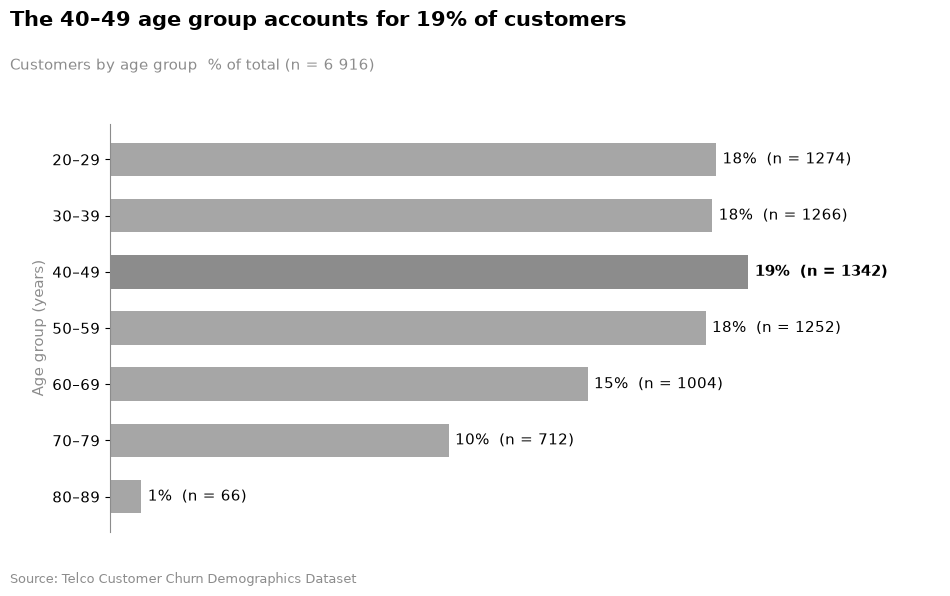

In [12]:
# Customer Age Group Distribution
fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(top=0.78, bottom=0.10, left=0.12, right=0.95)

# Highlight the largest age
colors = [DARK_GRAY if l == top_label else LIGHT_GRAY for l in labels]
ax.barh(labels, percentages.values, color=colors, height=0.6)

# Percentage and number of customers
for i, (pct, n) in enumerate(zip(percentages, counts)):
    ax.text(
        pct + percentages.max() * 0.01, i, f"{pct:.0f}%  (n = {n})",
        va="center", fontsize=11, fontweight="bold" if pct == top_pct else "normal",
    )

    # Axis styling
    ax.invert_yaxis()  # youngest group at the top
    ax.set_xticks([])
    ax.set_xlim(0, percentages.max() * 1.3)
    ax.set_ylabel("Age group (years)", color=DARK_GRAY)
    clean_axes(ax, keep_left=True, keep_bottom=False)
    ax.spines["left"].set_color(DARK_GRAY)

ibcs_titles(fig, title, subtitle)
plt.show()

* **Young Adults:** What is the number and percentage of customers under 30 years old?

In [13]:
age_under_30_count = df_demographics[df_demographics["Under 30"] == "Yes"]
age_under_30 = pd.DataFrame(
    {
        "Frequency": age_under_30_count["Under 30"].value_counts(),
        "Percentage (%)": age_under_30_count.shape[0] / df_demographics.shape[0] * 100,
    }
)
age_under_30.head()

,Frequency,Percentage (%)
Under 30,,
Yes,1401,19.892091


* **Senior Citizens:** Is there a high proportion of senior citizens (customers aged 65 and over)?

In [14]:
seniors_count = df_demographics[df_demographics["Senior Citizen"] == "Yes"]
seniors = pd.DataFrame(
    {
        "Frequency": seniors_count["Senior Citizen"].value_counts(),
        "Percentage (%)": seniors_count.shape[0] / df_demographics.shape[0] * 100,
    }
)
seniors.head()

,Frequency,Percentage (%)
Senior Citizen,,
Yes,1142,16.214681


### 1.1.3 Marital Status
 
* **Married Customers:** What is the number and percentage of customers classified as "married"? Is there a higher prevalence of married customers or otherwise?

In [15]:
married = pd.DataFrame(
    {
        "Frequency": df_demographics["Married"].value_counts(),
        "Percentage (%)": df_demographics["Married"].value_counts(normalize=True) * 100,
    }
)
married.head()

,Frequency,Percentage (%)
Married,,
No,3641,51.69672
Yes,3402,48.30328


### 1.1.4 Household and Dependents
 
* **Presence of Children:** Is there a predominance of customers with children or not?
* **Family Size:** What is the average number of children among customers (considering only the subgroup with dependents)?

In [16]:
df_demographics["Dependents"].value_counts()

Dependents
No     5416
Yes    1627
Name: count, dtype: int64

In [17]:
df_demographics["Dependents"].value_counts(normalize=True) * 100

Dependents
No     76.899049
Yes    23.100951
Name: proportion, dtype: float64

In [18]:
# Filter only clients with dependents (where dependents is True)
clients_with_dep = df_demographics[df_demographics["Dependents"] == "Yes"]

# Calculate the mean of 'number of dependents' and round to 2 decimal places
avg_dependents = round(float(clients_with_dep["Number of Dependents"].mean()), 2)

print(f"Average number of children for clients with dependents: {avg_dependents}")

Average number of children for clients with dependents: 2.03


In [19]:
# Data prep
counts = df_demographics["Number of Dependents"].value_counts().sort_index()
total = len(df_demographics)
pcts = (counts / total) * 100

top_dep = counts.idxmax()
top_pct = pcts.max()

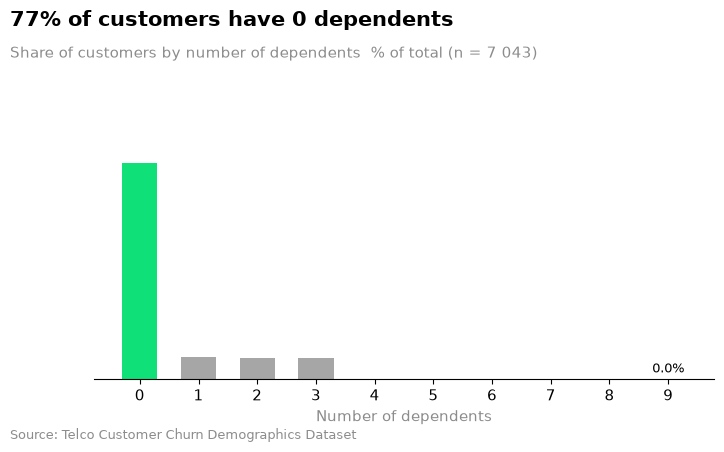

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.subplots_adjust(top=0.75, bottom=0.15)
title = f"{top_pct:.0f}% of customers have {top_dep} dependents"
subtitle = f"Share of customers by number of dependents, % of total (n = {total:,})".replace(",", " ")
ibcs_titles(fig, title, subtitle)

colors = [GREEN if idx == top_dep else LIGHT_GRAY for idx in counts.index]
bars = ax.bar(counts.index.astype(str), pcts.values, color=colors, width=0.6)

# Labels
for bar, (idx, c) in zip(bars, counts.items()):
    h = bar.get_height()
    x = bar.get_x() + bar.get_width() / 2

# Percentage label above bar
ax.text(x, h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=9.5, color=BLACK,
        fontweight="bold" if idx == top_dep else "normal")

# Raw count inside bar (uniform black bold text for all groups > 5%)
if h > 5:
        ax.text(x, h / 2, str(c), ha="center", va="center", fontsize=9.5,
        color=BLACK, fontweight="bold")

# Axis
ax.set_yticks([])
ax.set_ylim(0, top_pct * 1.25)
ax.set_xlabel("Number of dependents", color=DARK_GRAY)
clean_axes(ax, keep_left=False, keep_bottom=True)
ax.spines["bottom"].set_color(BLACK)
plt.show()

In [21]:
# Filter clients with at least one dependent
dep = df_demographics.loc[df_demographics["Number of Dependents"] > 0, "Number of Dependents"]
counts = dep.value_counts().sort_index()
avg_dep = dep.mean()
total_dep = len(dep)


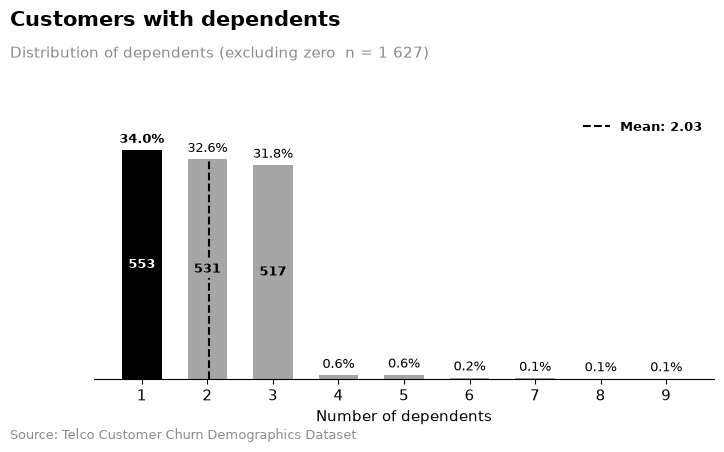

In [22]:
# Data: share of each group and the most common one
pct = counts / total_dep * 100
top = counts.idxmax()

# Figure & titles
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.subplots_adjust(top=0.75, bottom=0.15)
ibcs_titles(
    fig,
    "Customers with dependents",
    f"Distribution of dependents (excluding zero, n = {total_dep:,})".replace(",", " "),
)

# Bars: highlight the most common group in black
colors = [BLACK if i == top else LIGHT_GRAY for i in counts.index]
bars = ax.bar(counts.index, counts.values, color=colors, width=0.6)

# Labels: % above each bar (top in bold), count inside bars above 5% (white on the black bar)
pct_labels = ax.bar_label(bars, labels=[f"{p:.1f}%" for p in pct], padding=3, fontsize=9.5)
pct_labels[counts.values.argmax()].set_fontweight("bold")
count_labels = ax.bar_label(
    bars,
    labels=[str(c) if p > 5 else "" for c, p in zip(counts, pct)],
    label_type="center", fontsize=9.5, fontweight="bold",
)
count_labels[counts.values.argmax()].set_color("white")

# Mean reference line: only over the bar it falls on; label (with a line sample) at the top right
mean_bar = counts.index[np.abs(counts.index - avg_dep).argmin()]  # bar closest to the mean
mean_h = counts[mean_bar]
ax.vlines(avg_dep, 0, mean_h, color=BLACK, ls="--", lw=1.5, label=f"Mean: {avg_dep:.2f}")
ax.legend(loc="upper right", frameon=False, prop={"size": 9.5, "weight": "bold"})

# Gray box behind that bar's count so the dashed line doesn't cross the number
count_labels[list(counts.index).index(mean_bar)].set_bbox(
    dict(facecolor=LIGHT_GRAY, edgecolor="none", pad=1.5)
)

# Cleanup
ax.set_xticks(counts.index)
ax.set_yticks([])
ax.set_ylim(0, counts.max() * 1.18)
ax.set_xlabel("Number of dependents", color=BLACK)
clean_axes(ax, keep_left=False, keep_bottom=True)
ax.spines["bottom"].set_color(BLACK)

plt.show()

### 1.2 - Location & Population Analysis (`location` and `population`)

The objective of the location analysis is to understand the geographic distribution of the company's customer base and identify the cities that contribute most to its customer portfolio.

### Expected outcome

These analyses will help distinguish between cities with the largest customer bases and cities where the company has the strongest relative presence. The results may support geographic market analysis and help identify areas where further commercial or retention strategies could be investigated.

In [23]:
df_location.head()

,Customer ID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude
0,8779-QRDMV,1,United States,California,Los Angeles,90022,"34.02381, -118.156582",34.023810,-118.156582
1,7495-OOKFY,1,United States,California,Los Angeles,90063,"34.044271, -118.185237",34.044271,-118.185237
2,1658-BYGOY,1,United States,California,Los Angeles,90065,"34.108833, -118.229715",34.108833,-118.229715
3,4598-XLKNJ,1,United States,California,Inglewood,90303,"33.936291, -118.332639",33.936291,-118.332639
4,4846-WHAFZ,1,United States,California,Whittier,90602,"33.972119, -118.020188",33.972119,-118.020188


In [24]:
df_population.head()

,ID,Zip Code,Population
0,1,90001,54492
1,2,90002,44586
2,3,90003,58198
3,4,90004,67852
4,5,90005,43019


In [25]:
# how="left": keep every customer, even if the ZIP has no population
# validate="m:1": many customers -> one ZIP row. Pandas raises an error if Zip Code is duplicated in the population file.
df_merged = df_location.merge(
    df_population[["Zip Code", "Population"]],
    on="Zip Code",
    how="left",
    validate="m:1",
)

In [26]:
# Sanity checks
print("Rows after merge:", len(df_merged))  # must equal 7043
print("Customers without population:", df_merged["Population"].isna().sum()
)  # should be 0

Rows after merge: 7043
Customers without population: 0


### 1.2.1 Which cities have the highest number of customers?

**Research question:** Which cities have the largest number of Telco customers?

This analysis will identify the cities with the highest customer representation by counting the number of customers in each city. It will help determine where the company's customer base is most concentrated and identify the geographic markets that contribute most to its overall customer portfolio.

**Key metric:** Number of customers per city.

In [27]:
# Count customers per city
customers_by_city = (
    df_merged.groupby("City")["Customer ID"]
    .count()  
    .rename("customers")
    .sort_values(ascending=False)  # biggest cities first
    .to_frame()
)

In [28]:
# Share of the total customer base (%) and cumulative share. The cumulative column shows how concentrated the base is.
total_customers = len(df_merged)
customers_by_city["share_pct"] = customers_by_city["customers"] / total_customers * 100
customers_by_city["cum_share_pct"] = customers_by_city["share_pct"].cumsum()
customers_by_city.head(10)

,customers,share_pct,cum_share_pct
City,,,
Los Angeles,293,4.160159,4.160159
San Diego,285,4.046571,8.206730
San Jose,112,1.590231,9.796962
Sacramento,108,1.533437,11.330399
San Francisco,104,1.476643,12.807042
Fresno,61,0.866108,13.673151
Long Beach,60,0.851910,14.525060
Oakland,52,0.738322,15.263382
Escondido,51,0.724123,15.987505


In [29]:
# Concentration metrics
print("Number of cities:", len(customers_by_city))
print("Top 5 cities share (%):", customers_by_city["share_pct"].head(5).sum().round(1))
print("Top 10 cities share (%):", customers_by_city["share_pct"].head(10).sum().round(1)
)

Number of cities: 1106
Top 5 cities share (%): 12.8
Top 10 cities share (%): 16.6


In [30]:
# How many cities are needed to reach 50% of customers?
print( "Cities to reach 50% of base:", (customers_by_city["cum_share_pct"] <= 50).sum() + 1
)

Cities to reach 50% of base: 229


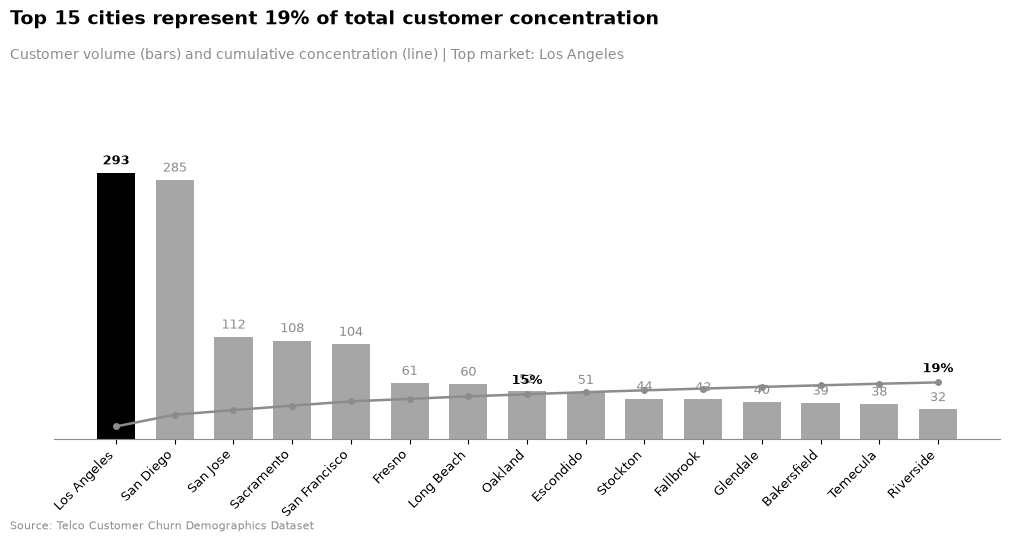

In [31]:
def ibcs_titles(fig, title, subtitle, source="Source: Telco Customer Churn Demographics Dataset"):
    fig.text(0.02, 0.96, title, fontsize=14, fontweight="bold", va="top", ha="left")
    fig.text(0.02, 0.89, subtitle, fontsize=10, color=DARK_GRAY, va="top", ha="left")
    fig.text(0.02, 0.01, source, fontsize=8, color=DARK_GRAY, ha="left", va="bottom")

def clean_spines(ax):
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color(DARK_GRAY)
    ax.grid(False)

# Chart Data Preparation
top = customers_by_city.head(15).copy()
x_indices = np.arange(len(top))
city_labels = [str(c) for c in top.index]

top_city = city_labels[0]
cum_share_15 = top["cum_share_pct"].iloc[-1]

# Dynamic Action Title & Subtitle
title = f"Top 15 cities represent {cum_share_15:.0f}% of total customer concentration"
subtitle = f"Customer volume (bars) and cumulative concentration (line) | Top market: {top_city}"

# Visualization Setup
fig, ax1 = plt.subplots(figsize=(11, 5.5))
fig.subplots_adjust(top=0.76, bottom=0.18, left=0.06, right=0.92)

# Bars: Highlight the top city in BLACK, remaining cities in LIGHT_GRAY
bar_colors = [BLACK if i == 0 else LIGHT_GRAY for i in range(len(top))]
bars = ax1.bar(x_indices, top["customers"], color=bar_colors, width=0.65)

# Value Labels directly above each bar (eliminates primary Y-axis numbers)
for i, v in enumerate(top["customers"]):
    ax1.text(
        i,
        v + top["customers"].max() * 0.02,
        f"{v:,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=9,
        color=BLACK if i == 0 else DARK_GRAY,
        fontweight="bold" if i == 0 else "normal",
    )

# Cumulative Line (IBCS neutral line in DARK_GRAY with direct point labeling)
ax2 = ax1.twinx()
ax2.plot(x_indices, top["cum_share_pct"], color=DARK_GRAY, linewidth=1.8, marker="o", markersize=4)

# Cumulative Percentage Labels on selected anchor points (first, midpoint, last)
label_steps = {0, len(top) // 2, len(top) - 1}
for i in label_steps:
    pct_val = top["cum_share_pct"].iloc[i]
    ax2.text(
        i,
        pct_val + 2.5,
        f"{pct_val:.0f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color=BLACK,
    )

# Axis configuration
ax1.set_xticks(x_indices)
ax1.set_xticklabels(city_labels, rotation=45, ha="right", fontsize=9, color=BLACK)
ax1.set_yticks([])
ax1.set_ylim(0, top["customers"].max() * 1.2)

ax2.set_yticks([])
ax2.set_ylim(0, 110)

# Minimal Spine Configuration
clean_spines(ax1)
for s in ["top", "right", "left", "bottom"]:
    ax2.spines[s].set_visible(False)

# Standardized IBCS Titles
ibcs_titles(fig, title, subtitle)

plt.show()

### 1.3 - Services Analysis (`services`)
The objective of the services analysis is to evaluate customer adoption across the company's product portfolio and identify which service lines drive the highest engagement and revenue.

### Expected outcome
These analyses will help distinguish between high-penetration core services and underutilized add-ons. The results may support service bundling strategies, identify cross-selling opportunities, and highlight which service configurations are associated with higher customer retention.

In [32]:
df_services.head()

,Customer ID,Count,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
0,8779-QRDMV,1,Q3,No,0,1,NaN,No,0.00,No,...,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65
1,7495-OOKFY,1,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,...,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10
2,1658-BYGOY,1,Q3,No,0,18,Offer D,Yes,11.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88
3,4598-XLKNJ,1,Q3,Yes,1,25,Offer C,Yes,19.76,No,...,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07
4,4846-WHAFZ,1,Q3,Yes,1,37,Offer C,Yes,6.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36


In [33]:
df_services.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Count                              7043 non-null   int64  
 2   Quarter                            7043 non-null   str    
 3   Referred a Friend                  7043 non-null   str    
 4   Number of Referrals                7043 non-null   int64  
 5   Tenure in Months                   7043 non-null   int64  
 6   Offer                              3166 non-null   str    
 7   Phone Service                      7043 non-null   str    
 8   Avg Monthly Long Distance Charges  7043 non-null   float64
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   str    
 11  Internet Type                      5517 non-null   str    
 12  Avg

In [34]:
df_services["Contract"].value_counts(normalize=True) * 100

Contract
Month-to-Month    51.256567
Two Year          26.735766
One Year          22.007667
Name: proportion, dtype: float64

#### 1.3.1 Univariate Analysis

#### Tenure in Months
**What it is:** The number of months a customer has been with the company, from 1 to 72.

# NOTA: pico dos 70 aos 72 poderão ser clientes fundadores da empresa, fazer referência quando falarmos do tenure.

In [35]:
t = df_services["Tenure in Months"].copy()  # create a copy to avoid modifying the original DataFrame

In [36]:
print(t.describe().round(2))  # count, mean, std, min, quartiles, max
print("Skew:", round(t.skew(), 2))

count    7043.00
mean       32.39
std        24.54
min         1.00
25%         9.00
50%        29.00
75%        55.00
max        72.00
Name: Tenure in Months, dtype: float64
Skew: 0.24


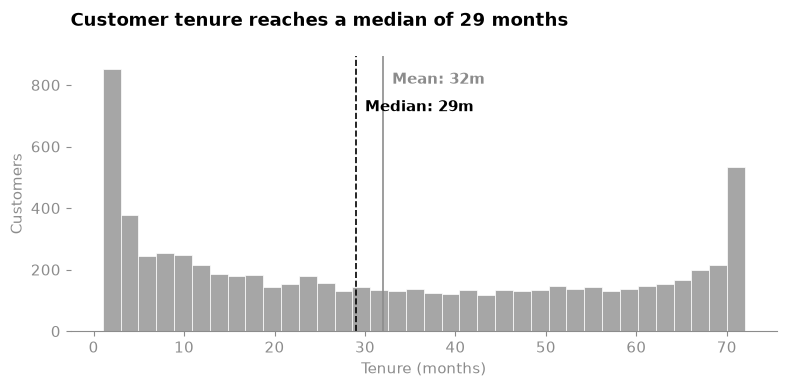

In [37]:
# Clean missing values
t_clean = t.dropna()

fig, ax = plt.subplots(figsize=(8, 4))

# Histogram
ax.hist(t_clean, bins=36, color=LIGHT_GRAY, edgecolor="white", linewidth=0.5)

# Rounded integer metrics
mean_val = round(t_clean.mean())
median_val = round(t_clean.median())

# Reference lines & direct labels (read ymax after histogram renders)
y_max = ax.get_ylim()[1]
ax.axvline(mean_val, color=DARK_GRAY, ls="-", lw=1.2)
ax.axvline(median_val, color=BLACK, ls="--", lw=1.2)
ax.text(mean_val + 1, y_max * 0.9, f"Mean: {mean_val}m", color=DARK_GRAY, weight="bold")
ax.text(median_val + 1, y_max * 0.8, f"Median: {median_val}m", color=BLACK, weight="bold")

# Minimal axes styling
ax.set_xlabel("Tenure (months)", color=DARK_GRAY)
ax.set_ylabel("Customers", color=DARK_GRAY)
ax.tick_params(colors=DARK_GRAY)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
plt.title(f"Customer tenure reaches a median of {median_val} months\n", loc="left", weight="bold")
plt.tight_layout()
plt.show()

**What we see:**
- Mean is 32 months and median is 29, so the center is fairly balanced.
- The shape is U-shaped, with spikes at 1 month (613 customers) and 72 months (362 customers).
- The base splits into two groups, new customers and long-term loyal ones, with fewer in between.

#### Number of Referrals

**What it is:** How many people a customer has referred to the company.

In [38]:
# number of referrals distribution
r = df_services["Number of Referrals"].copy()  # create a copy to avoid modifying the original DataFrame

In [39]:
ref_counts = r.value_counts().sort_index()
print(ref_counts)

Number of Referrals
0     3821
1     1086
2      236
3      255
4      236
5      264
6      221
7      248
8      213
9      238
10     223
11       2
Name: count, dtype: int64


**What we see:**
- It is heavily right-skewed. 54% of customers have 0 referrals and 15% have 1.
- From 2 to 10 referrals the counts are flat, at roughly 210 to 260 customers each.
- Most customers never refer anyone, and a smaller group refers actively.

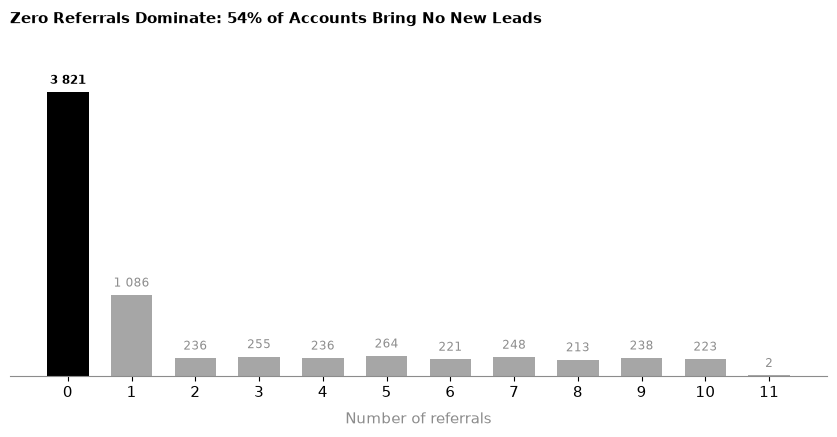

In [40]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

# IBCS accent: Highlight the primary category (0 referrals) in BLACK, remainder in LIGHT_GRAY
colors = [BLACK if x == 0 else LIGHT_GRAY for x in ref_counts.index]
bars = ax.bar(ref_counts.index, ref_counts.values, color=colors, width=0.65)

# Direct data labels over bars (eliminates need for primary Y-axis values)
for x, v in ref_counts.items():
    ax.text(
        x,
        v + ref_counts.max() * 0.02,
        f"{v:,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8.5,
        color=BLACK if x == 0 else DARK_GRAY,
        fontweight="bold" if x == 0 else "normal",
    )

    # Axis configuration
    ax.set_xticks(ref_counts.index)
    ax.set_yticks([])
    ax.set_ylim(0, ref_counts.max() * 1.15)
    ax.set_xlabel("Number of referrals", color=DARK_GRAY, labelpad=8)

# Minimal spine configuration (removes redundant framing)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)
ax.grid(False)

# IBCS Action Title: Sharp & Direct Lead
pct_zero = (ref_counts.loc[0] / ref_counts.sum()) * 100
plt.title(
    f"Zero Referrals Dominate: {pct_zero:.0f}% of Accounts Bring No New Leads\n",
    loc="left",
    fontsize=11,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

#### Internet Type

**What it is:** The kind of internet connection a customer has: Fiber Optic, DSL or Cable. Customers with no internet service have this field blank, labelled here as "No Internet"

In [41]:
net = df_services["Internet Type"].copy()  # create a copy to avoid modifying the original DataFrame

In [42]:
net_counts = net.value_counts()
print(net_counts)

Internet Type
Fiber Optic    3035
DSL            1652
Cable           830
Name: count, dtype: int64


In [43]:
net.isna().sum()

np.int64(1526)

In [44]:
no_net = net.fillna("No Internet").value_counts()
print(no_net)

Internet Type
Fiber Optic    3035
DSL            1652
No Internet    1526
Cable           830
Name: count, dtype: int64


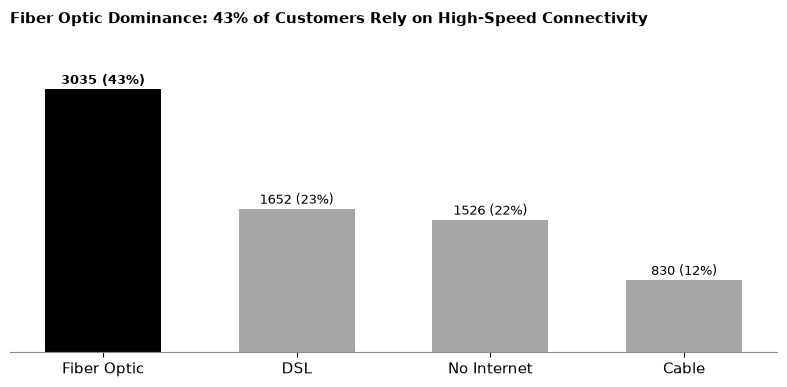

In [45]:
fig, ax = plt.subplots(figsize=(8, 4))

# Bars & direct labels (Fiber Optic in BLACK, others in LIGHT_GRAY)
colors = [BLACK] + [LIGHT_GRAY] * (len(no_net) - 1)
ax.bar(no_net.index, no_net.values, color=colors, width=0.6)

n_total = len(df_services)
for i, v in enumerate(no_net.values):
    pct = (v / n_total) * 100
    ax.text(i, v + no_net.max() * 0.02, f"{v} ({pct:.0f}%)", ha="center", weight="bold" if i == 0 else "normal", fontsize=9)

# Minimal axes styling
ax.set_yticks([])
ax.set_ylim(0, no_net.max() * 1.15)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
top_pct = (no_net.iloc[0] / n_total) * 100
plt.title(f"Fiber Optic Dominance: {top_pct:.0f}% of Customers Rely on High-Speed Connectivity\n", loc="left", weight="bold", fontsize=11)
plt.tight_layout()
plt.show()

**What we see:**
- Fiber Optic is the largest group (43%), followed by DSL (23%) and Cable (12%).
- 22% of customers have no internet service at all.
- Fiber Optic leads by a wide margin, so any trend in the base is largely a Fiber Optic trend.

#### Monthly Charge

**What it is:** The amount a customer is billed each month.

In [46]:
m = df_services["Monthly Charge"].copy()  # create a copy to avoid modifying the original DataFrame

In [47]:
m.describe().round(2)

count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75
Name: Monthly Charge, dtype: float64

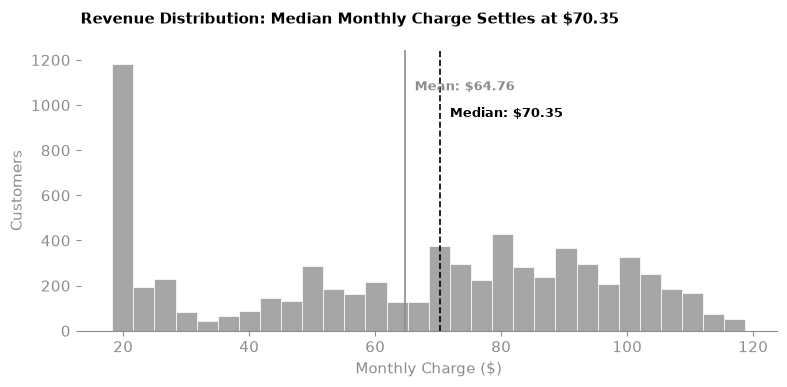

In [48]:
# Clean numeric values
m_clean = pd.to_numeric(m, errors="coerce").dropna()
mean_val = m_clean.mean()
median_val = m_clean.median()

# Single figure initialization
plt.figure(figsize=(8, 4))

# Distribution histogram
counts, bins, _ = plt.hist(m_clean, bins=30, color=LIGHT_GRAY, edgecolor="white", linewidth=0.5)
y_max = max(counts)

# Reference lines & direct annotations
plt.axvline(mean_val, color=DARK_GRAY, ls="-", lw=1.2)
plt.axvline(median_val, color=BLACK, ls="--", lw=1.2)
plt.text(mean_val + 1.5, y_max * 0.90, f"Mean: ${mean_val:.2f}", color=DARK_GRAY, weight="bold", fontsize=9)
plt.text(median_val + 1.5, y_max * 0.80, f"Median: ${median_val:.2f}", color=BLACK, weight="bold", fontsize=9)

# Axis styling
plt.xlabel("Monthly Charge ($)", color=DARK_GRAY)
plt.ylabel("Customers", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
ax = plt.gca()
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
plt.title(f"Revenue Distribution: Median Monthly Charge Settles at ${median_val:.2f}\n", loc="left", weight="bold", fontsize=11)
plt.tight_layout()
plt.show()

#### Total Charges

**What it is:** The cumulative amount billed to a customer over their whole relationship.

In [49]:
c = df_services["Total Charges"].copy()

In [50]:
c.describe().round(2)

count    7043.00
mean     2280.38
std      2266.22
min        18.80
25%       400.15
50%      1394.55
75%      3786.60
max      8684.80
Name: Total Charges, dtype: float64

In [51]:
# Summary numbers
print("Skew:", round(c.skew(), 2))
print(f"Share of customers below the mean: {(c < c.mean()).mean():.0%}")

Skew: 0.96
Share of customers below the mean: 62%


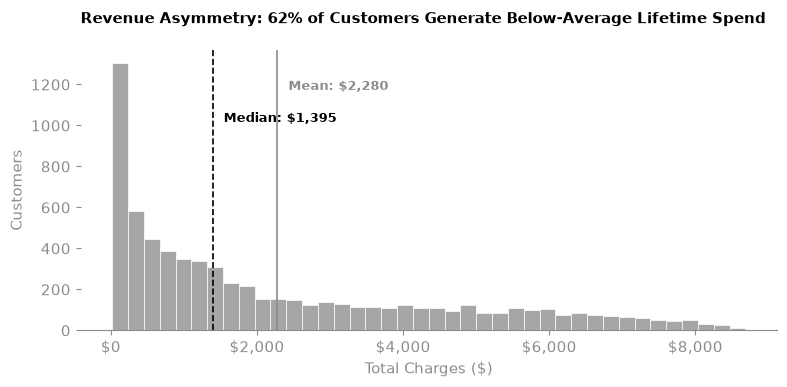

In [52]:
# Clean numeric values
c_clean = pd.to_numeric(c, errors="coerce").dropna()
mean_val = c_clean.mean()
median_val = c_clean.median()
share_below_mean = (c_clean < mean_val).mean() * 100

plt.figure(figsize=(8, 4))

# Distribution histogram
counts, bins, _ = plt.hist(c_clean, bins=40, color=LIGHT_GRAY, edgecolor="white", linewidth=0.5)
y_max = max(counts)

# Reference lines & direct annotations (no legend)
plt.axvline(mean_val, color=DARK_GRAY, ls="-", lw=1.2)
plt.axvline(median_val, color=BLACK, ls="--", lw=1.2)
plt.text(mean_val + 150, y_max * 0.90, f"Mean: ${mean_val:,.0f}", color=DARK_GRAY, weight="bold", fontsize=9)
plt.text(median_val + 150, y_max * 0.78, f"Median: ${median_val:,.0f}", color=BLACK, weight="bold", fontsize=9)

# Axis formatting
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.xlabel("Total Charges ($)", color=DARK_GRAY)
plt.ylabel("Customers", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
for s in ["top", "right", "left"]:
    plt.gca().spines[s].set_visible(False)
plt.gca().spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
plt.title(f"Revenue Asymmetry: {share_below_mean:.0f}% of Customers Generate Below-Average Lifetime Spend\n", loc="left", weight="bold", fontsize=11)
plt.tight_layout()
plt.show()

In [53]:
# prepare the cumulative data
c_sorted = c.sort_values()  # smallest to largest (c stays untouched)
cum = np.arange(1, len(c_sorted) + 1) / len(c_sorted)  # share of customers up to each value

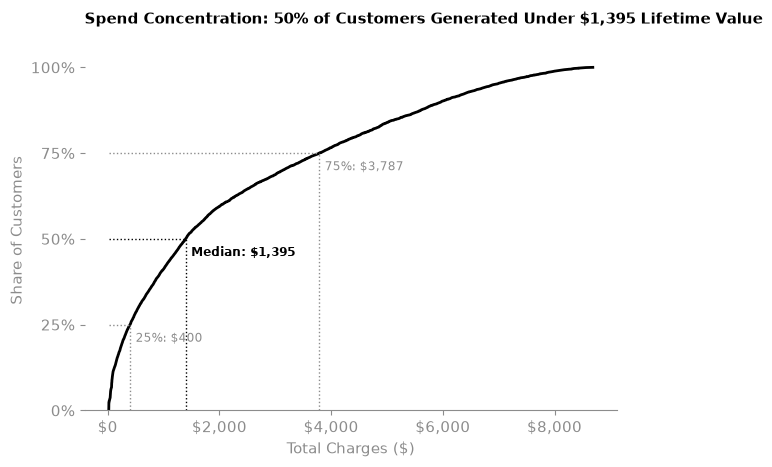

In [54]:
# Cumulative curve
plt.plot(c_sorted, cum, color=BLACK, lw=2)

# Direct quartile markers
for q, lbl in [(0.25, "25%"), (0.50, "Median"), (0.75, "75%")]:
    val = c.quantile(q)
    col, wt = (BLACK, "bold") if q == 0.50 else (DARK_GRAY, "normal")
    plt.hlines(q, c.min(), val, color=col, ls=":", lw=1)
    plt.vlines(val, 0, q, color=col, ls=":", lw=1)
    plt.text(val + 100, q - 0.05, f"{lbl}: ${val:,.0f}", color=col, weight=wt, fontsize=8.5)

# Axis styling & spines
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.yticks(np.arange(0, 1.1, 0.25), ["0%", "25%", "50%", "75%", "100%"])
plt.ylim(0, 1.05)
plt.xlabel("Total Charges ($)", color=DARK_GRAY)
plt.ylabel("Share of Customers", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)
for s in ["top", "right", "left"]:
    plt.gca().spines[s].set_visible(False)
plt.gca().spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
plt.title(f"Spend Concentration: 50% of Customers Generated Under ${c.median():,.0f} Lifetime Value\n", loc="left", weight="bold", fontsize=11)
plt.tight_layout()
plt.show()

**Distribution**
- The histogram is right-skewed (skew 0.96): many customers have small totals, and a long tail stretches toward high values.
- The mean ($2,280) is well above the median ($1,395), so the tail pulls the mean upward. 62% of customers are below the mean.
- The standard deviation ($2,266) is almost as large as the mean, so the values are very spread out.

**Percentiles (cumulative line)**
- 25% of customers have paid less than $400, and half have paid less than $1,395.
- 75% of customers are below $3,787, so the top quarter is spread over a wide range, from $3,787 to $8,685.
- The curve is steepest at the start: 41% of customers have totals under $1,000. It flattens toward the end, where few customers reach high totals (only about 10% are above $6,000).

**Conclusion**


Total Charges is not a "typical value" variable. Most customers have accumulated low or moderate amounts, while a minority of high-value customers account for the upper tail. Because of this skew, the median describes a typical customer better than the mean, and any later analysis should keep in mind that the mean is inflated by the tail.

#### Total Revenue

**What it is:** The real money earned from each customer: Total Charges, minus refunds, plus extra data charges and long distance charges.

In [55]:
r = df_services["Total Revenue"].copy()
money = FuncFormatter(lambda x, _: f"${x:,.0f}")  # formats ticks as $2,000

In [56]:
r.describe().round(2)

count     7043.00
mean      3034.38
std       2865.20
min         21.36
25%        605.61
50%       2108.64
75%       4801.15
max      11979.34
Name: Total Revenue, dtype: float64

In [57]:
print("Skew:", round(r.skew(), 2))
print(f"Share of customers below the mean: {(r < r.mean()).mean():.0%}")

Skew: 0.92
Share of customers below the mean: 61%


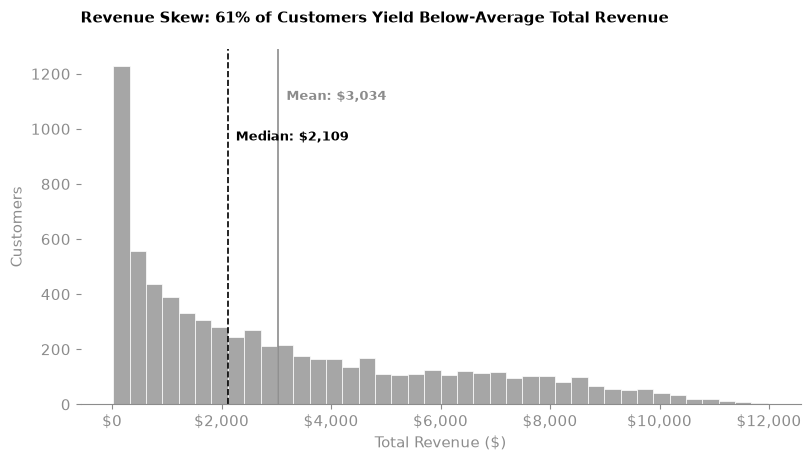

In [58]:
# Clean numeric values
r_clean = pd.to_numeric(r, errors="coerce").dropna()
mean_val = r_clean.mean()
median_val = r_clean.median()
share_below_mean = (r_clean < mean_val).mean() * 100

plt.figure(figsize=(8, 4.5), layout="constrained")

# Distribution histogram
counts, bins, _ = plt.hist(r_clean, bins=40, color=LIGHT_GRAY, edgecolor="white", linewidth=0.5)
y_max = max(counts)

# Reference lines & direct annotations (no legend)
plt.axvline(mean_val, color=DARK_GRAY, ls="-", lw=1.2)
plt.axvline(median_val, color=BLACK, ls="--", lw=1.2)
plt.text(mean_val + 150, y_max * 0.90, f"Mean: ${mean_val:,.0f}", color=DARK_GRAY, weight="bold", fontsize=9)
plt.text(median_val + 150, y_max * 0.78, f"Median: ${median_val:,.0f}", color=BLACK, weight="bold", fontsize=9)

# Axis formatting
plt.gca().xaxis.set_major_formatter(money)
plt.xlabel("Total Revenue ($)", color=DARK_GRAY)
plt.ylabel("Customers", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
for s in ["top", "right", "left"]:
    plt.gca().spines[s].set_visible(False)
plt.gca().spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
plt.title(f"Revenue Skew: {share_below_mean:.0f}% of Customers Yield Below-Average Total Revenue\n", loc="left", weight="bold", fontsize=11)
plt.show()

In [59]:
r_sorted = r.sort_values(ascending=False)  # biggest customers first
cum_customers = np.arange(1, len(r_sorted) + 1) / len(r_sorted) # share of customers (x)
cum_revenue = r_sorted.cumsum() / r_sorted.sum()  # share of total revenue (y)

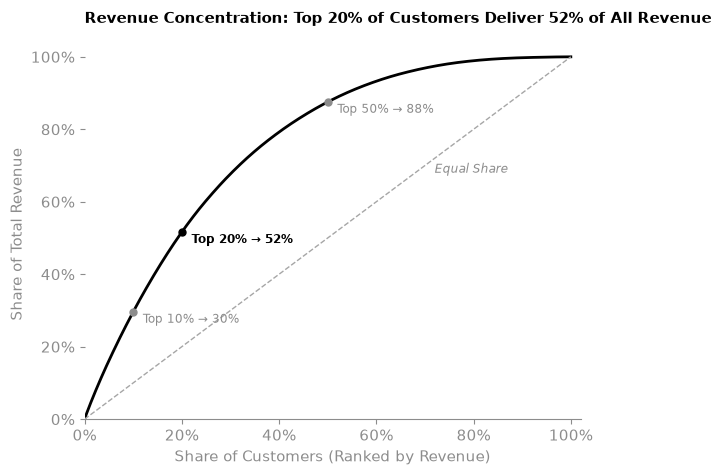

In [60]:
# Concentration curve (Lorenz curve) & equality baseline
plt.plot(cum_customers, cum_revenue, color=BLACK, lw=2)
plt.plot([0, 1], [0, 1], color=LIGHT_GRAY, ls="--", lw=1)
plt.text(0.72, 0.68, "Equal Share", color=DARK_GRAY, fontsize=8.5, style="italic")

# Direct milestone callouts (eliminates legend)
for p in [0.1, 0.2, 0.5]:
    y = cum_revenue.iloc[int(p * len(r_sorted)) - 1]
    col, wt = (BLACK, "bold") if p == 0.2 else (DARK_GRAY, "normal")
    plt.scatter(p, y, color=col, s=25, zorder=3)
    plt.text(p + 0.02, y - 0.03, f"Top {p:.0%} → {y:.0%}", color=col, weight=wt, fontsize=8.5)

# Axis configuration & formatting
ticks = np.arange(0, 1.1, 0.2)
labels = [f"{t:.0%}" for t in ticks]
plt.xticks(ticks, labels)
plt.yticks(ticks, labels)
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.xlabel("Share of Customers (Ranked by Revenue)", color=DARK_GRAY)
plt.ylabel("Share of Total Revenue", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
for s in ["top", "right", "left"]:
    plt.gca().spines[s].set_visible(False)
plt.gca().spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
top20_rev = cum_revenue.iloc[int(0.2 * len(r_sorted)) - 1] * 100
plt.title(f"Revenue Concentration: Top 20% of Customers Deliver {top20_rev:.0f}% of All Revenue\n", loc="left", weight="bold", fontsize=11)
plt.show()

**Distribution**
- The histogram is right-skewed (skew 0.92): many customers have low totals, and a long tail stretches toward high values.
- The mean ($3,034) is above the median ($2,109), so the tail pulls the mean upward. 61% of customers are below the mean.
- The standard deviation ($2,865) is close to the mean, so the values are very spread out.

**Percentiles**
- 25% of customers generate less than $606 and half generate less than $2,109.
- 75% are below $4,801, so the top quarter spreads from $4,801 up to $11,979.
- One third of customers (33%) generate under $1,000, while only about 8% generate more than $8,000.

**Concentration (cumulative curve)**
- Revenue is concentrated in a minority of customers: the top 10% bring in 30% of all revenue, the top 20% bring in 52%, and the top 50% bring in 88%.
- The bottom half of customers generates only 12% of revenue.

**Conclusion**
Total Revenue is unevenly distributed. Most customers contribute small or moderate amounts, while a minority of high-value customers account for a large part of the money earned. Because of the skew, the median describes a typical customer better than the mean, and the concentration curve shows that the business depends heavily on its top customers.

#### 1.3.2 Relationships within Services

##### Tenure in Months vs Total Charges and Total Revenue

**Question:** Do customers who stay longer accumulate more charges and more revenue?

In [61]:
corr = pd.DataFrame(
    {
        "Pearson": [t.corr(c), t.corr(r)],
        "Spearman": [t.corr(c, method="spearman"), t.corr(r, method="spearman")],
    },
    index=["Tenure vs Total Charges", "Tenure vs Total Revenue"],
).round(3)

corr["R²"] = (corr["Pearson"] ** 2).round(3)
corr

,Pearson,Spearman,R²
Tenure vs Total Charges,0.826,0.889,0.682
Tenure vs Total Revenue,0.853,0.913,0.728


In [62]:
# Tenure vs Total Charges
m, b = np.polyfit(t, c, 1)  # straight-line fit: c = m*t + b
x = np.array([t.min(), t.max()])

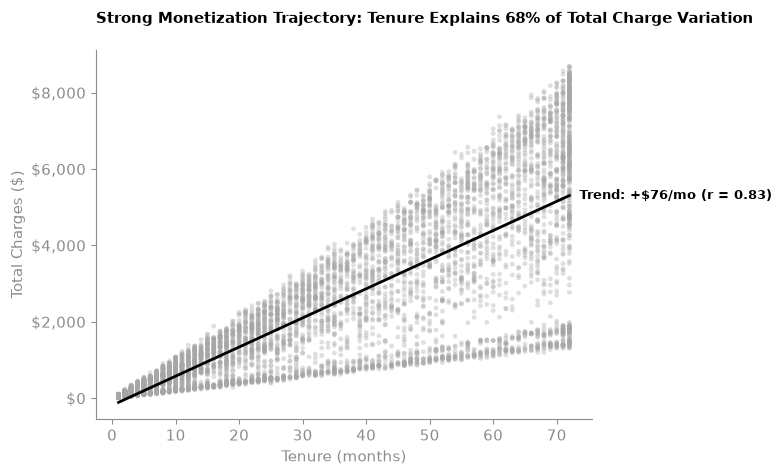

In [63]:
# Scatter in LIGHT_GRAY, Trend line in bold BLACK
plt.scatter(t, c, s=12, color=LIGHT_GRAY, alpha=0.35, edgecolors="none")
plt.plot(x, m * x + b, color=BLACK, lw=2)

# Direct trend line annotation (removes legend)
r_val = t.corr(c)
plt.text(
    x[-1],
    m * x[-1] + b,
    f"  Trend: +${m:,.0f}/mo (r = {r_val:.2f})",
    color=BLACK,
    weight="bold",
    fontsize=9,
    va="center",
)

# Axis configuration & formatting
plt.gca().yaxis.set_major_formatter(money)
plt.xlabel("Tenure (months)", color=DARK_GRAY)
plt.ylabel("Total Charges ($)", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
for s in ["top", "right"]:
    plt.gca().spines[s].set_visible(False)
for s in ["bottom", "left"]:
    plt.gca().spines[s].set_color(DARK_GRAY)

# IBCS Action Title
r2_val = corr.loc["Tenure vs Total Charges", "R²"]
plt.title(
    f"Strong Monetization Trajectory: Tenure Explains {r2_val:.0%} of Total Charge Variation\n",
    loc="left",
    weight="bold",
    fontsize=11,
)
plt.show()

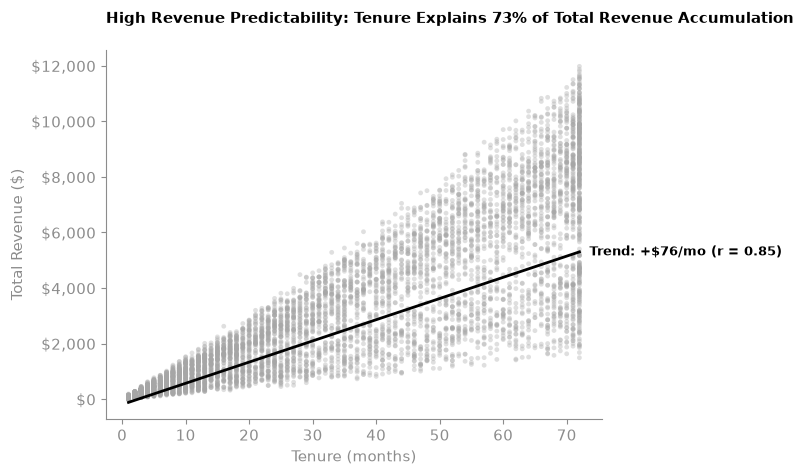

In [64]:
# Scatter in LIGHT_GRAY, Trend line in bold BLACK
plt.scatter(t, r, s=12, color=LIGHT_GRAY, alpha=0.35, edgecolors="none")
plt.plot(x, m * x + b, color=BLACK, lw=2)

# Direct trend line annotation (removes legend)
r_val = t.corr(r)
plt.text(
    x[-1],
    m * x[-1] + b,
    f"  Trend: +${m:,.0f}/mo (r = {r_val:.2f})",
    color=BLACK,
    weight="bold",
    fontsize=9,
    va="center",
)

# Axis configuration & formatting
plt.gca().yaxis.set_major_formatter(money)
plt.xlabel("Tenure (months)", color=DARK_GRAY)
plt.ylabel("Total Revenue ($)", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
for s in ["top", "right"]:
    plt.gca().spines[s].set_visible(False)
for s in ["bottom", "left"]:
    plt.gca().spines[s].set_color(DARK_GRAY)

# IBCS Action Title
r2_val = corr.loc["Tenure vs Total Revenue", "R²"]
plt.title(
    f"High Revenue Predictability: Tenure Explains {r2_val:.0%} of Total Revenue Accumulation\n",
    loc="left",
    weight="bold",
    fontsize=11,
)
plt.show()

In [65]:
# averages by tenure bands
bands = pd.cut(t, [0, 12, 24, 48, 72], labels=["1–12", "13–24", "25–48", "49–72"])

pd.DataFrame({"Total Charges": c, "Total Revenue": r}).groupby(
    bands, observed=True
).agg(["mean", "std"]).round(0)

Total Charges         Total Revenue        
                          mean     std          mean     std
Tenure in Months                                            
1–12                     277.0   272.0         388.0   361.0
13–24                   1126.0   580.0        1560.0   701.0
25–48                   2390.0  1222.0        3206.0  1484.0
49–72                   4686.0  2132.0        6171.0  2493.0

**Tenure vs Total Charges**
- There is a strong positive relationship: each extra month adds about $76 to the total on average.
- Tenure explains 68% of the variation in Total Charges.
- Spearman (0.89) is higher than Pearson (0.83), so the relationship is consistently increasing but not a perfect straight line.
- The points form a fan that widens with tenure. In the first year the spread is small (std $272), but beyond 48 months it is much larger (std $2,132). A customer at 72 months can have anywhere from $1,305 to $8,685.

**Tenure vs Total Revenue**
- The relationship is slightly stronger: about $100 more per extra month, and tenure explains 73% of the variation.
- It has the same fan shape, with growing spread as tenure increases.

**Conclusion**
Tenure is the main driver of both totals, which is expected because both accumulate over time. The relationship is a little stronger with Total Revenue than with Total Charges. The spread that remains at any given tenure comes from customers paying different monthly amounts. This correlation does not show that keeping customers longer *causes* higher spending by itself: the totals are partly built from time by definition. Its value is in showing that tenure explains most, but not all, of the differences in customer value.

#### Referral Behaviour vs. Customer Tenure

Context: Assess whether advocacy grows over time or if customer referrals happen primarily during the initial onboarding window.

Approach: Evaluate the relationship between tenure length and referral volume (using correlation metrics such as Spearman's rank) and analyze referral propensity across tenure quartiles to pinpoint the optimal engagement window.

In [66]:
# Settings
X_COL = "Number of Referrals"
Y_COL = "Tenure in Months"
JITTER = 0.2
SEED = 42

In [67]:
# Data preparation
rng = np.random.default_rng(SEED)
x_jittered = df_services[X_COL] + rng.uniform(-JITTER, JITTER, size=len(df_services))
mean_by_x = df_services.groupby(X_COL)[Y_COL].mean()

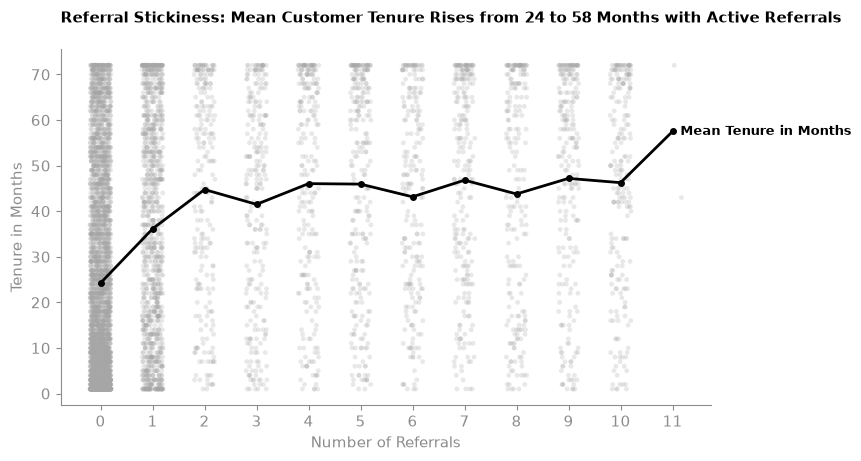

In [68]:
# Single-figure initialization
fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")

# Scatter (LIGHT_GRAY background density) & Mean line (BLACK accent)
ax.scatter(x_jittered, df_services[Y_COL], alpha=0.25, s=12, color=LIGHT_GRAY, edgecolors="none")
ax.plot(mean_by_x.index, mean_by_x.values, color=BLACK, marker="o", markersize=4, linewidth=2)

# Direct endpoint annotation (removes legend)
last_x, last_y = mean_by_x.index[-1], mean_by_x.values[-1]
ax.text(last_x + 0.15, last_y, f"Mean {Y_COL}", color=BLACK, weight="bold", fontsize=9, va="center")

# Axis configuration & styling
ax.set_xticks(range(int(df_services[X_COL].min()), int(df_services[X_COL].max()) + 1))
ax.set_xlabel(X_COL, color=DARK_GRAY)
ax.set_ylabel(Y_COL, color=DARK_GRAY)
ax.tick_params(colors=DARK_GRAY)

# Minimal IBCS borders
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
for s in ["bottom", "left"]:
    ax.spines[s].set_color(DARK_GRAY)
ax.grid(False)

# IBCS Action Title
tenure_0 = mean_by_x.loc[0]
tenure_max = mean_by_x.iloc[-1]
ax.set_title(
    f"Referral Stickiness: Mean Customer Tenure Rises from {tenure_0:.0f} to {tenure_max:.0f} Months with Active Referrals\n",
    loc="left",
    weight="bold",
    fontsize=11,
)

plt.show()

#### Internet Service Type & Distribution

Context: Identify the primary connectivity technology across the customer base to understand infrastructure reliance and upgrade potential.

Approach: Compute relative market shares (percentages) across internet service categories (e.g., Fiber Optic, DSL, None) using frequency tables and distribution plots to establish the core service profile.

Expected Outcomes

Identification of high-retention promotional offers.

Data-driven timing for referral and advocacy campaigns.

Baseline service distribution profile to benchmark upsell and cross-sell opportunities.

In [69]:
c = df_services["Monthly Charge"].copy()
no_net= df_services["Internet Type"].fillna("No Internet").copy()  # one value per customer

order = ["No Internet", "DSL", "Cable", "Fiber Optic"]  # lowest to highest average

print(len(c), len(no_net))  # both must be 7043

7043 7043


In [70]:
c.groupby(no_net).agg(["count", "mean", "median", "std", "min", "max"]).loc[order].round(1)

,count,mean,median,std,min,max
Internet Type,,,,,,
No Internet,1526,21.1,20.2,2.2,18.2,26.9
DSL,1652,58.2,56.2,16.3,23.4,94.8
Cable,830,60.3,59.0,17.9,24.2,113.0
Fiber Optic,3035,91.5,91.8,12.7,67.8,118.8


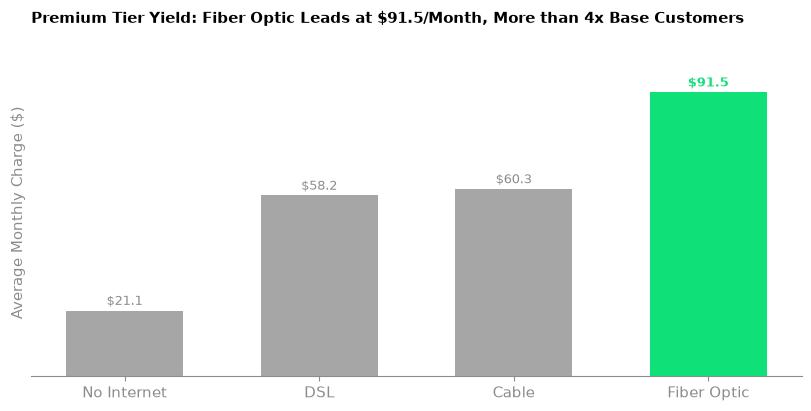

In [71]:
# Aggregation & plot setup
avg = c.groupby(no_net).mean().loc[order].round(1)
max_val = avg.max()
plt.figure(figsize=(8, 4), layout="constrained")
plt.bar(avg.index, avg.values, color=[GREEN if v == max_val else LIGHT_GRAY for v in avg.values], width=0.6)

# Labels & styling
for i, v in enumerate(avg.values):
    col, wt = (GREEN, "bold") if v == max_val else (DARK_GRAY, "normal")
    plt.text(i, v + max_val * 0.02, f"${v:.1f}", ha="center", color=col, weight=wt, fontsize=9)

plt.gca().set_yticks([])
plt.ylim(0, max_val * 1.15)
plt.ylabel("Average Monthly Charge ($)", color=DARK_GRAY)
plt.tick_params(colors=DARK_GRAY)
for s in ["top", "right", "left"]:
    plt.gca().spines[s].set_visible(False)
plt.gca().spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
plt.title(f"Premium Tier Yield: {avg.idxmax()} Leads at ${max_val:.1f}/Month, More than 4x Base Customers\n", loc="left", weight="bold", fontsize=11)
plt.show()

In [72]:
# how much internet type explains (η²)
group_means = c.groupby(no_net).transform("mean")
eta2 = ((group_means - c.mean()) ** 2).sum() / ((c - c.mean()) ** 2).sum()
print(f"Share of Monthly Charge variation explained by Internet Type: {eta2:.0%}")

Share of Monthly Charge variation explained by Internet Type: 81%


**Bar plot (averages)**
- Fiber Optic customers pay clearly the most: $91.5 on average, about 1.6 times the DSL average ($58.2).
- DSL and Cable are close ($58.2 and $60.3).
- Customers without internet pay about $21, which fits phone-only plans.

**Box plot (spread)**
- The groups barely overlap. The cheapest Fiber Optic customer ($67.8) pays more than about 70% of DSL and Cable customers.
- DSL and Cable overlap almost completely, so their small difference in averages is minor compared to the spread within each group.
- No Internet is the tightest group (std $2.2), because the plans are nearly identical. DSL and Cable vary the most (std about $16 to $18), probably because of different add-on services.
- Medians and means are almost equal in every group, so each distribution is roughly symmetric and the averages describe them well.

**Conclusion**
Internet type is the main driver of the monthly bill: it explains 81% of the variation in Monthly Charge. The pricing has three levels: phone-only (about $21), standard internet with DSL or Cable (about $60), and Fiber Optic as the premium tier (about $91). This also explains the two-peak shape seen in the Monthly Charge histogram.

### 1.4 - Status (`status`)
The objective of the status analysis is to evaluate customer retention dynamics, quantify churn volume across segments, and uncover the operational or contractual reasons driving departures.

### Expected outcome
These analyses will isolate the primary catalysts behind customer attrition (such as competitor offers, service dissatisfaction, or pricing issues) and contrast churned profiles against active accounts. The results may pinpoint vulnerable customer segments, guide targeted proactive retention campaigns, and inform policy adjustments to stabilize customer lifetime value.

In [73]:
df_status.head()

,Customer ID,Count,Quarter,Satisfaction Score,Customer Status,Churn Label,Churn Value,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,1,Q3,3,Churned,Yes,1,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,1,Q3,3,Churned,Yes,1,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,1,Q3,2,Churned,Yes,1,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,1,Q3,2,Churned,Yes,1,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,1,Q3,2,Churned,Yes,1,67,2793,Price,Extra data charges


In [74]:
df_status.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Customer ID         7043 non-null   str  
 1   Count               7043 non-null   int64
 2   Quarter             7043 non-null   str  
 3   Satisfaction Score  7043 non-null   int64
 4   Customer Status     7043 non-null   str  
 5   Churn Label         7043 non-null   str  
 6   Churn Value         7043 non-null   int64
 7   Churn Score         7043 non-null   int64
 8   CLTV                7043 non-null   int64
 9   Churn Category      1869 non-null   str  
 10  Churn Reason        1869 non-null   str  
dtypes: int64(5), str(6)
memory usage: 605.4 KB


## Missing values check

`Churn Category` and `Churn Reason` have 5,174 missing values (73.5%). Before treating this as a problem, let's check if it is expected.

In [75]:
df_status["Customer Status"].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [76]:
# Are the missing values tied to Customer Status?
print(pd.crosstab(df_status["Customer Status"], df_status["Churn Category"].isna()))

# Hard check: both fields are filled ONLY for churned customers
is_churned = df_status["Customer Status"] == "Churned"
assert (df_status["Churn Category"].notna() == is_churned).all()
print("OK: Churn Category and Churn Reason are filled if and only if Customer Status == 'Churned'")

Churn Category   False  True 
Customer Status              
Churned           1869      0
Joined               0    454
Stayed               0   4720
OK: Churn Category and Churn Reason are filled if and only if Customer Status == 'Churned'


**What we see:**
- The missing values are **structural, not errors**: a customer who stayed or just joined has no reason for leaving.
- We will **not impute** them. `Churn Category` and `Churn Reason` are analysed using only the 1,869 churned customers.

#### 1.4.2 Variable Analysis

##### Customer Status

**What it is:** Whether the customer `Stayed`, `Churned` or `Joined` (new customer in the quarter).

In [77]:
cs = df_status["Customer Status"].copy()

In [78]:
cs_order = (cs.value_counts().index.tolist())  # sorted by number of customers (largest first)

cs_freq = pd.DataFrame(
    {
        "Frequency": cs.value_counts().reindex(cs_order),
        "Percentage (%)": cs.value_counts(normalize=True).reindex(cs_order) * 100,
    }
).round(2)
print(cs_freq)

                 Frequency  Percentage (%)
Customer Status                           
Stayed                4720           67.02
Churned               1869           26.54
Joined                 454            6.45


In [79]:
# Churn rate: churned/all customers and churned/customers that existed without joined
print(f"Churn rate (all customers): {(cs == 'Churned').mean():.1%}")
print(f"Churn rate (excluding 'Joined'): {(cs == 'Churned').sum() / (cs != 'Joined').sum():.1%}"
)

Churn rate (all customers): 26.5%
Churn rate (excluding 'Joined'): 28.4%


**Notes:** So we will consider the Churn Rate of 28,4% for further analysis where we ill conclude it's impact in terms of Churn Risk

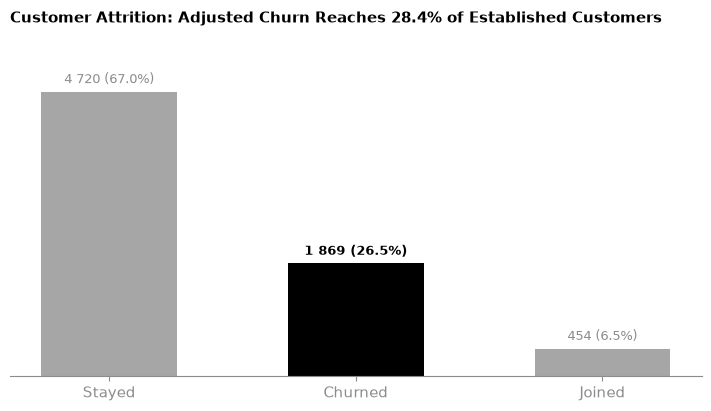

In [80]:
# Initialize canvas and axis
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")

# Bars: Highlight Churned in GREEN, baseline in LIGHT_GRAY
colors = [BLACK if status == "Churned" else LIGHT_GRAY for status in cs_order]
ax.bar(cs_order, cs_freq["Frequency"], color=colors, width=0.55)

# Direct data labels: "Count (Percentage)"
for i, (f, p) in enumerate(zip(cs_freq["Frequency"], cs_freq["Percentage (%)"])):
    ax.text(
        i,
        f + cs_freq["Frequency"].max() * 0.02,
        f"{f:,} ({p:.1f}%)".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=9,
        color=BLACK if cs_order[i] == "Churned" else DARK_GRAY,
        weight="bold" if cs_order[i] == "Churned" else "normal",
    )

# Axis & spine cleanup
ax.set_yticks([])
ax.set_ylim(0, cs_freq["Frequency"].max() * 1.15)
ax.tick_params(colors=DARK_GRAY)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# IBCS Action Title
churn_rate_adj = (cs == "Churned").sum() / (cs != "Joined").sum() * 100
ax.set_title(
    f"Customer Attrition: Adjusted Churn Reaches {churn_rate_adj:.1f}% of Established Customers\n",
    loc="left",
    weight="bold",
    fontsize=11,
)

plt.show()

**What we see:**
- 67.0% of customers stayed, 26.5% churned and 6.4% are new.
- The churn rate rises to 28.4% if we leave out the `Joined` customers, who have not had time to churn yet.
- The classes are imbalanced (about 3 stayed for every 1 churned). If this becomes a target variable, accuracy alone would be misleading: use recall, F1 or AUC.

#### Satisfaction Score

**What it is:** The customer's satisfaction with the company, on an ordinal scale from 1 (very unhappy) to 5 (very happy).

In [81]:
sat = df_status["Satisfaction Score"].copy()
sat.describe().round(2)

count    7043.00
mean        3.24
std         1.20
min         1.00
25%         3.00
50%         3.00
75%         4.00
max         5.00
Name: Satisfaction Score, dtype: float64

In [82]:
sat_freq = pd.DataFrame(
    {"Frequency": sat.value_counts().sort_index(),
    "Percentage (%)": sat.value_counts(normalize=True).sort_index() * 100}
).round(2)

print(sat_freq)

                    Frequency  Percentage (%)
Satisfaction Score                           
1                         922           13.09
2                         518            7.35
3                        2665           37.84
4                        1789           25.40
5                        1149           16.31


In [83]:
print(f"Mean: {sat.mean():.2f} | Median: {sat.median():.0f} | Mode: {sat.mode()[0]} | Std: {sat.std():.2f}")

Mean: 3.24 | Median: 3 | Mode: 3 | Std: 1.20


In [84]:
# Key metrics from pre-calculated variables
mode = int(sat.mode()[0])  # Identifies the most frequent score (Mode = 3)
y_max = sat_freq["Frequency"].max()  # Used for headroom scaling and label positioning

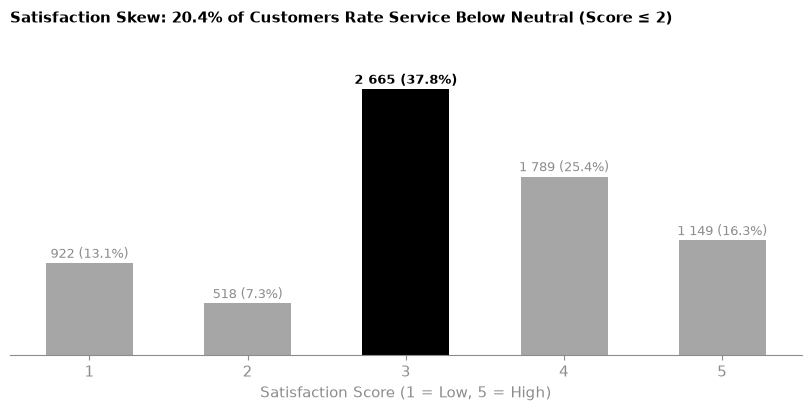

In [85]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")

# Plot bars with dominant mode highlight
bars = ax.bar(sat_freq.index.astype(str), sat_freq["Frequency"], color=[BLACK if i == mode else LIGHT_GRAY for i in sat_freq.index], width=0.55)

# Direct data callouts & container loop
for bar, (idx, row) in zip(bars, sat_freq.iterrows()):
    col, wt = (BLACK, "bold") if idx == mode else (DARK_GRAY, "normal")
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + y_max * 0.02, 
            f"{int(row['Frequency']):,} ({row['Percentage (%)']:.1f}%)".replace(",", " "), ha="center", color=col, weight=wt, fontsize=9)

# IBCS minimal axes & baseline
ax.set_yticks([])
ax.set_ylim(0, y_max * 1.15)
ax.set_xlabel("Satisfaction Score (1 = Low, 5 = High)", color=DARK_GRAY)
ax.tick_params(colors=DARK_GRAY)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# Action Title
ax.set_title(f"Satisfaction Skew: {sat_freq.loc[[1, 2], 'Percentage (%)'].sum():.1f}% of Customers Rate Service Below Neutral (Score ≤ 2)\n", loc="left", weight="bold", fontsize=11)
plt.show()

In [86]:
sat_bands = pd.cut(sat, bins=[0, 2, 3, 5], labels=["Low (1-2)", "Neutral (3)", "High (4-5)"])
pd.DataFrame(
    {"Frequency": sat_bands.value_counts().sort_index(),
    "Percentage (%)": ( sat_bands.value_counts(normalize=True).sort_index() * 100
     ).round(2)}
)

,Frequency,Percentage (%)
Satisfaction Score,,
Low (1-2),1440,20.45
Neutral (3),2665,37.84
High (4-5),2938,41.72


**What we see:**
- Score 3 is the most common (37.8%), and the mean is 3.24, so the center is slightly on the positive side.
- 41.7% of customers score 4 or 5, against 20.4% who score 1 or 2: the base leans positive.
- There is still a visible group of unhappy customers: score 1 (13.1%) is almost twice as common as score 2 (7.4%).

#### Churn Category

**What it is:** The broad group of reasons why a customer left. Only exists for churned customers (n = 1,869).

In [87]:
churned = df_status[df_status["Customer Status"] == "Churned"].copy()

# Only churned customers have a category (see the missing values check above)
churncat = churned["Churn Category"]

churncat_freq = pd.DataFrame({"Frequency": churncat.value_counts()})

print(churncat_freq)
print(f"Churned customers analysed: {len(churncat):,}")

                 Frequency
Churn Category            
Competitor             841
Attitude               314
Dissatisfaction        303
Price                  211
Other                  200
Churned customers analysed: 1,869


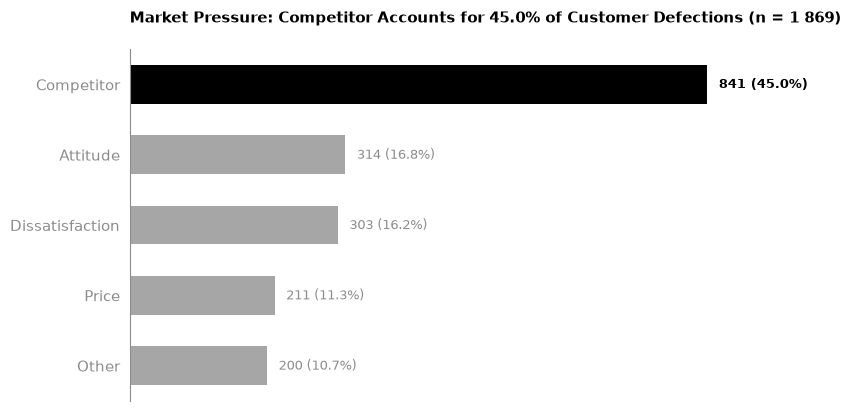

In [88]:
#  Extract series and summary metrics
s = churncat_freq["Frequency"]
total, top_cat, x_max = s.sum(), s.index[0], s.max()

# Canvas setup & horizontal bars (top driver in BLACK, rest in LIGHT_GRAY)
fig, ax = plt.subplots(figsize=(8.5, 4), layout="constrained")
bars = ax.barh(s.index, s.values, color=[BLACK if c == top_cat else LIGHT_GRAY for c in s.index], height=0.55)
ax.invert_yaxis()  # Rank largest category at the top

# Direct annotations over bars: "Count (Percentage)"
for bar, (cat, val) in zip(bars, s.items()):
    col, wt = (BLACK, "bold") if cat == top_cat else (DARK_GRAY, "normal")
    ax.text(val + x_max * 0.02, bar.get_y() + bar.get_height() / 2, 
            f"{val:,} ({val / total * 100:.1f}%)".replace(",", " "), va="center", color=col, weight=wt, fontsize=9)

# Axis cleanup & removal of redundant spines
ax.set_xticks([])
ax.set_xlim(0, x_max * 1.25)
ax.tick_params(colors=DARK_GRAY, left=False)
for spine in ["top", "right", "bottom"]: ax.spines[spine].set_visible(False)
ax.spines["left"].set_color(DARK_GRAY)

# IBCS Action Title
ax.set_title(f"Market Pressure: {top_cat} Accounts for {s.iloc[0] / total * 100:.1f}% of Customer Defections (n = {total:,})\n".replace(",", " "), loc="left", weight="bold", fontsize=11)
plt.show()

**What we see:**
- Competitor is by far the main reason: 45.0% of churned customers left for a competitor.
- Attitude (16.8%) and Dissatisfaction (16.2%) together explain about one third of churn. Both relate to service experience, so they are controllable.
- Price explains only 11.3%, so it is not the main driver of churn.

#### Churn Score

**What it is:** The predicted likelihood of a customer churning, from 0 to 100 (higher = higher risk). It comes from the IBM SPSS Modeler.

In [89]:
cscore = df_status["Churn Score"].copy()

cscore.describe().round(2)

print("Skew:", round(cscore.skew(), 2))
print("Kurtoss:", round(cscore.kurtosis(), 2))

Skew: -0.16
Kurtoss: -1.09


In [90]:
# Outliers with the IQR rule: outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
q1, q3 = cscore.quantile([0.25, 0.75])
iqr = q3 - q1

n_out = ((cscore < q1 - 1.5 * iqr) | (cscore > q3 + 1.5 * iqr)).sum()
print("IQR outliers:", n_out)

IQR outliers: 0


In [91]:
# Counts of the lowest scores: shows the gap between 9 and 20
cscore.value_counts().sort_index().head(10)

Churn Score
5      1
7      2
8      2
9      3
20    83
21    84
22    82
23    78
24    86
25    85
Name: count, dtype: int64

In [92]:
# Customers isolated from the bulk of the distribution
low_isolated = df_status[cscore < 20]
print(low_isolated["Customer Status"].value_counts())
print( f"{len(low_isolated)} customers ({len(low_isolated) / len(df_status):.2%}) with Churn Score < 20")

Customer Status
Stayed    8
Name: count, dtype: int64
8 customers (0.11%) with Churn Score < 20


The IQR rule flags **no outliers**, but this is a limitation of the rule: Churn Score is bounded between 0 and 100 and the lower fence (-13.25) is below the minimum possible value, so nothing can be flagged.
- Even so, there are **8 isolated customers (0.11%) with scores between 5 and 9**, separated from the rest by an empty gap (no customers with scores 10-19; from 20 onwards each score has about 80-100 customers). All 8 are `Stayed`.
- They look like genuine model predictions (very low risk) and not data errors, so they are kept.

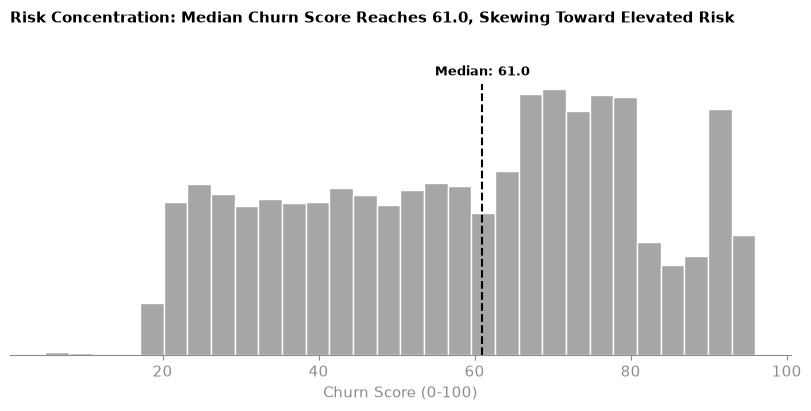

In [93]:
# Setup canvas
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")

# Histogram bars in neutral baseline gray
n, bins, patches = ax.hist(cscore, bins=30, color=LIGHT_GRAY, edgecolor="white")

# Vertical median reference line
med = cscore.median()
y_top = max(n) * 1.02
ax.vlines(med, 0, y_top, color=BLACK, lw=1.5, ls="--")

# Label placed directly at the top of the line
ax.text(
    med,
    y_top + max(n) * 0.02,
    f"Median: {med:.1f}",
    ha="center",
    va="bottom",
    color=BLACK,
    weight="bold",
    fontsize=9,
)

# IBCS decluttering of spines and ticks
ax.set_yticks([])
ax.set_ylim(0, max(n) * 1.15)
ax.set_xlabel("Churn Score (0-100)", color=DARK_GRAY)
ax.tick_params(colors=DARK_GRAY)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# Action Title
ax.set_title(
    f"Risk Concentration: Median Churn Score Reaches {med:.1f}, Skewing Toward Elevated Risk\n",
    loc="left",
    weight="bold",
    fontsize=11,
)
plt.show()

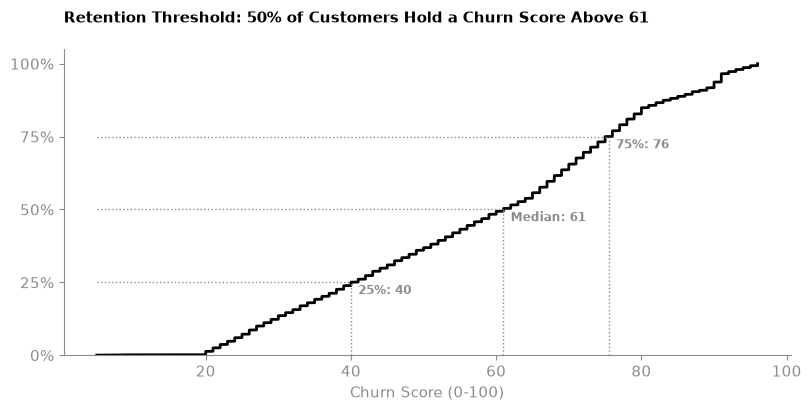

In [94]:
cs_sorted = cscore.sort_values()  # smallest to largest
cs_cum = np.arange(1, len(cs_sorted) + 1) / len(cs_sorted)  # share of customers up to each value

# Setup canvas
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(cs_sorted, cs_cum, color=BLACK, lw=2)

# Direct quantile markers instead of colored grid overlays
for q, lbl in [(0.25, "25%"), (0.50, "Median"), (0.75, "75%")]:
    val = cscore.quantile(q)
    ax.vlines(val, 0, q, color=DARK_GRAY, ls=":", lw=1)
    ax.hlines(q, cs_sorted.min(), val, color=DARK_GRAY, ls=":", lw=1)
    ax.text(val + 1, q - 0.04, f"{lbl}: {val:.0f}", color=DARK_GRAY, weight="bold", fontsize=8.5)

# Direct Y-axis formatting & minimal frame
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_ylim(0, 1.05)
ax.set_xlabel("Churn Score (0-100)", color=DARK_GRAY)
ax.tick_params(colors=DARK_GRAY)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
for s in ["left", "bottom"]: ax.spines[s].set_color(DARK_GRAY)

# Action Title
ax.set_title(f"Retention Threshold: 50% of Customers Hold a Churn Score Above {cscore.median():.0f}\n", loc="left", weight="bold", fontsize=11)
plt.show()

In [95]:
risk_bands = pd.cut(
    cscore,
    bins=[0, 39, 69, 100],
    labels=["Low (0-39)", "Medium (40-69)", "High (70-100)"],
    include_lowest=True,
)

risk_freq = pd.DataFrame(
    {
        "Frequency": risk_bands.value_counts().sort_index(),
        "Percentage (%)": (
            risk_bands.value_counts(normalize=True).sort_index() * 100
        ).round(2),
    }
)
print(risk_freq)

                Frequency  Percentage (%)
Churn Score                              
Low (0-39)           1679           23.84
Medium (40-69)       2799           39.74
High (70-100)        2565           36.42


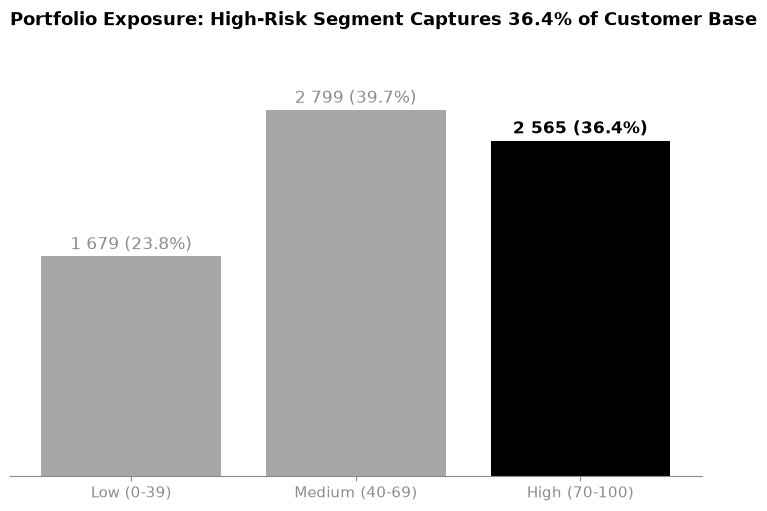

In [96]:
# Canvas setup (figura maior)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")

y_max = risk_freq["Frequency"].max()

# High-risk segment highlighted in black, others in light gray
colors = [BLACK if "High" in str(b) else LIGHT_GRAY for b in risk_freq.index]
bars = ax.bar(risk_freq.index, risk_freq["Frequency"], color=colors, width=0.8)  

# Direct data callouts: 'Count (Percentage)'
for i, (n, p) in enumerate(zip(risk_freq["Frequency"], risk_freq["Percentage (%)"])):
    col, wt = (BLACK, "bold") if "High" in str(risk_freq.index[i]) else (DARK_GRAY, "normal")
    ax.text(i, n + y_max * 0.02, f"{n:,} ({p:.1f}%)".replace(",", " "), ha="center", color=col, weight=wt, fontsize=12)

# Clean redundant axes and spines
ax.set_yticks([])
ax.set_ylim(0, y_max * 1.15)
ax.tick_params(colors=DARK_GRAY, labelsize=11)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# Action Title
high_pct = risk_freq.loc["High (70-100)", "Percentage (%)"]
ax.set_title(f"Portfolio Exposure: High-Risk Segment Captures {high_pct:.1f}% of Customer Base\n", loc="left", weight="bold", fontsize=13)
plt.show()

**What we see:**
- Scores go from 5 to 96. The mean (58.5) is a bit below the median (61), so the distribution is almost symmetric with a slight skew to the left (skew -0.16).
- The values are very spread out (std 21.2) and the shape is flat-topped (kurtosis -1.09), so the score separates customers well instead of clustering around one value.
- Half of the customers are between 40 (25%) and 75.5 (75%).
- With the illustrative bands, 36.4% of customers are in the high-risk zone (70-100) and 23.8% in the low-risk zone (0-39).

#### 1.5 Cross-Dataset Relationships

These analyses use the merged `TELCO` table built in 0.3.

#### 1.5.1 Dependents vs Total Revenue: Household Spend Analysis

#### Block 1 - Dependents vs Total Revenue: Do customers with dependents generate more revenue for the company?

In [97]:
# Summary table
order = ["No", "Yes"]
summary = (
    TELCO.groupby("Dependents")["Total Revenue"]
    .agg(["count", "mean", "median", "std"])
    .loc[order]
    .round(0)
)
print(summary)

            count    mean  median     std
Dependents                               
No           5416  2957.0  1998.0  2853.0
Yes          1627  3293.0  2435.0  2890.0


In [98]:
# Statistical test (non-parametric because of the skew)
rev_yes = TELCO.loc[TELCO["Dependents"] == "Yes", "Total Revenue"]
rev_no = TELCO.loc[TELCO["Dependents"] == "No", "Total Revenue"]

# Revenue Cell
u, p = stats.mannwhitneyu(rev_yes, rev_no, alternative="two-sided")
rank_biserial = 2 * u / (len(rev_yes) * len(rev_no)) - 1 

print(f" [Total Revenue] Mann-Whitney p-value: {p:.4g} | rank-biserial effect size: {rank_biserial:.3f}")

 [Total Revenue] Mann-Whitney p-value: 1.417e-08 | rank-biserial effect size: 0.093


In [99]:
order = ["No", "Yes"]
g = TELCO.groupby("Dependents")["Total Revenue"]
means = g.mean().loc[order]
medians = g.median().loc[order]
ci95 = (g.sem() * 1.96).loc[order]  # 95% confidence interval (normal approx.)

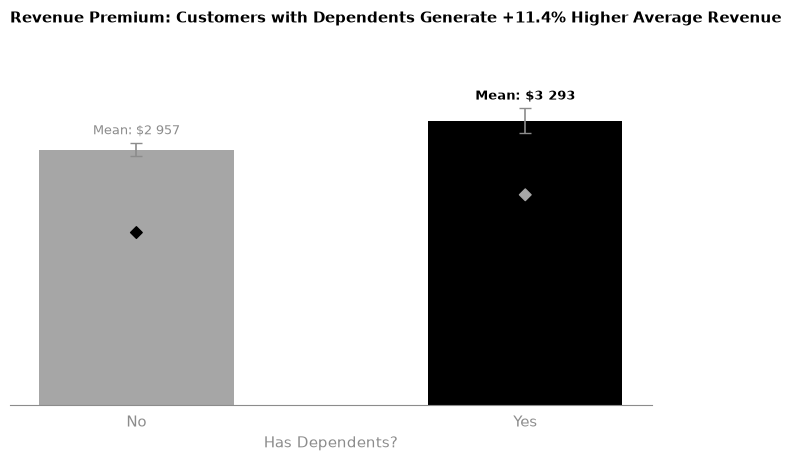

In [100]:
y_max = max(means + ci95)

# Canvas and horizontal/vertical bars setup
fig, ax = plt.subplots(figsize=(6.5, 4.5), layout="constrained")
colors = [LIGHT_GRAY if x == "No" else BLACK for x in order]
bars = ax.bar(order, means, yerr=ci95, capsize=4, color=colors, width=0.5, error_kw={"ecolor": DARK_GRAY, "lw": 1.2})

# Contrast-aware median markers (Black diamond on gray, White on black)
ax.scatter(order, medians, color=[BLACK if x == "No" else LIGHT_GRAY for x in order], marker="D", s=35, zorder=3)

# Direct data annotations: Mean values only
for bar, m, err, grp in zip(bars, means, ci95, order):
    col, wt = (BLACK, "bold") if grp == "Yes" else (DARK_GRAY, "normal")
    ax.text(bar.get_x() + bar.get_width() / 2, m + err + y_max * 0.03, f"Mean: ${m:,.0f}".replace(",", " "), ha="center", color=col, weight=wt, fontsize=9)

# Axis decluttering and baseline formatting
ax.set_yticks([])
ax.set_ylim(0, y_max * 1.2)
ax.set_xlabel("Has Dependents?", color=DARK_GRAY)
ax.tick_params(colors=DARK_GRAY, bottom=False)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# Action Title
diff_pct = ((means["Yes"] - means["No"]) / means["No"]) * 100
ax.set_title(f"Revenue Premium: Customers with Dependents Generate +{diff_pct:.1f}% Higher Average Revenue\n", loc="left", weight="bold", fontsize=11)
plt.show()

Customers with dependents generate more revenue overall (mean $3,293 vs $2,957, +11%). The difference is statistically significant (Mann-Whitney p < 0.001) but small (rank-biserial r = 0.09). This gap may come from how long they stay rather than from higher spending, which is analysed in the next blocks.

##### Block 2 — Dependents vs Tenure in Months: Do customers with dependents stay longer with the company than those without? And why?

In [101]:
ten_yes = TELCO.loc[TELCO["Dependents"] == "Yes", "Tenure in Months"]
ten_no = TELCO.loc[TELCO["Dependents"] == "No", "Tenure in Months"]

# Summary
order = ["No", "Yes"]
summary = (
    TELCO.groupby("Dependents")["Tenure in Months"]
    .agg(["count", "mean", "median", "std"])
    .loc[order]
    .round(1)
)
print(summary)

            count  mean  median   std
Dependents                           
No           5416  30.6    26.0  24.4
Yes          1627  38.3    39.0  24.1


In [102]:
# Statistical test (non-parametric, same approach as for Total Revenue)
u, p = stats.mannwhitneyu(ten_yes, ten_no, alternative="two-sided")
rb = 2 * u / (len(ten_yes) * len(ten_no)) - 1
print(f"\n [Tenure in Months] Mann-Whitney p-value: {p:.4g} | rank-biserial: {rb:.3f}")



 [Tenure in Months] Mann-Whitney p-value: 4.454e-31 | rank-biserial: 0.189


In [103]:
diff = ten_yes.mean() - ten_no.mean()
print(f"\n Mean difference (Yes - No): {diff:+.1f} months")


 Mean difference (Yes - No): +7.7 months


In [104]:
# Contract type by Dependents (row %)
print(pd.crosstab(TELCO["Dependents"], TELCO["Contract"], normalize="index").round(3)* 100)

Contract    Month-to-Month  One Year  Two Year
Dependents                                    
No                    55.4      21.8      22.8
Yes                   37.6      22.6      39.9


In [105]:
# Does the tenure gap persist within each contract type?
print(
    TELCO.groupby(["Contract", "Dependents"])["Tenure in Months"]
    .agg(["count", "mean"])
    .round(1)
    .unstack("Dependents")
    .swaplevel(axis=1)
    .sort_index(axis=1)
)

Dependents        No         Yes      
               count  mean count  mean
Contract                              
Month-to-Month  2999  16.8   611  20.2
One Year        1183  40.9   367  42.4
Two Year        1234  54.4   649  53.1


In [106]:
# Get contract types
contracts = df_services["Contract"].unique().tolist().copy()

# Mean tenure by contract and Dependents
tenure = TELCO.pivot_table(
    index="Contract", columns="Dependents", values="Tenure in Months", aggfunc="mean"
).loc[contracts, order].copy()

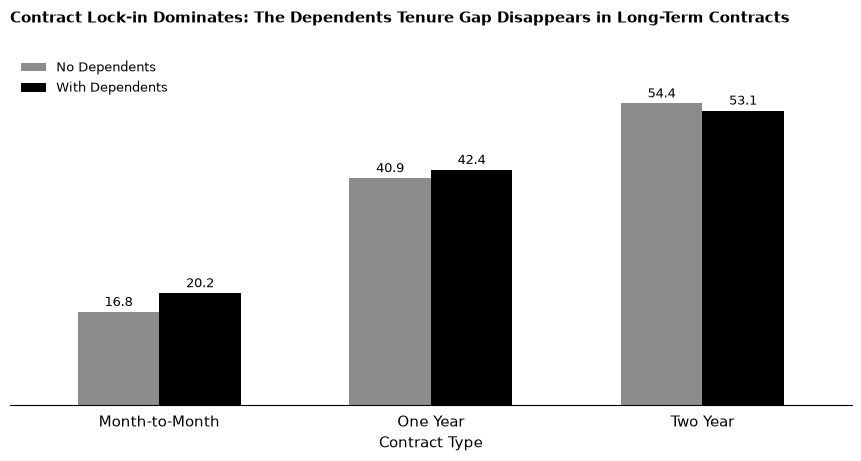

In [107]:
y_max = tenure.values.max()

# Canvas and grouped bars
fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
tenure.plot(kind="bar", ax=ax, color=[DARK_GRAY, BLACK], width=0.6, edgecolor="none")

# Direct numeric annotations
for c in ax.containers:
    for b in c:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + y_max * 0.02, f"{b.get_height():.1f}", ha="center", color=BLACK, fontsize=9)

# Spines, ticks, and legend cleanup
ax.set_yticks([])
ax.set_ylim(0, y_max * 1.18)
ax.set_xlabel("Contract Type", color=BLACK)
ax.tick_params(colors=BLACK, rotation=0, bottom=False)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BLACK)
ax.legend(["No Dependents", "With Dependents"], loc="upper left", frameon=False, fontsize=9, labelcolor=BLACK)

# Action title
ax.set_title("Contract Lock-in Dominates: The Dependents Tenure Gap Disappears in Long-Term Contracts\n", loc="left", weight="bold", fontsize=11)
plt.show()

##### Block 3 — Revenue with the Same Tenure

When holding tenure constant, does the presence of dependents still drive higher revenue?

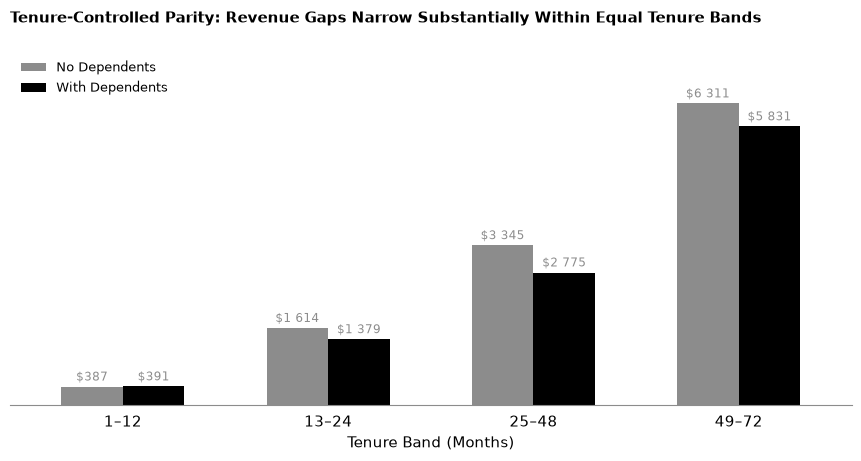

In [108]:
pivot = TELCO.pivot_table(
    index=bands,
    columns="Dependents",
    values="Total Revenue",
    aggfunc="mean",
    observed=True,
)[order]

y_max = pivot.values.max()

# Canvas and grouped bars
fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
pivot.plot(kind="bar", ax=ax, color=[DARK_GRAY, BLACK], width=0.6, edgecolor="none")

# Direct numeric currency annotations
for c in ax.containers:
    for b in c:
        val = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, val + y_max * 0.02, f"${val:,.0f}".replace(",", " "), ha="center", color=DARK_GRAY, fontsize=8.5)

# Spines, ticks, and legend cleanup
ax.set_yticks([])
ax.set_ylim(0, y_max * 1.18)
ax.set_xlabel("Tenure Band (Months)", color=BLACK)
ax.tick_params(colors=BLACK, rotation=0, bottom=False)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)
ax.legend(["No Dependents", "With Dependents"], loc="upper left", frameon=False, fontsize=9, labelcolor=BLACK)

# Action title
ax.set_title("Tenure-Controlled Parity: Revenue Gaps Narrow Substantially Within Equal Tenure Bands\n", loc="left", weight="bold", fontsize=11)
plt.show()

In [109]:
TELCO["Revenue per Month"] = TELCO["Total Revenue"] / TELCO["Tenure in Months"]

print(
    TELCO.groupby("Dependents")[["Monthly Charge", "Revenue per Month"]]
    .agg(["mean", "median"])
    .round(1)
)
print("\n")
# Offers received by Dependents (row %)
print(pd.crosstab(TELCO["Dependents"], TELCO["Offer"], normalize="index").round(3) * 100)

           Monthly Charge        Revenue per Month       
                     mean median              mean median
Dependents                                               
No                   67.1   73.9              90.6   96.4
Yes                  56.8   55.3              79.8   76.0


Offer       Offer A  Offer B  Offer C  Offer D  Offer E
Dependents                                             
No             14.9     25.0     12.7     18.7     28.6
Yes            21.4     29.3     14.4     20.1     14.9


### Conclusion: Dependents vs Total Revenue

Customers with dependents generate more revenue overall (mean $3,293 vs $2,957, +11%), but the effect is small (rank-biserial r = 0.09, p < .001). The gap is explained by tenure, not by higher spending:

- **They stay longer:** mean tenure is 38.3 vs 30.6 months (r = 0.19, about twice the revenue effect). A likely reason is contract type: 39.9% of them are on two-year contracts, vs 22.8% of customers without dependents.
- **They pay less per month:** mean Monthly Charge is $56.8 vs $67.1, and revenue per month is $79.8 vs $90.6.
- **At equal tenure they are worth equal or less:** the two groups are identical in the first year ($391 vs $387).
The justification for this lower revenue at equal tenure is that customers with dependents receives in general more offers (except in Offer E).

Dependents are therefore a marker of stable, long-lived but lower-value-per-month customers, not of higher-value ones. This is an association: the data cannot show whether dependents lead customers to choose longer contracts.

#### 1.5.2 Marital Status vs Total Revenue & Total Charges

#### Block 1 : Married vs Total Charges / Total Revenue

In [110]:
order = ["No", "Yes"]
var_revenue = ["Total Charges", "Total Revenue"]

summary = (
    TELCO.groupby("Married")[var_revenue]
    .agg(["mean", "median"])
    .round(2)
)

print(summary)

        Total Charges          Total Revenue         
                 mean   median          mean   median
Married                                              
No            1584.32   811.65       2121.96  1175.80
Yes           3025.35  2341.85       4010.90  3330.08


In [111]:
# Mann-Whitney test
mw_results = {}
for m in var_revenue:
    yes = TELCO.loc[TELCO["Married"] == "Yes", m]
    no = TELCO.loc[TELCO["Married"] == "No", m]
    
    stat, p_val = stats.mannwhitneyu(yes, no)
    mw_results[m] = p_val

print("p-values (Mann-Whitney)")
for metric, p in mw_results.items():
    print(f"{metric}: p = {p:.4e}")

p-values (Mann-Whitney)
Total Charges: p = 6.4715e-181
Total Revenue: p = 2.2836e-192


In [112]:
# Effect size (Rank-biserial correlation)
effect_sizes = {}
for m in var_revenue:
    yes = TELCO.loc[TELCO["Married"] == "Yes", m]
    no = TELCO.loc[TELCO["Married"] == "No", m]
    
    u, _ = stats.mannwhitneyu(yes, no)
    r = (2 * u / (len(yes) * len(no))) - 1
    effect_sizes[m] = round(r, 3)

print("Effect Size (Rank-Biserial)")
for metric, r in effect_sizes.items():
    print(f"{metric}: r = {r}")

Effect Size (Rank-Biserial)
Total Charges: r = 0.395
Total Revenue: r = 0.407


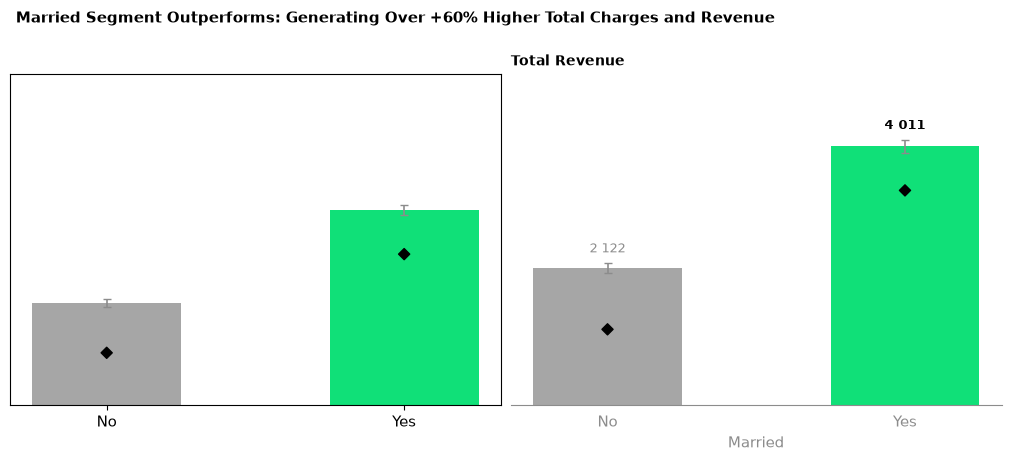

In [113]:
# Setup 2-panel canvas with shared y-axis and IBCS layout
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True, layout="constrained")

for ax, m in zip(axes, var_revenue):
    # Compute group statistics and 95% confidence intervals
    g = TELCO.groupby("Married")[m]
    means, medians = g.mean().loc[order], g.median().loc[order]
    ci = (g.sem() * 1.96).loc[order]

    # Render mean bars and overlay median markers
    bars = ax.bar(
        order,
        means,
        yerr=ci,
        capsize=3,
        color=[LIGHT_GRAY, GREEN],
        width=0.5,
        error_kw={"ecolor": DARK_GRAY, "lw": 1.2},
    )
    ax.scatter(order, medians, color=[BLACK, BLACK], marker="D", s=32, zorder=3)

# Format direct data labels above error bars
for b, val, err, c, wt in zip(
    bars, means, ci, [DARK_GRAY, BLACK], ["normal", "bold"]
):
    ax.text(
        b.get_x() + 0.25,
        val + err + max(means + ci) * 0.03,
        f"{val:,.0f}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=9,
        color=c,
        weight=wt,
        )

# Subpanel labels and spine cleanup
ax.set_title(m, loc="left", fontsize=10, weight="bold", color=BLACK)
ax.set_xlabel("Married", color=DARK_GRAY)
ax.set_yticks([])
ax.tick_params(colors=DARK_GRAY, bottom=False)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

# Headroom adjustment and executive message title
axes[0].set_ylim(0, max(means + ci) * 1.25)
fig.suptitle(
    "Married Segment Outperforms: Generating Over +60% Higher Total Charges and Revenue\n",
    x=0.01,
    ha="left",
    fontsize=11,
    weight="bold",
)
plt.show()

##### Block 2 — Does the Result Hold across Equal Tenure?

In [114]:
# Tenure Stats
t_yes, t_no = [TELCO.loc[TELCO["Married"] == k, "Tenure in Months"] for k in ["Yes", "No"]]
u, p = stats.mannwhitneyu(t_yes, t_no)

print(TELCO.groupby("Married")["Tenure in Months"].agg(["count", "mean", "median"]).loc[order].round(1))
print(f"\n[Tenure] p: {p:.4e} | rank-biserial: {(2 * u / (len(t_yes) * len(t_no))) - 1:.3f}")

         count  mean  median
Married                     
No        3641  23.4    16.0
Yes       3402  42.0    46.0

[Tenure] p: 6.7528e-231 | rank-biserial: 0.446


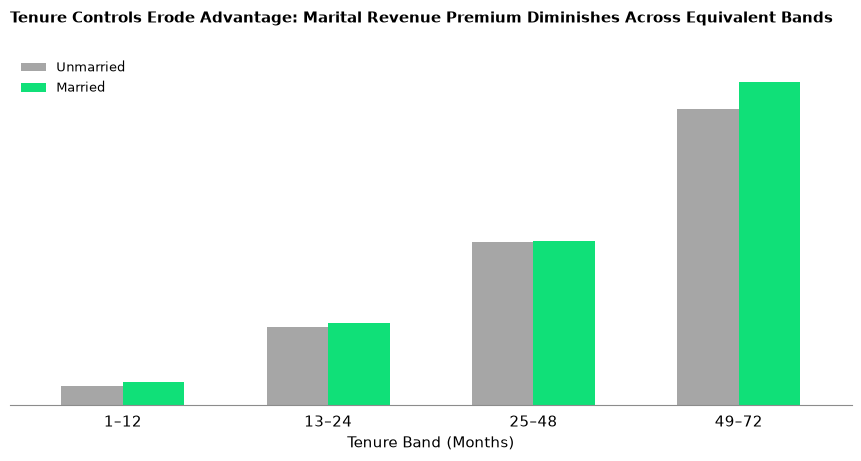

In [115]:
# IBCS Pivot Chart
pivot = TELCO.pivot_table(
    index=bands,
    columns="Married",
    values="Total Revenue",
    aggfunc="mean",
    observed=True,
)[order]

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
pivot.plot(
    kind="bar",
    ax=ax,
    color=[LIGHT_GRAY, GREEN],
    width=0.6,
    edgecolor="none",
)

# Layout & Action Title
ax.set_yticks([])
ax.set_ylim(0, pivot.values.max() * 1.1)
ax.set_xlabel("Tenure Band (Months)", color=BLACK)
ax.tick_params(colors=BLACK, rotation=0, bottom=False)

for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(DARK_GRAY)

ax.legend(
    ["Unmarried", "Married"],
    loc="upper left",
    frameon=False,
    fontsize=9,
    labelcolor=BLACK,
)
ax.set_title(
    "Tenure Controls Erode Advantage: Marital Revenue Premium Diminishes Across Equivalent Bands\n",
    loc="left",
    weight="bold",
    fontsize=11,
)

plt.show()

### Conclusion: Married vs Total Charges / Total Revenue

Married customers generate substantially more revenue overall (mean Total Revenue $4,011 vs $2,122, +89%; median $3,330 vs $1,176). The difference is statistically significant (Mann-Whitney p < 0.001) and moderate in size (rank-biserial r = 0.41), about four times the effect found for Dependents (r = 0.09). Total Charges gives the same result (r = 0.40), as expected, since Total Revenue is derived from it.

Most of this gap comes from tenure: married customers stay much longer (mean [42.0] vs [23.4] months, r = [0.446]). When customers are compared within the same tenure band, the gap shrinks to nothing or a small advantage for married customers (0% at 25–48 months, roughly 5–10% at 13–24 and 49–72 months, and about 20% in the first year, where the amounts are small). Being married is therefore mainly a marker of long-lived customers, with at most a small additional advantage in value per customer. This is an association, and the data cannot show why.

#### 1.5.3 Referred a Friend vs Churn Score

Customers who referred a friend are expected to be more engaged with the company, so a lower Churn Score (lower predicted risk) is expected for them.

##### Block 1 — Referred a Friend vs Churn Score

Do customers who referred a friend have a lower predicted churn risk?

In [116]:
# Summary table
order = ["No", "Yes"]
print(
    TELCO.groupby("Referred a Friend")["Churn Score"]
    .agg(["count", "mean", "median", "std"])
    .loc[order]
    .round(1)
)

                   count  mean  median   std
Referred a Friend                           
No                  3821  60.6    65.0  21.3
Yes                 3222  56.0    57.0  20.7


In [117]:
# Statistical test (non-parametric: Churn Score is bounded 0-100)
cs_yes = TELCO.loc[TELCO["Referred a Friend"] == "Yes", "Churn Score"]
cs_no = TELCO.loc[TELCO["Referred a Friend"] == "No", "Churn Score"]

u, p = stats.mannwhitneyu(cs_yes, cs_no, alternative="two-sided")
rank_biserial = 2 * u / (len(cs_yes) * len(cs_no)) - 1  # effect size, -1 to 1

print(
    f"\n[Churn Score] Mann-Whitney p-value: {p:.4g} | rank-biserial: {rank_biserial:.3f}"
)


[Churn Score] Mann-Whitney p-value: 5.843e-20 | rank-biserial: -0.126


In [118]:
# Aggregate descriptive metrics for left panel
g = TELCO.groupby("Referred a Friend")["Churn Score"]
means, medians = g.mean().loc[order], g.median().loc[order]
ci95 = (g.sem() * 1.96).loc[order]

# Bin churn scores and compute percentage distribution for right panel
edges = np.arange(0, 101, 10)
labels = [f"{a}-{b}" for a, b in zip(edges[:-1], edges[1:])]
TELCO["Churn Score Range"] = pd.cut(TELCO["Churn Score"], edges, labels=labels, right=False, include_lowest=True)

counts = pd.crosstab(TELCO["Churn Score Range"], TELCO["Referred a Friend"]).reindex(index=labels, columns=order, fill_value=0)
pct = (counts / counts.sum() * 100).round(1)

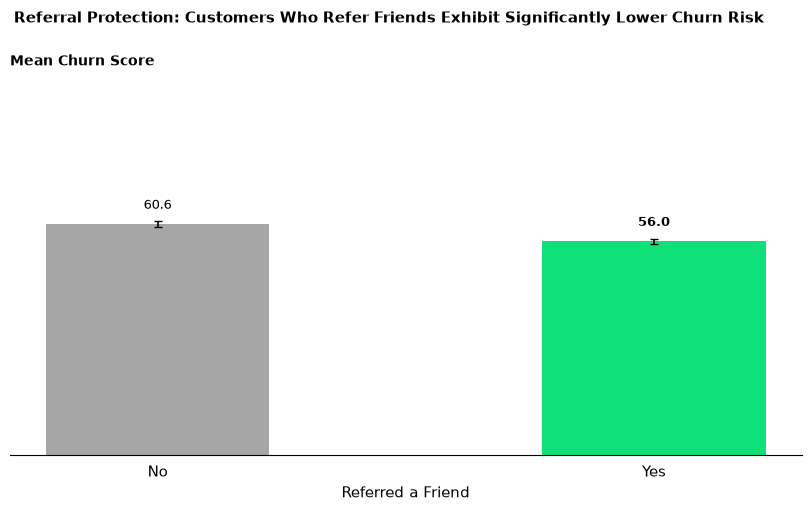

In [119]:
# Setup canvas (width equal to the title)
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
colors = [LIGHT_GRAY, GREEN]

# Mean comparison without median marker
bars = ax.bar(order, means, yerr=ci95, capsize=3, color=colors, width=0.45, error_kw={"ecolor": BLACK, "lw": 1.2})

for b, val, err, c, wt in zip(bars, means, ci95, [BLACK, BLACK], ["normal", "bold"]):
    ax.text(b.get_x() + b.get_width() / 2, val + err + 2.5, f"{val:.1f}", ha="center", va="bottom", fontsize=9.5, color=c, weight=wt)

ax.set_ylim(0, 100)
ax.set_title("Mean Churn Score", loc="left", fontsize=10, weight="bold", color=BLACK)
ax.set_xlabel("Referred a Friend", color=BLACK)

# Axis cleanup and spine removal
ax.set_yticks([])
ax.tick_params(colors=BLACK, bottom=False)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BLACK)

# Action Title
fig.suptitle("Referral Protection: Customers Who Refer Friends Exhibit Significantly Lower Churn Risk\n", x=0.01, ha="left", fontsize=11, weight="bold")
plt.show()

The results suggest that customers who did not refer a friend tend to have a higher concentration of elevated Churn Scores, particularly in the 80–100 ranges. This may indicate an association between a higher risk of customer churn and a lower likelihood of recommending the company. However, this relationship does not necessarily imply causation.

"The chart demonstrates that making a referral does not make a customer immune to churn. Although customers who refer friends have, on average, a lower overall risk profile (as seen in the 20–60 ranges), they remain susceptible to standard attrition drivers.
Factors such as contract expirations, price sensitivity, or changing personal needs affect all users universally. This explains why both groups share a synchronized peak in the high-risk 70–80 range, proving that historical advocacy (referring a friend) does not permanently guarantee long-term retention."

##### Block 2 — Does the Result Remain the Same with Similar Customers?

Referrers may simply be customers with longer tenure or longer contracts, which already lowers churn risk. We check whether the gap persists within tenure bands and contract types.

In [120]:
# Pivot mean Churn Score controlled by the Tenure Band and Contract
by_band = TELCO.pivot_table(index=bands, columns="Referred a Friend", values="Churn Score", aggfunc="mean", observed=True)[order]
by_contract = TELCO.pivot_table(index="Contract", columns="Referred a Friend", values="Churn Score", aggfunc="mean")[order]

# Calculate subgroup gaps (Yes - No)
for df in (by_band, by_contract):
    df["Gap (Yes-No)"] = df["Yes"] - df["No"]

print(by_band.round(1), "\n")
print(by_contract.round(1))

Referred a Friend    No   Yes  Gap (Yes-No)
Tenure in Months                           
1–12               65.3  62.6          -2.7
13–24              58.7  58.8           0.1
25–48              58.0  57.3          -0.7
49–72              54.3  52.3          -1.9 

Referred a Friend    No   Yes  Gap (Yes-No)
Contract                                   
Month-to-Month     65.3  63.5          -1.8
One Year           52.7  53.9           1.2
Two Year           52.1  50.2          -1.9


In [121]:
# Spearman rank correlation: referral volume vs. churn risk
rho, p_rho = stats.spearmanr(TELCO["Number of Referrals"], TELCO["Churn Score"])

print(f"Spearman (Number of Referrals vs Churn Score): rho = {rho:.3f}, p = {p_rho:.4e}")

Spearman (Number of Referrals vs Churn Score): rho = -0.168, p = 6.3715e-46


#### Conclusion: Referred a Friend vs Churn Score

Customers who referred a friend have a lower Churn Score overall (mean 56.0 vs 60.6, a difference of −4.6 points; Mann-Whitney p = 5.843e-20, rank-biserial r = -0.126), and non-referrers are more concentrated in the 80–100 ranges.

Part of this gap comes from tenure and contract, not from the referral itself. When customers are compared within the same group, the difference shrinks to between −2.7 and +1.2 points:

- **By tenure band:** −2.7 (1–12 months), +0.1 (13–24), −0.7 (25–48) and −1.9 (49–72).
- **By contract:** −1.8 (Month-to-Month), +1.2 (One Year) and −1.9 (Two Year).

The direction is mostly the same (5 of 7 groups favour referrers), but the effect is small and inconsistent, with two groups showing no gap or a reversed one (13–24 months and One Year).

Number of Referrals has a weak negative relation with the Churn Score (Spearman rho = −0.168, p < 0.001). The p-value is very small mainly because of the sample size, while the relation itself is weak: customers with more referrals tend to have lower scores, but the number of referrals explains very little of the score.

**For modelling:** Referred a Friend and Number of Referrals carry a small signal that overlaps with tenure and contract, so they are reasonable candidate features but unlikely to add much beyond them. Their real contribution should be confirmed in the model (for example with feature importance or by comparing performance with and without them). This is an association, and the data cannot show whether referring a friend reduces churn.

#### 1.5.4 Offer vs Churn Score

Customers who received an offer are expected to have a lower Churn Score than those who did not. We also check whether Offer A stands out.

In [122]:
# Offer vs Churn Score
TELCO["Offer"] = TELCO["Offer"].fillna("None")  # "None" can be read as missing
offer_order = ["None", "Offer A", "Offer B", "Offer C", "Offer D", "Offer E"]
offer_order = [o for o in offer_order if o in TELCO["Offer"].unique()]

In [123]:
# Summary: size, share and Churn Score per offer
summary = (
    TELCO.groupby("Offer")["Churn Score"]
    .agg(["count", "mean", "median", "std"])
    .loc[offer_order]
)
summary.insert(1, "% customers", (summary["count"] / len(TELCO) * 100).round(1))
print(summary.round(1))

         count  % customers  mean  median   std
Offer                                          
None      3877         55.0  58.6    61.0  21.2
Offer A    520          7.4  50.9    52.0  19.2
Offer B    824         11.7  54.8    56.0  20.0
Offer C    415          5.9  58.2    60.0  20.5
Offer D    602          8.5  58.4    62.0  20.9
Offer E    805         11.4  66.7    71.0  21.0


In [124]:
# Tests
groups = [TELCO.loc[TELCO["Offer"] == o, "Churn Score"] for o in offer_order]
H, p_kw = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(TELCO) - len(groups))  # effect size (epsilon²)
print(f"\nKruskal-Wallis (all offers): p = {p_kw:.4g} | epsilon² = {eps2:.3f}")

has_offer = TELCO["Offer"] != "None"
u, p_any = stats.mannwhitneyu(
    TELCO.loc[has_offer, "Churn Score"],
    TELCO.loc[~has_offer, "Churn Score"],
    alternative="two-sided",
)
rb = 2 * u / (has_offer.sum() * (~has_offer).sum()) - 1
print(f"Any offer vs None: Mann-Whitney p = {p_any:.4g} | rank-biserial = {rb:.3f}")

# Does Offer A stand out? Offer mix in low-risk vs high-risk customers (% of each group)
risk = pd.cut(
    TELCO["Churn Score"],
    [0, 39, 69, 100],
    labels=["Low (0-39)", "Medium (40-69)", "High (70-100)"],
    include_lowest=True,
)
print("\nOffer mix by risk band (column %):")
print(
    (pd.crosstab(TELCO["Offer"], risk, normalize="columns") * 100)
    .loc[offer_order]
    .round(1)
)

# Are offers linked to tenure? (possible confounder)
print("\nMean tenure by offer:")
print(TELCO.groupby("Offer")["Tenure in Months"].mean().loc[offer_order].round(1))


Kruskal-Wallis (all offers): p = 2.02e-46 | epsilon² = 0.031
Any offer vs None: Mann-Whitney p = 0.4702 | rank-biserial = -0.010

Offer mix by risk band (column %):
Churn Score  Low (0-39)  Medium (40-69)  High (70-100)
Offer                                                 
None               54.7            54.2           56.2
Offer A            10.4             8.7            4.0
Offer B            12.9            13.4            9.0
Offer C             5.7             6.5            5.4
Offer D             9.0             8.3            8.6
Offer E             7.3             9.0           16.8

Mean tenure by offer:
Offer
None       31.6
Offer A    70.0
Offer B    53.4
Offer C    30.8
Offer D    16.0
Offer E     3.7
Name: Tenure in Months, dtype: float64


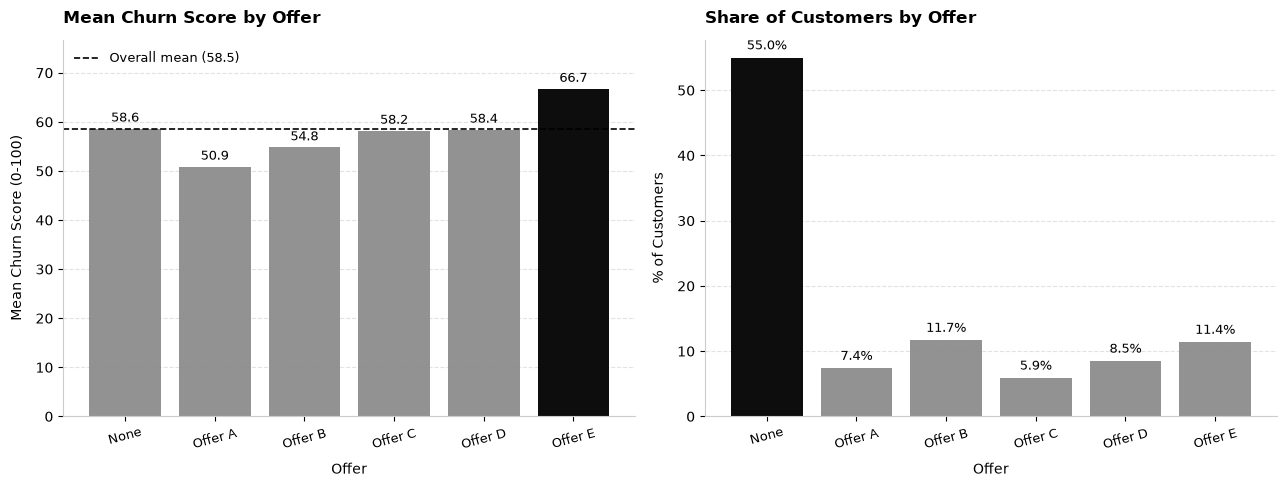

In [125]:
# Graph: mean Churn Score by offer + share of customers per offer
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left panel: Mean Churn Score by Offer
colors1 = [BLACK if v == summary["mean"].max() else DARK_GRAY
           for v in summary["mean"]]
bars1 = axes[0].bar(
    offer_order, summary["mean"], color=colors1, linewidth=0, alpha=0.95
)
overall_mean = TELCO["Churn Score"].mean()
axes[0].axhline(
    overall_mean, color=BLACK, ls="--", lw=1.2, label=f"Overall mean ({overall_mean:.1f})"
)

for b, v in zip(bars1, summary["mean"]):
    axes[0].text(
        b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}", ha="center", va="bottom", fontsize=9, color=BLACK
    )

axes[0].set_title("Mean Churn Score by Offer", fontsize=12, fontweight="bold", pad=12, loc="left")
axes[0].set_xlabel("Offer", fontsize=10, labelpad=8)
axes[0].set_ylabel("Mean Churn Score (0-100)", fontsize=10, labelpad=8)
axes[0].set_ylim(0, summary["mean"].max() * 1.15)   
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[0].grid(axis="y", linestyle="--", alpha=0.25, color=DARK_GRAY)
axes[0].set_axisbelow(True)


# Right panel: Share of customers by Offer
colors2 = [BLACK if v == summary["% customers"].max() else DARK_GRAY
           for v in summary["% customers"]]
bars2 = axes[1].bar(
    offer_order, summary["% customers"], color=colors2, linewidth=0, alpha=0.95
)

for b, v in zip(bars2, summary["% customers"]):
    axes[1].text(
        b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=BLACK
    )

axes[1].set_title("Share of Customers by Offer", fontsize=12, fontweight="bold", pad=12, loc="left")
axes[1].set_xlabel("Offer", fontsize=10, labelpad=8)
axes[1].set_ylabel("% of Customers", fontsize=10, labelpad=8)
axes[1].grid(axis="y", linestyle="--", alpha=0.25, color=DARK_GRAY)
axes[1].set_axisbelow(True)


for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")
    ax.tick_params(axis="x", rotation=15, labelsize=9)  # Rotation for readability in case the offer names are long
    ax.tick_params(axis="y", labelsize=10)

plt.tight_layout()
plt.show()
 

### Conclusion: Offer vs Churn Score

**Receiving an offer, by itself, is not associated with a lower Churn Score.** Customers with any offer and customers with no offer have practically the same scores (Mann-Whitney p = 0.47, rank-biserial r = −0.01), so the expectation that "more offers means lower risk" is not supported. The Churn Score does differ between offer types (Kruskal-Wallis p < 0.001), but the effect is small (epsilon² = 0.031). Offers A and B have lower means (50.9 and 54.8), Offer E is clearly higher (66.7), and None, C and D stay close to the overall mean (58.2–58.6).

**Offer A stands out for low risk, but only for a small group.** It reaches just 7.4% of customers, yet it represents 10.4% of the low-risk band against 4.0% of the high-risk band, and it has the lowest mean score. Offer E is the opposite: 7.3% of the low-risk band against 16.8% of the high-risk band.

**Tenure explains most of this pattern.** Offer A customers have a mean tenure of 70 months, against 31.6 for customers with no offer, and Offer B has 53.4. Offer E customers are very recent (3.7 months), and Offer D also has short tenure (16.0). The offers therefore seem to be given to different stages of the customer lifecycle, and the score differences largely reflect tenure, which we already know lowers churn risk.

**For modelling:** Offer carries some signal, but it largely overlaps with tenure, so it is a reasonable candidate feature that should add little beyond it. This is consistent with Offer A having a low churn rate in the EDA but a positive coefficient in the logistic regression. This is an association: the data cannot show whether the offers themselves reduce churn, because they were not assigned at random.

#### 1.5.5 Payment Method vs Churn Score and Customer Status

Payment method is expected to be linked to churn risk (automatic payments tend to keep customers longer). We check it against the Churn Score, against the real Customer Status, and then cross it with tenure in a heatmap.

In [126]:
# Payment Method vs Churn Score (methods ordered from the lowest to the highest score)
obs = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
obs["churn"] = (obs["Customer Status"] == "Churned").astype(int)
pay_order = (
    obs.groupby("Payment Method")["Churn Score"].mean().sort_values().index.tolist()
)

print(
    obs.groupby("Payment Method")["Churn Score"]
    .agg(["count", "mean", "median"])
    .loc[pay_order]
    .round(1)
)

                 count  mean  median
Payment Method                      
Credit Card       2518  55.4    56.0
Bank Withdrawal   3728  61.5    66.0
Mailed Check       343  62.0    66.0


In [127]:
# Payment Method vs Customer Status (actual churn rate)
churn_rate = (
    obs.groupby("Payment Method")["churn"].agg(["count", "mean"]).loc[pay_order]
)
churn_rate["mean"] = (churn_rate["mean"] * 100).round(1)
print("\nTaxa de churn por Payment Method:")
print(churn_rate.rename(columns={"count": "customers", "mean": "churn rate (%)"}))

# Tenure médio por método (para perceber se o tenure explica a diferença)
print("\nTenure médio por Payment Method:")
print(obs.groupby("Payment Method")["Tenure in Months"].mean().loc[pay_order].round(1))


Taxa de churn por Payment Method:
                 customers  churn rate (%)
Payment Method                            
Credit Card           2518            15.8
Bank Withdrawal       3728            35.6
Mailed Check           343            41.4

Tenure médio por Payment Method:
Payment Method
Credit Card        37.1
Bank Withdrawal    34.0
Mailed Check       21.3
Name: Tenure in Months, dtype: float64


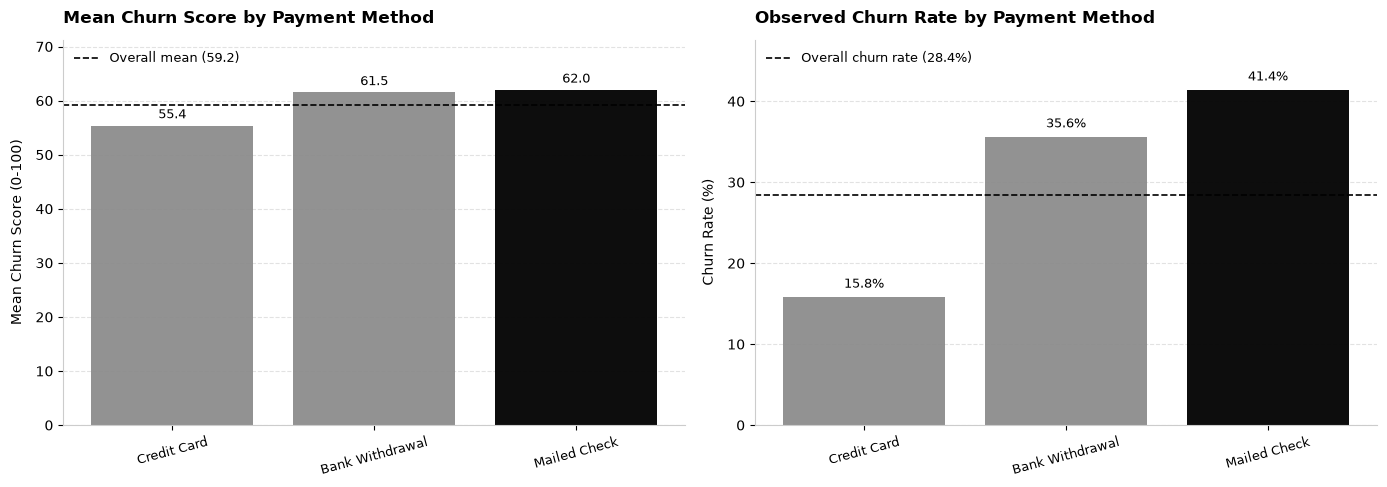

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: mean Churn Score by method
means = obs.groupby("Payment Method")["Churn Score"].mean().loc[pay_order]
overall_mean_churn = obs["Churn Score"].mean()
axes[0].axhline(
    overall_mean_churn, color=BLACK, ls="--", lw=1.2, label=f"Overall mean ({overall_mean_churn:.1f})"
)

colors1 = [BLACK if v == means.max() else DARK_GRAY for v in means]
bars1 = axes[0].bar(pay_order, means, color=colors1, linewidth=0, alpha=0.95)

for b, v in zip(bars1, means):
    axes[0].text(
        b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}", ha="center", va="bottom", fontsize=9, color=BLACK
    )

axes[0].set_title("Mean Churn Score by Payment Method", fontsize=12, fontweight="bold", pad=12, loc="left")
axes[0].set_ylabel("Mean Churn Score (0-100)", fontsize=10, labelpad=8)
axes[0].set_xlabel("")
axes[0].set_ylim(0, max(means.max(), overall_mean_churn) * 1.15)   
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[0].grid(axis="y", linestyle="--", alpha=0.25, color=DARK_GRAY)
axes[0].set_axisbelow(True)


# Right: actual churn rate by method
overall_churn_rate = obs["churn"].mean() * 100
axes[1].axhline(
    overall_churn_rate, color=BLACK, ls="--", lw=1.2, label=f"Overall churn rate ({overall_churn_rate:.1f}%)"
)

colors2 = [BLACK if v == churn_rate["mean"].max() else DARK_GRAY for v in churn_rate["mean"]]
bars2 = axes[1].bar(pay_order, churn_rate["mean"], color=colors2, linewidth=0, alpha=0.95)

for b, v in zip(bars2, churn_rate["mean"]):
    axes[1].text(
        b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=BLACK
    )

axes[1].set_title("Observed Churn Rate by Payment Method", fontsize=12, fontweight="bold", pad=12, loc="left")
axes[1].set_ylabel("Churn Rate (%)", fontsize=10, labelpad=8)
axes[1].set_xlabel("")
axes[1].set_ylim(0, max(churn_rate["mean"].max(), overall_churn_rate) * 1.15)   
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
axes[1].grid(axis="y", linestyle="--", alpha=0.25, color=DARK_GRAY)
axes[1].set_axisbelow(True)


for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")
    ax.tick_params(axis="x", rotation=15, labelsize=9)  
    ax.tick_params(axis="y", labelsize=10)

plt.tight_layout()
plt.show()
 

Clientes por célula:
Tenure in Months  1–12  13–24  25–48  49–72
Payment Method                             
Credit Card        540    405    636    937
Bank Withdrawal   1026    557    896   1249
Mailed Check       166     62     62     53


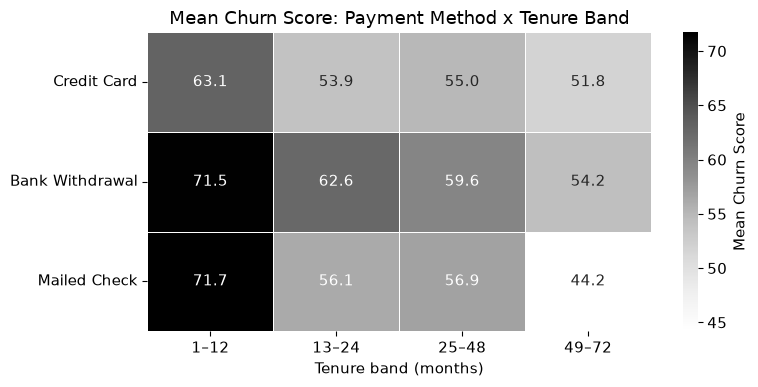

In [129]:
heat = obs.pivot_table(
    index="Payment Method",
    columns=bands,
    values="Churn Score",
    aggfunc="mean",
    observed=True,
).loc[pay_order]

# Number of customers per cell (to confirm that no cell has too few customers)
print("Clientes por célula:")
print(
    obs.pivot_table(
        index="Payment Method",
        columns=bands,
        values="Churn Score",
        aggfunc="count",
        observed=True,
    ).loc[pay_order]
)

plt.figure(figsize=(8, 4))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1f",
    cmap="Greys",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Mean Churn Score"},
)
plt.title("Mean Churn Score: Payment Method x Tenure Band")
plt.xlabel("Tenure band (months)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Conclusion: Payment Method vs Churn Score and Customer Status

This analysis includes only customers already in the company (Stayed and Churned, 6,589 customers). The 454 Joined customers were excluded because they have no churn outcome yet.

**Churn Score:** Credit Card customers have the lowest mean score (55.4), while Bank Withdrawal (61.5) and Mailed Check (62.0) are higher.

**Customer Status:** the real outcome follows the same order, with a larger gap. 15.8% of Credit Card customers churned, against 35.6% with Bank Withdrawal and 41.4% with Mailed Check, which is well above the overall churn rate (around 28%). The model score and the observed churn point in the same direction.

**Tenure (heatmap):** risk falls with tenure for every payment method, and tenure explains part of the Mailed Check result. These customers are much newer (mean tenure of 21.3 months vs 37.1 for Credit Card and 34.0 for Bank Withdrawal), and 48% of them are in their first year (vs 21% for Credit Card).
- **Credit Card vs Bank Withdrawal:** the gap persists in every tenure band, but it shrinks with tenure (−8.4, −8.7, −4.6 and −2.4 points from the shortest to the longest band). Credit Card therefore carries information beyond tenure.
- **Mailed Check:** it has the highest score only in the first year (71.7, similar to Bank Withdrawal at 71.5). In the other bands it is closer to Credit Card than to Bank Withdrawal, and it has the lowest score after 49 months (44.2). This group is small (343 customers, only 53–62 per cell after the first year), so these values should be read with caution.

**For modelling:** Payment Method is a useful candidate feature, mainly through Credit Card (lower risk) versus the remaining methods. This is consistent with the logistic regression coefficients (Mailed Check increases risk, Credit Card reduces it). This is an association: the payment method may reflect the customer profile (for example automatic, card-based payments) and not cause the lower churn.

#### 1.5.6 Financial Groups vs Churn Score

We compare the financial profile of the three risk groups (Low 0–39, Medium 40–69, High 70–100), using eligible customers only (Stayed + Churned, 6,589; the 454 Joined customers have no churn outcome yet), to identify which financial groups concentrate a high Churn Score. We use Monthly Charge (current spend) and Total Charges (accumulated spend). Total Revenue is left out because it is almost the same measure as Total Charges (Spearman rho = 0.974) and is not used in the model.

In [130]:
# --- Financial variables by risk group (all customers) ---
fin_vars = ["Monthly Charge", "Total Charges"]
band_order = ["Low (0-39)", "Medium (40-69)", "High (70-100)"]
TELCO["Risk Band"] = pd.cut(
    TELCO["Churn Score"], [0, 39, 69, 100], labels=band_order, include_lowest=True
)

print(TELCO["Risk Band"].value_counts().reindex(band_order), "\n")  # should match the risk band chart

summary = (TELCO.groupby("Risk Band", observed=True)[fin_vars].agg(["mean", "median"]).round(0))
print(summary)

Risk Band
Low (0-39)        1679
Medium (40-69)    2799
High (70-100)     2565
Name: count, dtype: int64 

               Monthly Charge        Total Charges        
                         mean median          mean  median
Risk Band                                                 
Low (0-39)               61.0   62.0        2533.0  1652.0
Medium (40-69)           63.0   68.0        2476.0  1640.0
High (70-100)            69.0   76.0        1902.0  1058.0


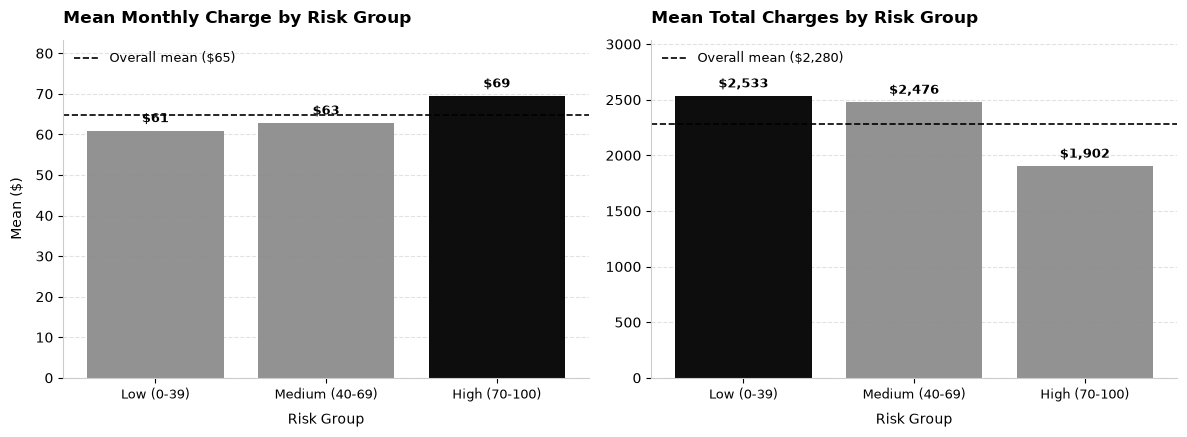

In [131]:
# --- Graph: mean of each financial variable by risk group ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, v in zip(axes, fin_vars):
    vals = TELCO.groupby("Risk Band", observed=True)[v].mean().reindex(band_order)
    overall = TELCO[v].mean()

    # Largest bar in green, the rest in gray (no heavy outlines)
    colors = [BLACK if m == vals.max() else DARK_GRAY for m in vals]
    bars = ax.bar(band_order, vals, color=colors, linewidth=0, alpha=0.95)

    # Overall mean
    ax.axhline(overall, color=BLACK, ls="--", lw=1.2, label=f"Overall mean (${overall:,.0f})")

    for b, m in zip(bars, vals):
        ax.text(
            b.get_x() + b.get_width() / 2,
            m + (vals.max() * 0.02),  # Consistent position above the bar
            f"${m:,.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
            color=BLACK,
            fontweight="bold",
        )

    # IBCS formatting (left-aligned title, clean typography)
    ax.set_title(f"Mean {v} by Risk Group", fontsize=12, fontweight="bold", pad=12, loc="left")
    ax.set_xlabel("Risk Group", fontsize=10, labelpad=8)
    ax.set_ylim(0, max(vals.max(), overall) * 1.2)   # headroom at the top for the legend
    ax.legend(frameon=False, fontsize=9, loc="upper left")

    # Remove top and right borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")

    # Very subtle horizontal grid on the Y axis only
    ax.grid(axis="y", linestyle="--", alpha=0.25, color=DARK_GRAY)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.tick_params(axis="y", labelsize=10)

axes[0].set_ylabel("Mean ($)", fontsize=10, labelpad=8)

plt.tight_layout()
plt.show()

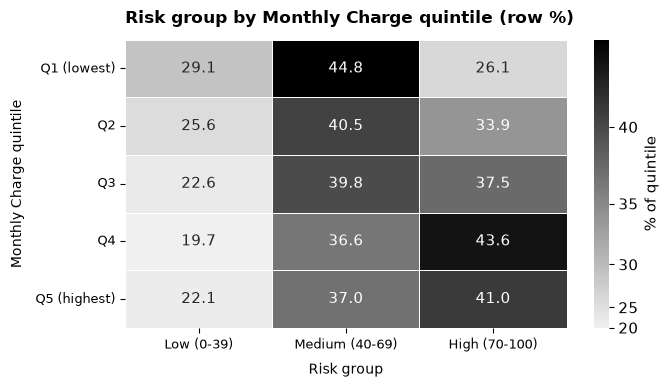

High-risk customers: 2565 (36.4% of all)
High-value AND high-risk: 577 customers = 22.5% of the high-risk group
Monthly revenue of the high-risk group: $178,148 (of which 33.1% from high-value customers)


In [132]:
# --- High-value customers: risk profile by Monthly Charge quintile ---
q_labels = ["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
TELCO["Charge Quintile"] = pd.qcut(
    TELCO["Monthly Charge"].rank(method="first"), 5, labels=q_labels
)

heat = (
    pd.crosstab(TELCO["Charge Quintile"], TELCO["Risk Band"], normalize="index") * 100
)[band_order].round(1)

# Continuous gradient: light gray -> green, with the green "arriving" later
gray_green = LinearSegmentedColormap.from_list("gray_green", ["#f0f0f0", BLACK])
norm = PowerNorm(gamma=1.7, vmin=heat.values.min(), vmax=heat.values.max())

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1f",
    cmap=gray_green,
    norm=norm,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "% of quintile"},
    ax=ax,
)
ax.set_title(
    "Risk group by Monthly Charge quintile (row %)",
    fontsize=12, fontweight="bold", pad=12, loc="left",
)
ax.set_xlabel("Risk group", fontsize=10, labelpad=8)
ax.set_ylabel("Monthly Charge quintile", fontsize=10, labelpad=8)
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)   # quintile names horizontal
plt.tight_layout()
plt.show()

# High value (top 20% Monthly Charge) AND high risk (score 70-100)
hv = TELCO["Charge Quintile"] == "Q5 (highest)"
hr = TELCO["Risk Band"] == "High (70-100)"
print(f"High-risk customers: {hr.sum()} ({hr.mean() * 100:.1f}% of all)")
print(
    f"High-value AND high-risk: {(hv & hr).sum()} customers "
    f"= {(hv & hr).sum() / hr.sum() * 100:.1f}% of the high-risk group"
)
print(
    f"Monthly revenue of the high-risk group: ${TELCO.loc[hr, 'Monthly Charge'].sum():,.0f} "
    f"(of which {TELCO.loc[hv & hr, 'Monthly Charge'].sum() / TELCO.loc[hr, 'Monthly Charge'].sum() * 100:.1f}% "
    f"from high-value customers)"
)

### Conclusion: Financial groups vs Churn Score

All customers are included (7,043).

**Monthly Charge:** customers who pay more per month are more likely to be high-risk. The share of high-risk customers goes from 26.1% in the lowest quintile to 41.0–43.6% in the two highest (overall: 36.4%), and the relation holds when we compare customers with the same tenure.

**Total Charges:** it looks lower for high-risk customers ($1,902 vs $2,533), but only because they are newer and have had less time to accumulate charges. At the same tenure the relation disappears, so Total Charges mostly measures tenure and adds little. Total Revenue behaves the same way and is left out.

**High-value and high-risk:** 577 customers in the top quintile of Monthly Charge are also high-risk. They are 22.5% of the high-risk group but carry 33.1% of its monthly revenue, so this is the segment to protect first.

**For modelling:** Monthly Charge has a clear and independent signal, while Total Charges mostly overlaps with tenure. These are associations, not causes.

### 1.6 Which Characteristics Are Associated with Churn? (Problem 1)

Overall churn rate: 0.284


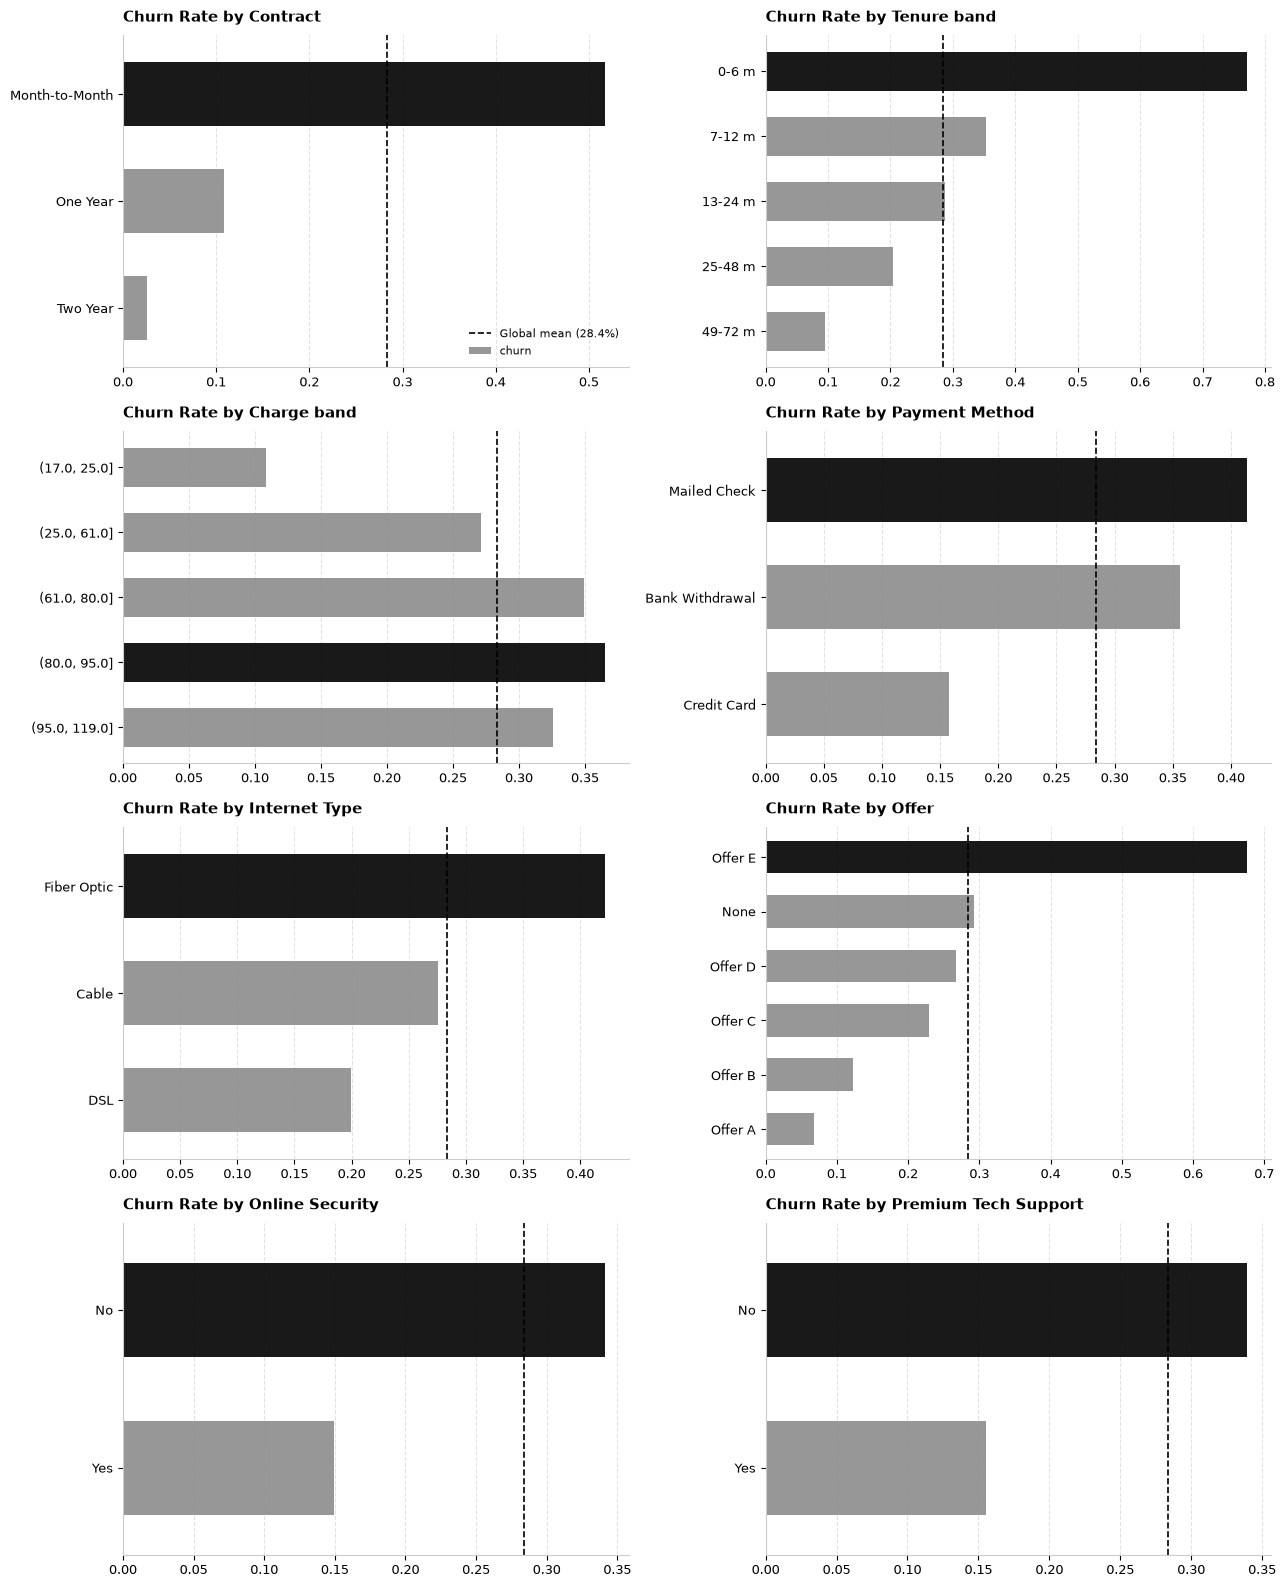

In [133]:
eda = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
eda["churn"] = (eda["Customer Status"] == "Churned").astype(int)
print("Overall churn rate:", eda["churn"].mean().round(3))

# Clean labels for Tenure band (eliminates -0.001)
tenure_bins = [0, 6, 12, 24, 48, 72]
tenure_labels = ["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"]
eda["Tenure band"] = pd.cut(
    eda["Tenure in Months"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True,
)

# Rounded, sorted labels for Charge band (eliminates messy decimals)
eda["Charge band"], q_bins = pd.qcut(
    eda["Monthly Charge"], q=5, retbins=True, precision=0
)
eda["Charge band"] = eda["Charge band"].astype(str)

cols = [
    "Contract",
    "Tenure band",
    "Charge band",
    "Payment Method",
    "Internet Type",
    "Offer",
    "Online Security",
    "Premium Tech Support",
]

fig, axes = plt.subplots(4, 2, figsize=(13, 16))
global_mean = eda["churn"].mean()

for ax, col in zip(axes.ravel(), cols):
    rate = eda.groupby(col, observed=True)["churn"].mean()

    # Keep natural ordinal order for numeric bands; sort categories by rate
    if col in ["Tenure band", "Charge band"]:
        rate = rate.iloc[::-1]  # Bottom-to-top natural order
    else:
        rate = rate.sort_values(ascending=True)

    colors = [BLACK if v == rate.max() else DARK_GRAY for v in rate]
    rate.plot(
        kind="barh",
        ax=ax,
        color=colors,
        edgecolor="none",
        width=0.6,
        alpha=0.9,
    )

    # Subtle and elegant reference line for the global mean
    ax.axvline(global_mean, color=BLACK, linestyle="--", linewidth=1.2, label=f"Global mean ({global_mean:.1%})")

    # IBCS formatting (left-aligned title, clean typography)
    ax.set_title(f"Churn Rate by {col}", fontsize=11, fontweight="bold", pad=10, loc="left")
    ax.set_xlabel("")
    ax.set_ylabel("")  # The variable name is already in the title

    # Remove top and right spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")

    # Very subtle vertical grid
    ax.grid(axis="x", linestyle="--", alpha=0.25, color=DARK_GRAY)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=9)
    ax.tick_params(axis="x", labelsize=9)

# Legend only on the first panel for reference
axes.ravel()[0].legend(frameon=False, fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

#### Results — what the exploratory analysis shows

The overall churn rate is **28.4%** (dashed black line in each chart).
 This value was obtained earlier as the sum of Churned divided by Churned + Stayed (excluding Joined).

##### The groups above that line are the highest-risk ones:

| Factor | Highest-risk groups | Lowest-risk groups |
|---|---|---|
| Contract | Month-to-Month: **51.7%** | One Year: **10.9%** · Two Year: **2.6%** |
| Tenure | 0–6 months: **77.2%** (7–12 m: 35.3%) | 49–72 months: **9.5%** |
| Monthly charge | Band 3 to 5: **32.5–36.5%** | Lowest band: **10.9%** |
| Payment method | Mailed Check: **41.4%** · Bank Withdrawal: 35.6% | Credit Card: **15.8%** |
| Internet type | Fiber Optic: **42.1%** | No internet: **8.4%** · DSL: **20.0%** |
| Offer | Offer E: **67.6%** | Offer A: **6.7%** · Offer B: **12.3%** |
| Online Security / Premium Tech Support | Without the service: **34.1%** / **34.0%** | With the service: **15.0%** / **15.5%** |

**Context:** churn is concentrated in **recent customers, on monthly contracts, without security/support services and with fiber**. The relationship with monthly charge is not linear: the risk rises from the lowest quintile (10.9%) to the others, but then levels off instead of continuing to rise.

**Offer E:** Based on the previous analysis, we conclude that there is a higher risk if we give Offer E, even compared with giving no offer at all. The solution will be to redefine the conditions of Offer E (for the newest members).

## 2. Feature Selection & Engineering

Choosing which variables enter the model and engineering new ones, before any model is trained.

### 2.1 Feature Selection

In [134]:
# Keep only the customers relevant to the project
model_df = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()

# Create the binary target
y = (model_df["Customer Status"] == "Churned").astype(int)

# Remove variables that reveal the target or are unsuitable
dup_cols = [c for c in TELCO.columns if c.startswith(("Count", "Quarter"))]

exclude_cols = [
    "Customer ID",
    "Customer Status",
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "CLTV",
    "Churn Category",
    "Churn Reason",
    "Country",
    "State",
    "Lat Long",
    "City",
    "Zip Code",
    "Under 30",
    "Senior Citizen",
    "Dependents",
    "Referred a Friend",
    "Internet Service",
    "Total Revenue",
    "Satisfaction Score",
] + dup_cols

X = model_df.drop(columns=exclude_cols, errors="ignore")

print("Shape of X:", X.shape)
print("Target distribution:")
print(y.value_counts())
print("\nChurn proportion:")
print(y.mean().round(3))

Shape of X: (6589, 35)
Target distribution:
Customer Status
0    4720
1    1869
Name: count, dtype: int64

Churn proportion:
0.284


#### **Why did we exclude these variables?**
- **Customer ID:** Redundant variable, since it adds no information to the model.
- **Customer Status:** It is used to build the target, not to predict the status itself.
- **Churn Label and Churn Value:** They directly contain the answer we want to predict.
- **Churn Score and CLTV:** They already come from another predictive model; we do not want the first model to depend on an existing score, even more so as it is based on a predictive model with formulas we do not know.
- **Churn Category and Churn Reason:** They describe the churn after it has occurred.
- **Country, State, Lat Long, City and Zip Code:** Because it is a variable that captures many factors for which we have no information.
- **Under 30 and Senior Citizen:** These were excluded because of multicollinearity, since the variable "Age" will be used.
- **Dependents:** Because it is a redundant variable: a poorer copy of Number of Dependents, which stayed in the model.
- **Referred a Friend:** This was excluded because of multicollinearity, since "Number of Referrals" will be used.
- **Internet Service:** This was excluded because of multicollinearity, since "Internet Type" will be used. It is "No" exactly when "Internet Type" is "None" (100% of customers), so "Internet Type" already carries the same information in more detail.
- **Total Revenue:** Excluded as redundant: it is the sum of Total Charges, Total Extra Data Charges and Total Long Distance Charges, minus Total Refunds
- **Satisfaction Score:** It is excluded initially because it belongs to the status table and because we are not certain how often it was collected per customer.
- Some variables are derived from others or redundant. Later, we can test whether including them improves the solution.

#### Result obtained — set of variables

- `X` has **6,589 customers × 33 variables** and the target has **4,720 Stayed (0) and 1,869 Churned (1)**, i.e. 28.4% churn: a moderate imbalance, which is why we use PR-AUC and stratification in the *splits*.
- The remaining variables are known **before** the customer leaves (demographics, services, contract, billing and charges), unlike the ones excluded above, which describe or result from churn.
- `Tenure in Months`, `Monthly Charge` and `Total Charges` are strongly related to each other (the correlation between `Total Charges` and tenure is 0.81), which limits how individual coefficients can be read later on.

### 2.2 Feature Engineering

**Is it worth creating new variables?** The research question asks for a list of customers ranked by risk, so any gain in the model's ranking ability translates directly into more churners caught with the same contact capacity. The exploratory analysis suggests three hypotheses:

1. **Tenure does not have a linear effect.** Churn drops sharply in the first months (77.2% in the first 6 months, 9.5% after 48) and then flattens. A logistic regression only learns a linear trend in `Tenure in Months`.
2. **There are interactions.** Customers on a monthly contract *and* with less than a year with the company have 68.0% churn (1,505 customers), against 16.6% for the rest.
3. **Services count together.** Customers with internet but without Online Security or Premium Tech Support have 52.9% churn, against 14.6% for the rest.

Instead of guessing, we define candidates and **test** which ones help the model:

| Variable | Definition | Motivation |
|---|---|---|
| `n_protection` | number of protection services (Online Security, Online Backup, Device Protection, Premium Tech Support) | customers with more services are more "locked in" to the operator |
| `n_streaming` | number of streaming services (TV, Movies, Music) | same |
| `n_addons` | `n_protection` + `n_streaming` | summary of engagement with the offering |
| `charge_per_service` | `Monthly Charge` / (1 + `n_addons`) | how much they pay for each service |
| `no_protection` | has internet but has neither Online Security nor Premium Tech Support | risk group identified in the EDA |
| `log_tenure` | log(1 + `Tenure in Months`) | concave effect of tenure |
| `is_new_customer` | `Tenure in Months` ≤ 12 | the first year is the critical period |
| `m2m_new` | Month-to-Month **and** `Tenure in Months` ≤ 12 | contract × tenure interaction |
| `charge_gap` | `Total Charges` − `Tenure` × `Monthly Charge` | detects price changes over time |
| `has_referrals` | `Number of Referrals` > 0 | customers who brought in other customers |

All of them use only information from the **customer itself** (nothing from the target nor statistics of other customers), so they do not introduce *data leakage*.

#### New Variables

In [135]:
def add_features(X):
    # Creates derived variables from the columns that already exist.
    # Each new variable uses only information from the customer itself (no target
    # statistics nor other customers' statistics), so it does not introduce data leakage.
    X = X.copy()
    n_yes = lambda cols: (X[cols] == "Yes").sum(axis=1)

    # Subscribed services
    X["n_protection"] = n_yes(
        [
            "Online Security",
            "Online Backup",
            "Device Protection Plan",
            "Premium Tech Support",
        ]
    )
    X["n_streaming"] = n_yes(["Streaming TV", "Streaming Movies", "Streaming Music"])
    X["n_addons"] = X["n_protection"] + X["n_streaming"]
    X["charge_per_service"] = X["Monthly Charge"] / (1 + X["n_addons"])
    X["no_protection"] = (
        (X["Internet Type"] != "None")
        & (X["Online Security"] == "No")
        & (X["Premium Tech Support"] == "No")
    ).astype(int)

    # Tenure and contract
    is_new = X["Tenure in Months"] <= 12
    X["log_tenure"] = np.log1p(X["Tenure in Months"])
    X["is_new_customer"] = is_new.astype(int)
    X["m2m_new"] = ((X["Contract"] == "Month-to-Month") & is_new).astype(int)

    # Others
    X["charge_gap"] = X["Total Charges"] - X["Tenure in Months"] * X["Monthly Charge"]
    X["has_referrals"] = (X["Number of Referrals"] > 0).astype(int)
    return X


X_all_fe = add_features(X)
candidate_features = [c for c in X_all_fe.columns if c not in X.columns]
print(len(candidate_features), "candidate variables:", candidate_features)

10 candidate variables: ['n_protection', 'n_streaming', 'n_addons', 'charge_per_service', 'no_protection', 'log_tenure', 'is_new_customer', 'm2m_new', 'charge_gap', 'has_referrals']


<a id="sec-2-3"></a>
### 2.3 Do the New Variables Improve the Model?

We compare the same model with and without each group of new variables, using **5-fold cross-validation only on the development part (80%)**. The test set is left out, exactly as in "3.1 Train / Test Split", so that it is not used to choose variables. We test two types of model:

- **LR** (logistic regression): a linear model, the one that can benefit most from variables that "teach" non-linearities and interactions;
- **GB** (gradient boosting): trees, which already learn non-linearities on their own.

The main metric is PR-AUC, in line with the prioritization objective.

#### Pre-Processing

In [136]:
# We only use the development part (80%). The test set is left out,
# exactly as in the "Train and Test" section.
X_dev0, _, y_dev0, _ = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


def make_preprocessor(Xa):
    num = Xa.select_dtypes(include="number").columns.tolist()
    cat = Xa.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                num,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                cat,
            ),
        ]
    )


feature_groups = {
    "Original (no new variables)": [],
    "+ service counts": ["n_protection", "n_streaming", "n_addons"],
    "+ charge per service": ["charge_per_service"],
    "+ no protection": ["no_protection"],
    "+ tenure / contract": ["log_tenure", "is_new_customer", "m2m_new"],
    "+ only log(tenure)": ["log_tenure"],
    "+ charge gap": ["charge_gap"],
    "+ has referrals": ["has_referrals"],
    "+ selected (see below)": [
        "log_tenure",
        "is_new_customer",
        "m2m_new",
        "has_referrals",
    ],
}
fe_models = {
    "LR": LogisticRegression(max_iter=3000),
    "GB": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, cols in feature_groups.items():
    Xa = X_all_fe.loc[X_dev0.index, list(X.columns) + cols]
    row = {"Variables used": name}
    for short_name, est in fe_models.items():
        r = cross_validate(
            Pipeline([("prep", make_preprocessor(Xa)), ("model", est)]),
            Xa,
            y_dev0,
            cv=cv,
            n_jobs=-1,
            scoring={"pr": "average_precision", "roc": "roc_auc"},
        )
        row[f"{short_name} PR-AUC"] = r["test_pr"].mean()
        row[f"{short_name} ROC-AUC"] = r["test_roc"].mean()
    rows.append(row)

fe_results = pd.DataFrame(rows).set_index("Variables used")
fe_results.round(4)

,LR PR-AUC,LR ROC-AUC,GB PR-AUC,GB ROC-AUC
Variables used,,,,
Original (no new variables),0.9598,0.9830,0.9655,0.9845
+ service counts,0.9599,0.9830,0.9661,0.9847
+ charge per service,0.9598,0.9829,0.9668,0.9849
+ no protection,0.9597,0.9829,0.9658,0.9844
+ tenure / contract,0.9674,0.9855,0.9657,0.9846
+ only log(tenure),0.9669,0.9854,0.9655,0.9845
+ charge gap,0.9597,0.9829,0.9659,0.9846
+ has referrals,0.9601,0.9830,0.9655,0.9845
+ selected (see below),0.9677,0.9856,0.9657,0.9846


| Variable group | Effect on LR (PR-AUC) | Effect on GB (PR-AUC) |
|---|---|---|
| Original | 0.9591 | 0.9665 |
| + tenure / contract | **0.9671 (+0.0080)** | 0.9666 (no change) |
| + only `log_tenure` | **0.9665 (+0.0074)** | 0.9665 (no change) |
| + has referrals | 0.9593 (+0.0002) | 0.9665 (no change) |
| + service counts, charge per service, no protection, charge gap | 0.9589-0.9591 (no gain) | 0.9661-0.9673 (within ±0.001) |
| + selected | **0.9673 (+0.0082)** | 0.9666 (no change) |

Conclusions:

- **For the logistic regression the gain is small in absolute terms (+0.008 PR-AUC) because it already starts at 0.959, but it is the only group of variables that helps**, and it comes almost entirely from **`log_tenure`** (0.9665 on its own): it confirms hypothesis 1 (concave effect of tenure). ROC-AUC rises from 0.9825 to 0.9852-0.9853.
- **For gradient boosting there is no gain**: the trees already learn these relationships from the original variables (0.9665 vs 0.9666).
- **The service variables (counts, charge per service, `no_protection`) do not help**, even though the EDA shows a strong association with churn: that information is already contained in the original Yes/No columns and in the other predictors (contract, tenure). An association in the EDA does not imply a prediction gain.
- `charge_gap` also adds nothing (and is derived from columns that already enter the model).
- These PR-AUC values are much higher than a clean model would give because `X` still contains the `Churn Score Range` column (see 2.1.4); the comparison between groups is still valid, but the absolute levels are inflated.

### 2.4 Final Feature Set

In [137]:
selected_features = ["log_tenure", "is_new_customer", "m2m_new", "has_referrals"]

# X_fe = original X + the selected variables (same rows and same index as X)
X_fe = X_all_fe[list(X.columns) + selected_features]
print("Original X:", X.shape, "-> X with feature engineering:", X_fe.shape)

Original X: (6589, 35) -> X with feature engineering: (6589, 39)


#### Decision

**We keep the four variables** that help or that have clear business logic:
- **`log_tenure`**
- **`is_new_customer`**
- **`m2m_new`**
- **`has_referrals`**

We discard the rest (more columns without gain only add noise).
The variable `X_fe`, which holds the dataset, ends up with 37 columns (33 original + 4 new).

## 3. Baseline Model: Logistic Regression

Train/test split, a majority-class baseline and a first logistic regression, used as the reference for the model comparison in Chap. 4.

### 3.1 Train / Test Split

In [138]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nChurn rate in train:", round(y_train.mean(), 3))
print("Churn rate in test:", round(y_test.mean(), 3))

Train: (5271, 35)
Test: (1318, 35)

Churn rate in train: 0.284
Churn rate in test: 0.284


#### Result obtained — train/test split

**5,271 customers in train and 1,318 in test**, with the same churn rate (28.4%) in both: the stratification worked and the test set is representative. Chap.3 reuses exactly this test set (same *seed* and same stratification), so the results are comparable.

### 3.2 Preprocessing (Numerical and Categorical)

In [139]:
# Identify the variable types
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preparation of the numerical variables (StandardScaler)
numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

# Preparation of the categorical variables (OneHotEncoder)
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# Combine the two processes
preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

C:\Users\andre\AppData\Local\Temp\ipykernel_19820\2847727980.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [140]:
# Baseline: always predict the most frequent class
baseline = Pipeline(
    [("preprocessor", preprocessor), ("model", DummyClassifier(strategy="prior"))]
)

# First real model
logistic_model = Pipeline(
    [("preprocessor", preprocessor), ("model", LogisticRegression(max_iter=2000))]
)

baseline.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

print("Models trained successfully!")

Models trained successfully!


### 3.3 Model evaluation

In [141]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("\nClassification report:")
    print(
        classification_report(
            y_test, predictions, target_names=["Stayed", "Churned"], zero_division=0
        )
    )

    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

    print(
        "PR-AUC (Average Precision):",
        round(average_precision_score(y_test, probabilities), 4),
    )

    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))


evaluate_model("Baseline", baseline, X_test, y_test)
evaluate_model("Logistic Regression", logistic_model, X_test, y_test)


Baseline

Classification report:
              precision    recall  f1-score   support

      Stayed       0.72      1.00      0.83       944
     Churned       0.00      0.00      0.00       374

    accuracy                           0.72      1318
   macro avg       0.36      0.50      0.42      1318
weighted avg       0.51      0.72      0.60      1318

Confusion matrix:
[[944   0]
 [374   0]]
PR-AUC (Average Precision): 0.2838
ROC-AUC: 0.5

Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Stayed       0.95      0.96      0.95       944
     Churned       0.89      0.86      0.87       374

    accuracy                           0.93      1318
   macro avg       0.92      0.91      0.91      1318
weighted avg       0.93      0.93      0.93      1318

Confusion matrix:
[[903  41]
 [ 52 322]]
PR-AUC (Average Precision): 0.9646
ROC-AUC: 0.9843


Metrics:
 - **Precision** - Of the customers flagged, how many actually churned in the test set?
- **Recall** - Of all the customers who churned in the test set, how many were identified?
- **F1-score** - Balance between precision and recall for a given threshold.
- **PR-AUC / Average Precision** - Ability to rank and identify the churn class, especially useful when the classes are imbalanced.
- **ROC-AUC** - Ability to distinguish customers who churned from those who stayed, considering different thresholds.

#### Result obtained — baseline vs logistic regression

| | Baseline | Logistic regression |
|---|---|---|
| Accuracy | 0.72 | **0.93** |
| Precision (Churned) | 0.00 | **0.88** |
| Recall (Churned) | 0.00 | **0.86** |
| F1 (Churned) | 0.00 | **0.87** |
| PR-AUC | 0.284 | **0.965** |
| ROC-AUC | 0.500 | **0.985** |

- The **baseline** always predicts "Stayed": it is right in 72% of cases (the proportion of Stayed) but **does not identify a single churner**. That is why accuracy alone is misleading with imbalanced classes, and why the baseline's PR-AUC (0.284) equals the churn rate.
- In the **logistic regression**, the confusion matrix shows 323 churners identified out of 374 (recall 0.86), 51 churners who slip through and 43 false alarms. In practical terms: out of every 100 customers flagged, about 88 will actually leave. These values are unusually high; section 2.1.4 explains why.

### 3.4 Turning the Probabilities into a Priority List
Instead of using only the Churned/Stayed prediction, we will rank the customers by their estimated probability of churn.

In [142]:
# Estimated churn probability for each test customer
churn_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Create a results table
priorities = pd.DataFrame(
    {
        "Customer ID": model_df.loc[X_test.index, "Customer ID"],
        "Actual Churn": y_test,
        "Churn Probability": churn_probabilities,
    },
    index=X_test.index,
)

# Sort from the highest to the lowest risk
priorities = priorities.sort_values("Churn Probability", ascending=False)

# Select the 10% of customers with the highest risk
top_n = max(1, int(np.ceil(0.10 * len(priorities))))
top_customers = priorities.head(top_n)

# Assess how many churners were found
total_churners = priorities["Actual Churn"].sum()
churners_captured = top_customers["Actual Churn"].sum()

print("Customers selected:", len(top_customers))
print("Churners identified:", churners_captured)

if total_churners > 0:
    print("Recall in top 10%:", round(churners_captured / total_churners, 3))

display(top_customers.head(20))

Customers selected: 132
Churners identified: 132
Recall in top 10%: 0.353


,Customer ID,Actual Churn,Churn Probability
387,1363-TXLSL,1,0.999885
443,3319-DWOEP,1,0.999880
1427,0680-DFNNY,1,0.999770
2039,0318-QUUOB,1,0.999651
1596,1583-IHQZE,1,0.999630
108,5047-LHVLY,1,0.999613
327,4816-JBHOV,1,0.999604
2192,4919-IKATY,1,0.999598
2312,7240-ETPTR,1,0.999588
1879,8601-QACRS,1,0.999579


#### Results — priority list (top 10%)

Contacting only the **132 customers** with the highest probability (10% of the test set), **132 were indeed churners** (precision 100%). The recall of 35.3% looks low, but the maximum possible with 132 contacts would be 132/374 = 35.3%: the limit here is the **operational capacity**, not the model. In the table, the first 20 customers have probabilities between 0.9986 and 0.9998 and all of them left. A result this perfect is another warning sign of leakage (3.5).

##### ROC-AUC: 0.9189 is too high a value, what explains it? (3.5)

### 3.5 Data Leakage

ROC-AUC of 0.9189 is too high a value. What explains it? The logistic regression coefficients below answer this.

In [143]:
names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(
    logistic_model.named_steps["model"].coef_[0], index=names
).sort_values()
print(coefs.head(10))
print(coefs.tail(10))

cat__Risk Band_Low (0-39)       -2.390043
cat__Churn Score Range_50-60    -1.950765
cat__Churn Score Range_40-50    -1.892102
num__Number of Referrals        -1.369133
cat__Churn Score Range_70-80    -1.357015
cat__Contract_Two Year          -1.307570
cat__Risk Band_Medium (40-69)   -1.279593
cat__Churn Score Range_30-40    -1.230223
cat__Churn Score Range_20-30    -1.140959
num__Tenure in Months           -1.111070
dtype: float64
cat__Offer_Offer E                  0.419816
cat__Payment Method_Mailed Check    0.436581
cat__Married_Yes                    0.563711
cat__Offer_Offer A                  0.682579
num__Monthly Charge                 0.863903
cat__Churn Score Range_80-90        1.003554
cat__Contract_Month-to-Month        1.058599
cat__Churn Score Range_60-70        2.563274
cat__Risk Band_High (70-100)        3.299373
cat__Churn Score Range_90-100       3.652834
dtype: float64


#### Result obtained — logistic regression coefficients

The numerical variables are standardized, so the coefficients are comparable with each other.

- **Increase risk (largest):** `Churn Score Range` 90-100 (+5.88), 80-90 (+3.82), 70-80 (+1.52) and 60-70 (+0.91); then `Month-to-Month` contract (+1.05), `Monthly Charge` (+0.62), `Offer A` (+0.59), `Married = Yes` (+0.56), `Total Charges` (+0.47) and payment by `Mailed Check` (+0.44).
- **Reduce risk (largest):** `Churn Score Range` 50-60 (−3.18), 30-40 (−3.13), 40-50 (−3.10) and 20-30 (−2.97); then `Number of Referrals` (−1.35), `Two Year` contract (−1.27), `Tenure in Months` (−1.25), `Married = No` (−0.91), `Offer D` (−0.72) and payment by credit card (−0.69).

**Leakage warning:** the seven largest coefficients in absolute value all belong to the `Churn Score Range` bands, a column derived from the SPSS Churn Score that was meant to be excluded but is still in `X`. It dominates the model and explains the very high ROC-AUC (see 2.1.4).

**Reading with care:** some signs contradict the EDA. `Fiber Optic` has the highest churn in the isolated analysis (42.1%) but a negative coefficient (−0.35), and `Married = Yes` (20.2% churn vs 36.7% for No) and `Offer A` (6.7% churn) have lower churn in the EDA but a positive coefficient. This happens because, in a model with correlated variables (`Monthly Charge`, `Total Charges`, `Tenure`, services), the effect is shared among them. The coefficients show the relative weight inside the model; to tell the story of an isolated factor, use the EDA.

### 3.6 Conclusion — Logistic Regression

**Performance.** The model separates customers who leave from customers who stay very well, hence the high value
(ROC-AUC = 0.985; PR-AUC = 0.965), against a baseline with no discriminative
ability (ROC-AUC = 0.500; PR-AUC = 0.284, equal to the churn rate of 28.4%).
With a threshold of 0.5, the Churned class has precision = 0.88, recall = 0.86 and
F1 = 0.87 (323 of 374 churners identified, 43 false positives).
The baseline's accuracy (0.72) shows why it is not an adequate metric
with imbalanced classes.

**Usefulness for the retention decision.** Contacting only the 10% of customers with the
highest risk (132 customers), all 132 were indeed churners (precision 100%),
about 3.5 times more than in a random selection (≈ 28%). The recall of 35.3%
is the maximum possible with 132 contacts (132/374), so the relevant indicator in this scenario is precision@k.

**Risk drivers.** Shorter tenure, Month-to-Month contract and high monthly charge
increase the risk; longer tenure, more referrals and a two-year
contract reduce it. These results are consistent with the exploratory analysis (1.2) and
with business logic.

**Validation and leakage.** The main predictors are known before the customer
leaves, and the post-churn variables, the Churn Score and the Satisfaction Score were left out of the model. However, the
`Churn Score Range` column, created from the Churn Score in the EDA, was not dropped and carries the largest coefficients (up to +5.88 and −3.18).
This is information leakage and explains why ROC-AUC and PR-AUC are so high; the values above should be read with this in mind
until that column (and the other helper columns created in the EDA) is removed from `X`.

**Limitations.**
- Tenure, Monthly Charge and Total Charges are collinear, so the
  individual coefficients should not be interpreted in isolation.
- Offer may reflect who the offer was given to, and not its effect.
- The evaluation uses a single train/test split, and has not yet been compared
  with the existing Churn Score or with other models.
- The results describe association, not the causal effect of any intervention.

## 4. Model Comparison (Train / Validation / Test)

The logistic regression in Chap. 3 used a single train/test split. From here on we follow the methodology used in the Week 6–7 lectures (model selection and evaluation): separate **train, validation and test**, compare several models at once in an experiments table, choose the winner **based only on validation**, and evaluate that winner on the test set **only once**, at the end.

Here we also test the effect of feature engineering (some models appear with and without the four new variables) and that of the **calibration of the probabilities** of the gradient boosting.

### 4.1 Train, Validation and Test Split

In [144]:
# First split: the same as in "Train and Test"
test_idx_2_1 = set(X_test.index)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
assert set(X_test.index) == test_idx_2_1, "the test set changed compared with 2.1"

# Second split: divide the rest into train and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)
# 0.25 de 80% = 20% do total
# train 60% / validation 20% / test 20%

# Versions with feature engineering (same rows, only with the new columns)
X_train_fe, X_val_fe, X_test_fe = (X_fe.loc[a.index] for a in (X_train, X_val, X_test))

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("With FE:", X_train_fe.shape)

Train: (3953, 35) | Validation: (1318, 35) | Test: (1318, 35)
With FE: (3953, 39)


#### Result obtained — the three sets

**3,953 customers in train (60%), 1,318 in validation (20%) and 1,318 in test (20%).** The test set is exactly the same as in 2.1, so the final results can be compared with the initial logistic regression. The versions with feature engineering have the same rows, but 37 columns instead of 33.

### 4.2 — Preprocessor and Experiments Table

We repeat the preprocessing from 2.1.1 (imputation + standardization for the numerical variables, imputation + one-hot for the categorical ones) and train **nine candidates**, recording the nine metrics on train and validation, as in the reference notebook from the lectures:

- **Baseline** (predicts the base rate);
- **Logistic Regression** with original variables and **with FE**;
- **Decision Tree** (depth 5) and **Random Forest**, both with FE;
- **Gradient Boosting** with original variables and **with FE**;
- **Calibrated Gradient Boosting**, with original variables and **with FE**.

The "with and without FE" pairs let us see the effect of feature engineering isolated from everything else, and the two calibrated models let us see the effect of calibration.

**Why calibrate?** Gradient boosting tends to return probabilities very close to 0 and 1, and in Chap.4 we will multiply the probability by the customer's value: if the probability is unreliable as a *value*, the expected value is distorted. We use `CalibratedClassifierCV` with the sigmoid method and 5 folds **inside the training set**: each of the 5 models is calibrated on the 20% of the training data it did not see, so the validation and test sets take no part in the calibration.

In [145]:
# make_preprocessor() was defined in the Feature Engineering section (same treatment as 2.1.1).

# (train, validation, test) for each variable set
feature_sets = {
    "original": (X_train, X_val, X_test),
    "fe": (X_train_fe, X_val_fe, X_test_fe),
}

today = date.today().isoformat()
columns = [
    "date",
    "model",
    "dataset",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "log_loss",
    "brier",
    "note",
]
results = pd.DataFrame(columns=columns)
fitted, fset_of = {}, {}


def metric_row(name, dataset, y_true, p, note=""):
    flagged = p >= 0.5
    return [
        today,
        name,
        dataset,
        metrics.accuracy_score(y_true, flagged),
        metrics.balanced_accuracy_score(y_true, flagged),
        metrics.precision_score(y_true, flagged, zero_division=0),
        metrics.recall_score(y_true, flagged),
        metrics.f1_score(y_true, flagged, zero_division=0),
        metrics.roc_auc_score(y_true, p),
        metrics.average_precision_score(y_true, p),
        metrics.log_loss(y_true, p),
        metrics.brier_score_loss(y_true, p),
        note,
    ]


def log_model(name, model, fs):
    fitted[name], fset_of[name] = model, fs
    Xtr, Xva, _ = feature_sets[fs]
    for dataset, X_, y_ in [("train", Xtr, y_train), ("validation", Xva, y_val)]:
        results.loc[len(results)] = metric_row(
            name, dataset, y_, model.predict_proba(X_)[:, 1]
        )


# Model types (variable set, estimator)
candidates = {
    "Baseline (base rate)": ("original", DummyClassifier(strategy="prior")),
    "Logistic Regression": ("original", LogisticRegression(max_iter=2000)),
    "Logistic Regression + FE": ("fe", LogisticRegression(max_iter=2000)),
    "Decision Tree (depth 5) + FE": (
        "fe",
        DecisionTreeClassifier(max_depth=5, random_state=42),
    ),
    "Random Forest + FE": (
        "fe",
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1,
        ),
    ),
    "Gradient Boosting": ("original", HistGradientBoostingClassifier(random_state=42)),
    "Gradient Boosting + FE": ("fe", HistGradientBoostingClassifier(random_state=42)),
    # Calibration (sigmoid) with cross-validation INSIDE the training set: the
    # validation and test sets take no part in the calibration.
    "Gradient Boosting calibrated": (
        "original",
        CalibratedClassifierCV(
            HistGradientBoostingClassifier(random_state=42), method="sigmoid", cv=5
        ),
    ),
    "Gradient Boosting calibrated + FE": (
        "fe",
        CalibratedClassifierCV(
            HistGradientBoostingClassifier(random_state=42), method="sigmoid", cv=5
        ),
    ),
}

for name, (fs, estimator) in candidates.items():
    Xtr = feature_sets[fs][0]
    model = Pipeline([("preprocessor", make_preprocessor(Xtr)), ("model", estimator)])
    model.fit(Xtr, y_train)
    log_model(name, model, fs)

results.round(3)

,date,model,dataset,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,note
0,2026-11-11,Baseline (base rate),train,0.716,0.500,0.000,0.000,0.000,0.500,0.284,0.596,0.203,
1,2026-11-11,Baseline (base rate),validation,0.716,0.500,0.000,0.000,0.000,0.500,0.284,0.596,0.203,
2,2026-11-11,Logistic Regression,train,0.942,0.930,0.893,0.903,0.898,0.986,0.966,0.138,0.042,
3,2026-11-11,Logistic Regression,validation,0.923,0.900,0.878,0.848,0.863,0.981,0.953,0.160,0.050,
4,2026-11-11,Logistic Regression + FE,train,0.947,0.935,0.908,0.905,0.907,0.988,0.974,0.125,0.038,
5,2026-11-11,Logistic Regression + FE,validation,0.938,0.915,0.915,0.861,0.887,0.984,0.964,0.146,0.045,
6,2026-11-11,Decision Tree (depth 5) + FE,train,0.939,0.925,0.891,0.893,0.892,0.981,0.939,0.151,0.045,
7,2026-11-11,Decision Tree (depth 5) + FE,validation,0.923,0.901,0.874,0.850,0.862,0.962,0.891,0.305,0.061,
8,2026-11-11,Random Forest + FE,train,0.967,0.969,0.912,0.976,0.943,0.996,0.991,0.121,0.030,
9,2026-11-11,Random Forest + FE,validation,0.932,0.919,0.876,0.888,0.882,0.981,0.958,0.182,0.051,


Metrics: these are the ones from 3.3 (precision, recall, F1, PR-AUC and ROC-AUC), plus three new ones, useful for comparing several models:
- **Balanced accuracy** — Average of the hit rate on churners and on non-churners; more informative than simple accuracy when the classes are imbalanced.
- **Log loss** and **Brier** — How well calibrated the estimated probabilities are; the lower, the better.

#### Results — experiments table

PR-AUC on **validation** (and on train, in parentheses):

| Model | PR-AUC val. (train) | ROC-AUC val. | Log loss val. |
|---|---|---|---|
| Gradient Boosting calibrated + FE | **0.965** (1.000) | 0.984 | **0.147** |
| Gradient Boosting calibrated | 0.965 (1.000) | 0.984 | 0.147 |
| Logistic Regression + FE | 0.964 (0.973) | 0.984 | 0.147 |
| Gradient Boosting | 0.963 (1.000) | 0.983 | 0.165 |
| Gradient Boosting + FE | 0.963 (1.000) | 0.983 | 0.165 |
| Logistic Regression | 0.953 (0.965) | 0.980 | 0.162 |
| Random Forest + FE | 0.952 (0.993) | 0.975 | 0.212 |
| Decision Tree (depth 5) + FE | 0.898 (0.919) | 0.951 | 0.216 |
| Baseline | 0.284 (0.284) | 0.500 | 0.596 |

What we see:

- **Calibration helps where it should:** the gradient boosting log loss drops from 0.165 to 0.147 and the Brier from 0.049 to 0.045, i.e. the probabilities become more reliable. PR-AUC rises only marginally (0.963 → 0.965), a difference too small to be conclusive; it is probably due to `CalibratedClassifierCV` averaging 5 models, which reduces variance, and not to calibration itself.
- **Feature engineering helps the logistic regression**: PR-AUC 0.953 → 0.964, ROC-AUC 0.980 → 0.984, log loss 0.162 → 0.147. **For gradient boosting nothing changes**, with or without calibration (0.963 vs 0.963; calibrated 0.965 vs 0.965), as already seen in the cross-validation: the trees learn these relationships on their own.
- **The five best are practically tied** (PR-AUC between 0.963 and 0.965); the logistic regression without FE (0.953) and the random forest (0.952) are a step behind. Differences of ~0.01 are small for a validation set of 1,318 customers. The log loss improvement from calibration is more convincing than the PR-AUC one.
- **Overfitting:** the four gradient boostings and the random forest memorize the training set (PR-AUC 1.000 and 0.993 on train against 0.952-0.965 on validation), and calibration does not fix this. The logistic regression with FE has the smallest gap (0.973 vs 0.964), i.e. it generalizes more stably.
- The simple decision tree trails all the others (0.898) and the baseline confirms the floor (PR-AUC = churn rate).
- All these levels are inflated by the `Churn Score Range` leakage (see 3.5).

### 4.3 Winner Selection (Validation Only)

In [146]:
validation = results[results["dataset"] == "validation"].copy()

# The focus of the project is to prioritize whom to contact first, so we sort by PR-AUC (average precision), which is more informative than ROC-AUC.
# PR-AUC: When the classes are imbalanced and what matters is the top of the list.
validation = validation.sort_values("pr_auc", ascending=False)
best = validation["model"].iloc[0]

print("Model chosen (based on validation only):", best)
validation.round(3)

Model chosen (based on validation only): Gradient Boosting calibrated + FE


,date,model,dataset,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,note
17,2026-11-11,Gradient Boosting calibrated + FE,validation,0.937,0.915,0.910,0.864,0.886,0.985,0.966,0.145,0.045,
15,2026-11-11,Gradient Boosting calibrated,validation,0.937,0.915,0.910,0.864,0.886,0.984,0.965,0.146,0.045,
5,2026-11-11,Logistic Regression + FE,validation,0.938,0.915,0.915,0.861,0.887,0.984,0.964,0.146,0.045,
13,2026-11-11,Gradient Boosting + FE,validation,0.932,0.910,0.899,0.858,0.878,0.983,0.962,0.169,0.051,
11,2026-11-11,Gradient Boosting,validation,0.927,0.903,0.890,0.848,0.868,0.982,0.961,0.171,0.052,
9,2026-11-11,Random Forest + FE,validation,0.932,0.919,0.876,0.888,0.882,0.981,0.958,0.182,0.051,
3,2026-11-11,Logistic Regression,validation,0.923,0.900,0.878,0.848,0.863,0.981,0.953,0.160,0.050,
7,2026-11-11,Decision Tree (depth 5) + FE,validation,0.923,0.901,0.874,0.850,0.862,0.962,0.891,0.305,0.061,
1,2026-11-11,Baseline (base rate),validation,0.716,0.500,0.000,0.000,0.000,0.500,0.284,0.596,0.203,


#### Results — choice of the winner

By the rule defined (highest PR-AUC on validation), the winner is **Gradient Boosting calibrated + FE** (0.965). It is **tied with the calibrated one without FE** (identical PR-AUC, ROC-AUC and log loss at three decimals), so the choice between the two is, in practice, arbitrary: FE adds nothing to the gradient boosting. Both are 0.002 above the uncalibrated gradient boosting (0.963) and have the best log loss (0.147, tied with logistic regression + FE) and the best Brier (0.045, also tied). Logistic regression + FE (0.964) remains a simpler, more explainable alternative with less overfitting. We follow the rule to keep the process honest: the choice is made **before** looking at the test set.

### 4.4 Final Evaluation on the Test Set (Once)

In [147]:
X_test_best = feature_sets[fset_of[best]][2]
p_test = fitted[best].predict_proba(X_test_best)[:, 1]

results.loc[len(results)] = metric_row(
    best, "test", y_test, p_test, "test set opened only once"
)

results.to_csv("reports_experiments_churn.csv", index=False)
results[results["dataset"] == "test"].round(3)

,date,model,dataset,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,note
18,2026-11-11,Gradient Boosting calibrated + FE,test,0.94,0.914,0.93,0.853,0.89,0.986,0.968,0.14,0.043,test set opened only once


#### Results — final evaluation on the test set

Gradient Boosting calibrated + FE, evaluated **only once** on the test set:

| Metric | Test (calibrated GB + FE) | Reference: logistic regression from 2.1 |
|---|---|---|
| PR-AUC | **0.968** | 0.965 |
| ROC-AUC | **0.986** | 0.985 |
| Precision (Churned, thr. 0.5) | 0.938 | 0.88 |
| Recall (Churned, thr. 0.5) | 0.850 | 0.86 |
| F1 | 0.892 | 0.87 |
| Accuracy | 0.942 | 0.93 |
| Log loss / Brier | 0.140 / 0.044 | — |

- The test results (PR-AUC 0.968 and ROC-AUC 0.986) are slightly better than on validation (0.965 and 0.984). There is no sign that the choice made on validation was too optimistic.
- Compared with the initial logistic regression, the gain is mainly in the **precision** (0.88 → 0.94), with a similar recall (0.86 → 0.85): there are fewer false alarms. The **ranking quality** barely changes (PR-AUC +0.003).
- The file `reports_experiments_churn.csv` stores all the experiments (train, validation and test) as a record for the team.

## 5. Customer Prioritization (Problem 3)

Like the priority list already built in 3.4, but now with the winning model from the comparison, and comparing it with the existing SPSS Churn Score.

### 5.1 Top-k: Precision, Recall and Lift by Fraction of Customers Contacted

In [148]:
def topk_table(y_true, scores, fractions=(0.05, 0.10, 0.20)):
    d = pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(scores)}).sort_values(
        "s", ascending=False, kind="mergesort"
    )
    total, base = d["y"].sum(), d["y"].mean()
    rows = []
    for f in fractions:
        n = int(np.ceil(f * len(d)))
        caught = d["y"].head(n).sum()
        rows.append(
            {
                "Top %": f"{int(f*100)}%",
                "Customers": n,
                "Churners": caught,
                "Precision@k": round(caught / n, 3),
                "Recall@k": round(caught / total, 3),
                "Lift": round((caught / n) / base, 2),
            }
        )
    return pd.DataFrame(rows)


final_scores = {
    best + " (winner)": p_test,
    "Churn Score SPSS (benchmark)": model_df.loc[X_test.index, "Churn Score"],
}
for name, s in final_scores.items():
    print(name)
    display(topk_table(y_test, s))

Gradient Boosting calibrated + FE (winner)


,Top %,Customers,Churners,Precision@k,Recall@k,Lift
0,5%,66,66,1.000,0.176,3.52
1,10%,132,132,1.000,0.353,3.52
2,20%,264,260,0.985,0.695,3.47


Churn Score SPSS (benchmark)


,Top %,Customers,Churners,Precision@k,Recall@k,Lift
0,5%,66,66,1.000,0.176,3.52
1,10%,132,132,1.000,0.353,3.52
2,20%,264,236,0.894,0.631,3.15


#### How many churners do we catch?

| Customers contacted | Churners (model) | Precision | Recall | Lift | Churners (SPSS Churn Score) |
|---|---|---|---|---|---|
| Top 5% (66) | 66 | **100%** | 17.6% | 3.52× | 66 |
| Top 10% (132) | 132 | **100%** | 35.3% | 3.52× | 132 |
| Top 20% (264) | 261 | **98.9%** | 69.8% | 3.48× | 236 |

- In the top 5% and 10% the model **gets every one right**: the lift of 3.52× is the maximum possible, given that the churn rate is 28.4% (1 / 0.284). The recall of 35.3% at 10% is also the maximum for 132 contacts.
- With 20% of contacts we catch **69.8% of all churners** and the precision is still 98.9%, about 3.5 times better than choosing customers at random (28.4%).
- **Compared with the SPSS Churn Score** the two are equal at 5% and 10%, and at 20% the model is ahead (261 vs 236 churners, precision 98.9% vs 89.4%, recall 69.8% vs 63.1%). This comparison is not independent evidence: the model is meant to work without the Churn Score, but the `Churn Score Range` column derived from it is still in `X` (see 2.1.4).

### 5.2 Ranking by Expected Value (P(churn) × Monthly Revenue)

The project guide asks us to prioritize by impact, not only by risk. The idea is simple: **between two customers with a similar risk, it is more important to retain the one who generates more money**. We measure the customer's value by the **average monthly revenue** (`Total Charges` / `Tenure in Months`), which is what is lost, month by month, if the customer leaves:

> expected value at risk = churn probability × average monthly revenue

Notes on the choice of the value measure:...
- The data does not contain the number of transactions of each customer, so average monthly revenue is the most direct measure of "how much money this customer brings per period".
- We do not use cumulative revenue (`Total Revenue`): it depends mainly on tenure and would pull the list towards long-standing customers, who almost never leave; besides, the money already received is not lost if the customer leaves.
- We compare with ranking by probability only and with probability × CLTV, which is a company estimate of the value over the customer's whole lifetime.

In [149]:
# Customer value per month: average monthly revenue = Total Charges / Tenure in Months
# (Tenure is always >= 1). It is not a model variable: it only serves to weight the priority.
test_info = model_df.loc[X_test.index]
monthly_revenue = test_info["Total Charges"] / test_info["Tenure in Months"]

priorities_ev = pd.DataFrame(
    {
        "Customer ID": test_info["Customer ID"],
        "Actual Churn": y_test,
        "Churn Probability": p_test,
        "Avg Monthly Revenue": monthly_revenue,
    }
)
priorities_ev["Expected Value at Risk"] = (
    priorities_ev["Churn Probability"] * priorities_ev["Avg Monthly Revenue"]
)
priorities_ev = priorities_ev.sort_values("Expected Value at Risk", ascending=False)

# Compare three ways of ranking the top 10%
k = int(np.ceil(0.10 * len(priorities_ev)))
rules = {
    "Probability only": priorities_ev["Churn Probability"],
    "Probability × CLTV": priorities_ev["Churn Probability"] * test_info["CLTV"],
    "Probability × monthly revenue": priorities_ev["Expected Value at Risk"],
}
rows, tops = [], {}
for name, score in rules.items():
    top = score.sort_values(ascending=False, kind="mergesort").head(k).index
    tops[name] = set(top)
    sel = priorities_ev.loc[top]
    rows.append(
        {
            "Rank by": name,
            "Churners (of %d)" % k: int(sel["Actual Churn"].sum()),
            "Monthly revenue of churners caught": round(
                sel.loc[sel["Actual Churn"] == 1, "Avg Monthly Revenue"].sum()
            ),
        }
    )
display(pd.DataFrame(rows).set_index("Rank by"))

top_prob, top_ev = tops["Probability only"], tops["Probability × monthly revenue"]
print(
    f"Top 10% = {k} customers. Overlap between 'probability only' and 'probability × monthly revenue': {len(top_prob & top_ev)}"
)
print(
    f"Test customers with p > 0.99: {(p_test > 0.99).mean():.1%} | with p < 0.01: {(p_test < 0.01).mean():.1%}"
)

display(priorities_ev.head(10))

,Churners (of 132),Monthly revenue of churners caught
Rank by,,
Probability only,132,9345
Probability × CLTV,129,9412
Probability × monthly revenue,129,12190


Top 10% = 132 customers. Overlap between 'probability only' and 'probability × monthly revenue': 51
Test customers with p > 0.99: 9.3% | with p < 0.01: 44.5%


,Customer ID,Actual Churn,Churn Probability,Avg Monthly Revenue,Expected Value at Risk
1596,1583-IHQZE,1,0.990155,115.395833,114.259756
2240,5271-YNWVR,1,0.962629,115.529412,111.211956
1475,9158-VCTQB,1,0.989417,112.071951,110.885931
1890,1725-IQNIY,1,0.979963,113.151852,110.884653
1695,6023-YEBUP,1,0.994360,109.983333,109.363082
2303,6777-TGHTM,1,0.988214,109.160377,107.873787
2205,2722-VOJQL,1,0.983393,107.860938,106.069734
1752,5052-PNLOS,1,0.982690,107.750000,105.884876
2065,6305-YLBMM,1,0.986875,105.246377,103.865046
1836,2165-VOEGB,1,0.986502,104.844565,103.429423


#### What changes when ranking by expected value?

Top 10% (132 test customers) for each way of ranking:

| Rank by | Churners (out of 132) | Monthly revenue of churners caught |
|---|---|---|
| Probability only | **132** | 9,398 |
| Probability × CLTV | 128 | 9,318 |
| **Probability × monthly revenue** | 129 | **12,181** |

- **The monthly revenue at stake rises 30%** (9,398 → 12,181) when we give priority to those who pay more.
- **The trade-off is 3 fewer sure churners** (129 against 132): we swap some customers who are almost certain to leave for more valuable customers whose risk is still very high.
- **57 of the 132 customers coincide** with the probability-only list; the other 75 (57%) are replaced.
- **CLTV does not help the monthly revenue** (9,318, about 1% below the probability-only list): it is not closely tied to what the customer pays per month. If the goal is to protect monthly revenue, the average monthly revenue is the most direct measure; CLTV reflects the expectation of the value over the customer's whole lifetime.

Which of the lists is better?
- It depends on the cost of the retention action: if contacting is cheap, it makes sense to rank by expected value; if each contact is expensive and the budget very limited, the probability list guarantees more actual retentions.

**Effect of calibration:** with the calibrated model, 9.2% of the test customers have a probability above 0.99 and 41.2% below 0.01 (lines printed above); the uncalibrated gradient boosting gives roughly 18% and 58% (approximate figures from a separate re-run of the same split). Calibration softens the extremes but does not eliminate them: there are still many almost-certain customers, and among those the ranking by expected value mostly follows the monthly revenue.

**Limitation:** the average monthly revenue is a historical value used as an approximation of the future value (it assumes the customer would keep paying the same). It does not include profit margin nor the cost and effectiveness of the retention action.

### Conclusion — Model comparison and prioritization

- **Winning model:** Gradient Boosting calibrated + FE (sigmoid, cross-validation inside the training set), chosen by PR-AUC on validation (0.965). It is tied with the calibrated one without FE and very close to Logistic Regression + FE (0.964) and Gradient Boosting (0.963); Logistic Regression (0.953) and Random Forest + FE (0.952) are a step behind.
- **Test performance:** PR-AUC **0.968**, ROC-AUC **0.986**, log loss 0.140, practically the same as the standalone logistic regression from 2.1 (PR-AUC 0.965 and ROC-AUC 0.985), with higher precision (0.94 vs 0.88). Against the SPSS Churn Score the model is equal at 5% and 10% and ahead at 20% (261 vs 236), but the `Churn Score Range` column is still in `X`, so this is not an independent comparison.
- **Usefulness for retention:** contacting 5% and 10% of the customers, **all** are churners (100%, lift 3.52×); with 20% we catch 69.8% of the churners (precision 98.9%), against 28.4% in a random selection.
- **Feature engineering:** `log_tenure`, `is_new_customer`, `m2m_new` and `has_referrals` improve the logistic regression (validation PR-AUC 0.953 → 0.964), but not the tree models, calibrated or not. The service-count variables brought no gain.
- **Calibration:** improves the log loss (0.165 → 0.147) and the Brier (0.049 → 0.045) of the gradient boosting and softens the extreme probabilities, but does not eliminate them.
- **Expected value:** ranking by probability × average monthly revenue (`Total Charges` / `Tenure in Months`) changes 57% of the top-10% list and increases by 30% the monthly revenue of the churners caught (9,398 → 12,181), at the cost of 3 fewer sure churners (129 vs 132). Using CLTV as the weight does not increase that revenue (9,318).
- **Limitations:** a single train/validation/test split (no cross-validation in the final choice); the gradient boostings overfit the training set (PR-AUC 1.000); the `Churn Score Range` leakage inflates every metric above and must be removed before these numbers are reported as final; with 1,318 customers in the test set the values carry uncertainty (differences of 0.01 in PR-AUC are not significant); the customer value is approximated by the past average monthly revenue, without margin or retention cost; the results describe association, not the causal effect of any retention intervention.

## 6. Conclusions — Answers to the Problems

### 6.1 Answer to Problem 1 — Which characteristics are associated with churn?

- **Contract:** yes, monthly contracts have much more churn: **51.7%** (Month-to-Month) against 10.9% (One Year) and **2.6%** (Two Year).
- **Tenure:** strongly (and inversely) associated with churn: **77.2%** in the first 6 months, 35.3% between 7 and 12 months and only **9.5%** after 48 months. The effect is not linear: it is concentrated in the first year.
- **Charges, payment and services:** churn is lowest in the first monthly-charge quintile (10.9%), rises to 27.1% in the second and stays between 32.5% and 36.5% in the three highest. Payment by credit card has the lowest churn (15.8%), against 35.6% (bank withdrawal) and 41.4% (mailed check). Customers without Online Security (34.1% vs 15.0%) or without Premium Tech Support (34.0% vs 15.5%) leave more, as do fiber customers (42.1%) and those with Offer E (67.6%).
- **Confirmation in the model:** in the logistic regression, tenure, number of referrals and the two-year contract reduce the risk; monthly charge and the monthly contract increase it.

These are **associations, not causes**: for example, `Offer` may reflect who the offer was given to, and not its effect.

In [150]:
NAVY, LIGHT_BLUE, MID_GRAY, TEXT_COLOR = "#1f4e79", "#a9c1d9", "#7f7f7f", "#262626"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11, "text.color": TEXT_COLOR})

# Data
g = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
g["churn"] = (g["Customer Status"] == "Churned").astype(int)
g["Tenure Band"] = pd.cut(
    g["Tenure in Months"],
    [0, 6, 12, 24, 48, 72],
    labels=["1-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"],
)
mean_churn = g["churn"].mean()
n_total = len(g)

contract_rates = g.groupby("Contract", observed=True)["churn"].mean()
tenure_rates = g.groupby("Tenure Band", observed=True)["churn"].mean()

# Rows of the segments panel: (y position, label, value); value None = group header
segment_rows, y = [], 0
for group, series in [("Contract type", contract_rates), ("Tenure", tenure_rates)]:
    segment_rows.append((y, group, None)); y += 1
    for cat, v in series.items():
        segment_rows.append((y, str(cat), v)); y += 1
    y += 0.8
segment_items = [(y, r, v) for y, r, v in segment_rows if v is not None]

# Coefficients (largest on top)
sel = pd.concat([coefs.head(7), coefs.tail(7)]).sort_values()
coef_labels = [n.replace("num__", "").replace("cat__", "").replace("_", " = ") for n in sel.index]
ypos = np.arange(len(sel))

# IBCS style
title = (
    f"Churn is {contract_rates.max():.0%} for {contract_rates.idxmax()} contracts "
    f"and {tenure_rates.max():.0%} at {tenure_rates.idxmax()} of tenure (average: {mean_churn:.0%})"
)
subtitle = f"Churn rate by segment and logistic regression drivers (n = {n_total:,})".replace(",", " ")

def add_frame(fig, source="Source: Telco customer churn"):
    fig.text(0.02, 0.97, title, fontsize=15, fontweight="bold", ha="left", va="top")
    fig.text(0.02, 0.92, subtitle, fontsize=11, color=MID_GRAY, ha="left", va="top")
    fig.text(0.02, 0.01, source, fontsize=9, color=MID_GRAY, ha="left", va="bottom")

def strip_axes(ax):
    for s in ["top", "right", "bottom", "left"]:
        ax.spines[s].set_visible(False)
    ax.set_xticks([])
    ax.tick_params(left=False, bottom=False, labelbottom=False, which="both")

def new_layout():
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.2], wspace=0.5,
                          left=0.12, right=0.97, top=0.80, bottom=0.08)
    return fig, fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

def segments_axis(ax, panel_title):
    ax.set_yticks([y for y, _, _ in segment_items])
    ax.set_yticklabels([r for _, r, _ in segment_items])
    ax.set_ylim(segment_rows[-1][0] + 0.6, -1.4)
    for y, lbl, v in segment_rows:
        if v is None:
            ax.text(0, y, lbl, fontweight="bold", va="center")
    ax.set_title(panel_title, loc="left", fontsize=11, color=MID_GRAY, pad=10)
    strip_axes(ax)

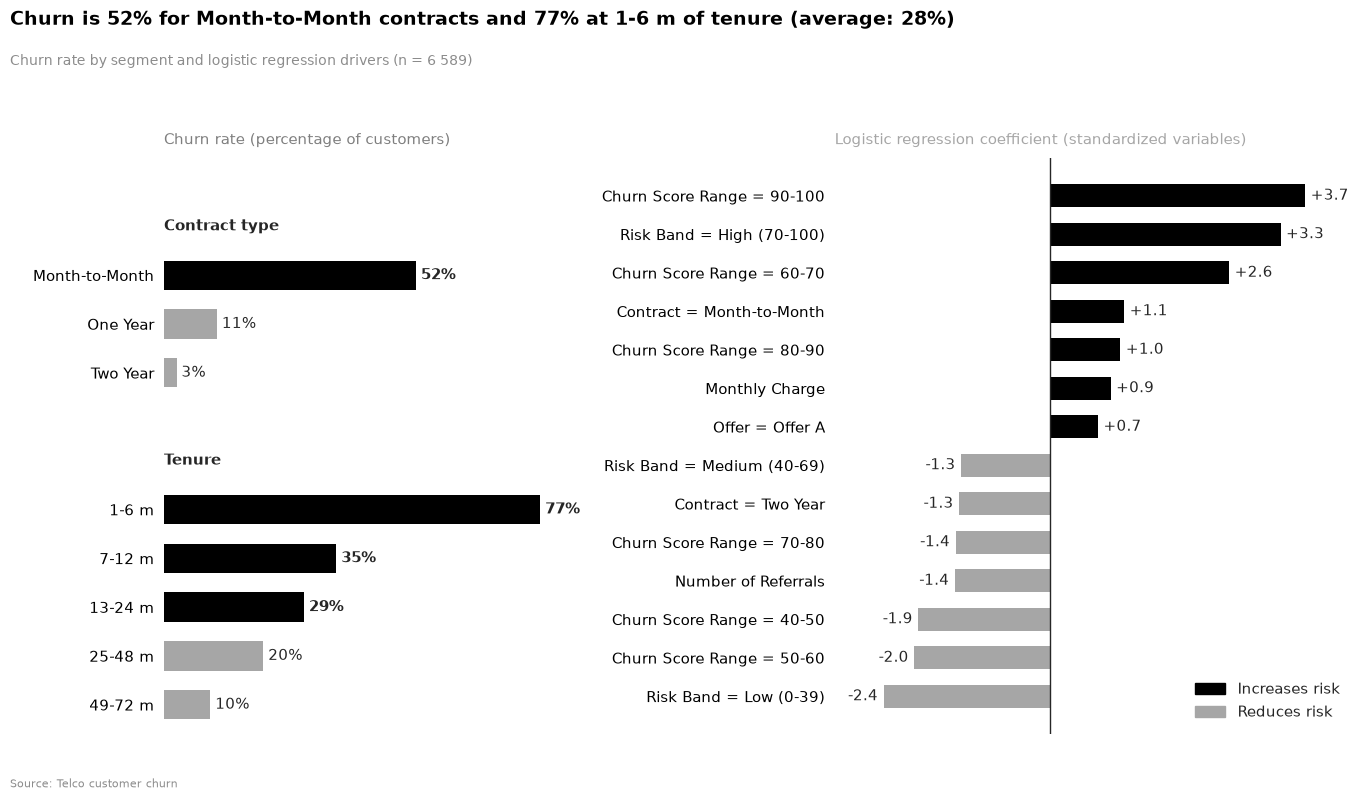

In [151]:
fig, ax1, ax2 = new_layout()

# Panel 1: churn rate by segment
for y, lbl, v in segment_items:
    ax1.barh(y, v, height=0.6, color=BLACK if v > mean_churn else LIGHT_GRAY)
    ax1.text(v + 0.01, y, f"{v:.0%}", va="center", fontweight="bold" if v > mean_churn else "normal")
ax1.set_xlim(0, max(v for _, _, v in segment_items) * 1.15)
segments_axis(ax1, "Churn rate (percentage of customers)")

# Panel 2: coefficients
ypos = np.arange(len(sel))   # 1 position per coefficient (largest on top)
ax2.barh(ypos, sel.values, height=0.6, color=[BLACK if v > 0 else LIGHT_GRAY for v in sel.values])
for yi, v in zip(ypos, sel.values):
    ax2.text(v + (0.08 if v > 0 else -0.08), yi, f"{v:+.1f}",
             va="center", ha="left" if v > 0 else "right")
ax2.axvline(0, color=TEXT_COLOR, lw=1)
ax2.set_yticks(ypos); ax2.set_yticklabels(coef_labels)
ax2.set_xlim(sel.min() - 0.7, sel.max() + 0.7)
ax2.set_title("Logistic regression coefficient (standardized variables)",
              loc="left", fontsize=11, color=LIGHT_GRAY, pad=10)
ax2.legend(handles=[Patch(color=BLACK, label="Increases risk"),
                    Patch(color=LIGHT_GRAY, label="Reduces risk")],
           frameon=False, loc="lower right")
strip_axes(ax2)

def add_frame_ts(fig, title, subtitle, source="Source: Telco customer churn"):
    fig.text(0.01, 0.985, title, fontsize=14, fontweight="bold",
             ha="left", va="top", color=BLACK)
    fig.text(0.01, 0.93, subtitle, fontsize=10,
             ha="left", va="top", color=DARK_GRAY)
    fig.text(0.01, 0.01, source, fontsize=8,
             ha="left", va="bottom", color=DARK_GRAY)

add_frame_ts(
    fig,
    "Churn is 52% for Month-to-Month contracts and 77% at 1-6 m of tenure (average: 28%)",
    "Churn rate by segment and logistic regression drivers (n = 6 589)",
)
plt.show()

**How to read the chart:** the two panels show the churn rate by contract and by tenure (left; black = above the 28% average) and the factors with the greatest weight in the logistic regression (right). The right panel is dominated by the `Churn Score Range` bands (+5.9 for 90-100 and −3.2 for 50-60, for example), which is the leakage described in 3.5, so only the other bars should be read as business drivers: Month-to-Month contract (+1.1), Monthly Charge (+0.6), tenure (−1.3), number of referrals (−1.4) and two-year contract (−1.3). The sign of some coefficients (for example `Offer A`, positive although it has the lowest churn in the EDA) diverges from the isolated analysis because of correlated variables; the robust message is the one from the left panel: **monthly contract and the first months of life are the big warning signs**.

### 6.2 Answer to Problem 2 — Which customers have the highest churn risk?

- **Can we identify the churners in the test set?** Yes. The winning model (Gradient Boosting calibrated + FE) reaches a PR-AUC of **0.968** on the test set, against 0.284 for a random selection. With a threshold of 0.5, it identifies 85% of the churners (recall 0.850) with 93.8% precision.
- **Ability to distinguish who left from who stayed:** ROC-AUC of **0.986** on the test set: a randomly chosen churner receives a higher probability than a customer who stayed about 99% of the time (0.5 would be chance).
- **Which model has the best performance?** On validation, the two calibrated gradient boostings lead (0.965, with or without FE); Logistic Regression + FE (0.964), Gradient Boosting (0.963) and Gradient Boosting + FE (0.963) are practically tied with them; the logistic regression without FE (0.953) and the random forest (0.952) are slightly behind and the simple tree (0.898) is clearly behind. Logistic regression + FE is the simplest and most explainable alternative, with close performance.
- **Caveat:** all these values are inflated by the `Churn Score Range` column that is still in `X` (see 3.5).

Thus, the model ranks all eligible customers by churn probability, and those with the highest probability are the highest-risk ones.

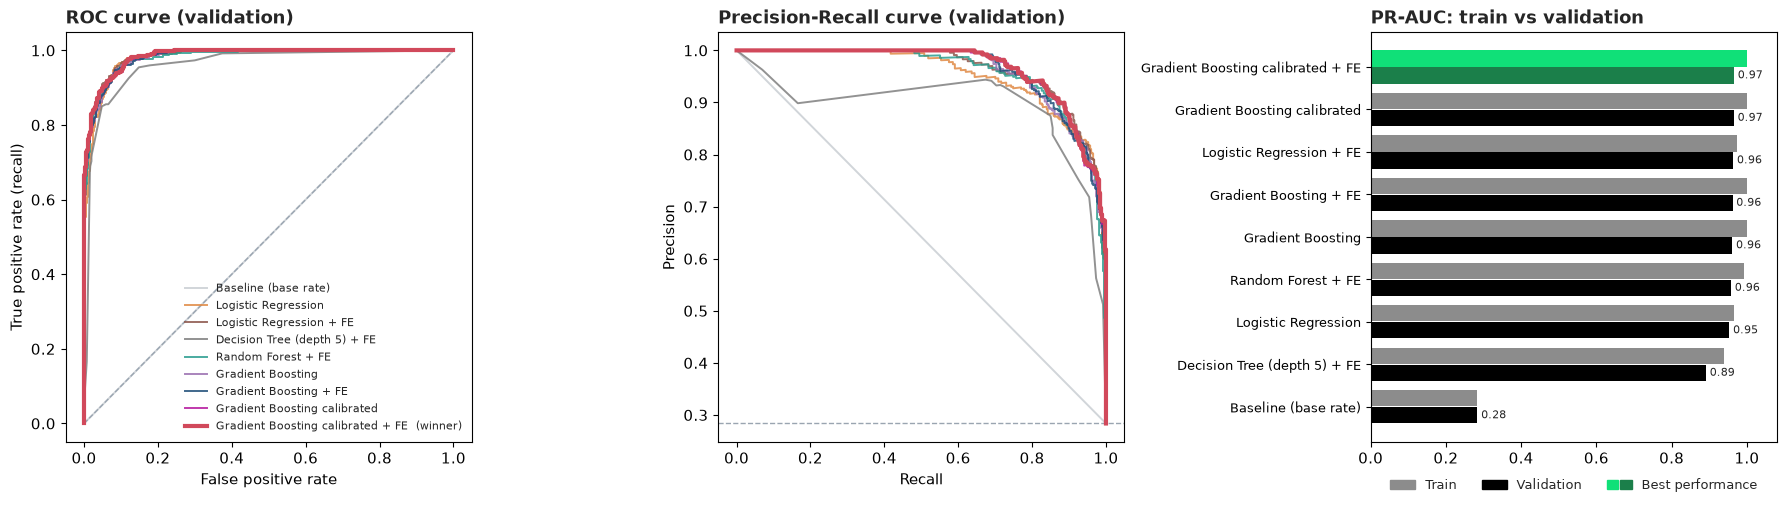

In [152]:
DARK_GREEN = "#1B7F4A"   # dark green for the best model's validation bar
MAIN_COLOR, HIGHLIGHT_COLOR, NEUTRAL_COLOR = "#1f4e79", "#d1495b", "#9aa5b1"

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
palette = {
    "Baseline (base rate)": "#c9ced3",
    "Logistic Regression": "#e08a45",
    "Logistic Regression + FE": "#8c564b",
    "Decision Tree (depth 5) + FE": "#7f7f7f",
    "Random Forest + FE": "#2a9d8f",
    "Gradient Boosting": "#9a6fb0",
    "Gradient Boosting + FE": "#1f4e79",
    "Gradient Boosting calibrated": "#b5179e",
    "Gradient Boosting calibrated + FE": "#7b2d8e",
}

for name, model in fitted.items():
    Xv = feature_sets[fset_of[name]][1]
    pv = model.predict_proba(Xv)[:, 1]
    is_winner = name == best
    kw = dict(
        color=HIGHLIGHT_COLOR if is_winner else palette.get(name, "#999"),
        linewidth=3 if is_winner else 1.4,
        alpha=1 if is_winner else 0.85,
        label=name + ("  (winner)" if is_winner else ""),
        zorder=5 if is_winner else 2,
    )
    fpr, tpr, _ = roc_curve(y_val, pv)
    axes[0].plot(fpr, tpr, **kw)
    prec, rec, _ = precision_recall_curve(y_val, pv)
    axes[1].plot(rec, prec, **kw)

axes[0].plot([0, 1], [0, 1], color=NEUTRAL_COLOR, linestyle="--", linewidth=1)
axes[0].set(
    xlabel="False positive rate", ylabel="True positive rate (recall)"
)
axes[0].set_title("ROC curve (validation)", loc="left", fontweight="bold")
axes[1].axhline(y_val.mean(), color=NEUTRAL_COLOR, linestyle="--", linewidth=1)
axes[1].set(xlabel="Recall", ylabel="Precision")
axes[1].set_title("Precision-Recall curve (validation)", loc="left", fontweight="bold")
axes[0].legend(fontsize=8, loc="lower right", frameon=False)

# Train vs validation: sign of overfitting
pv_tab = (
    results[results["dataset"].isin(["train", "validation"])]
    .pivot(index="model", columns="dataset", values="pr_auc")
    .sort_values("validation")
)

# Model with the highest validation PR-AUC (Gradient Boosting calibrated + FE)
top = pv_tab["validation"].idxmax()
train_colors = [GREEN if m == top else DARK_GRAY for m in pv_tab.index]
val_colors = [DARK_GREEN if m == top else BLACK for m in pv_tab.index]

y_pos = np.arange(len(pv_tab))
axes[2].barh(y_pos + 0.2, pv_tab["train"], height=0.38, color=train_colors)
axes[2].barh(y_pos - 0.2, pv_tab["validation"], height=0.38, color=val_colors)

axes[2].set_yticks(y_pos)
axes[2].set_yticklabels([m for m in pv_tab.index], fontsize=9)
axes[2].set_xlim(0, 1.08)
axes[2].set_title("PR-AUC: train vs validation", loc="left", fontweight="bold")

# Legend below the chart: the two greens = best performance
axes[2].legend(
    handles=[
        Patch(color=DARK_GRAY, label="Train"),
        Patch(color=BLACK, label="Validation"),
        (Patch(color=GREEN), Patch(color=DARK_GREEN)),
    ],
    labels=["Train", "Validation", "Best performance"],
    handler_map={tuple: HandlerTuple(ndivide=None, pad=0.2)},
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
    ncol=3,
    fontsize=9,
)
for i, (t, v) in enumerate(zip(pv_tab["train"], pv_tab["validation"])):
    axes[2].text(v + 0.01, i - 0.2, f"{v:.2f}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

**How to read the chart:** in the ROC and Precision-Recall curves (computed on **validation**, where the choice was made) the winner's curve is in red; the curves of the five best models (PR-AUC 0.963-0.965) practically overlap, the logistic regression without FE and the random forest (0.953 and 0.952) sit slightly lower, and only the decision tree (0.898) is clearly lower. The right panel compares the PR-AUC on train and validation: the four gradient boostings (1.000) and the random forest (0.993) have a train bar above the validation one (0.952-0.965), which is the overfitting; the gap is small only because validation is also inflated by the leakage.

### 6.3 Answer to Problem 3 — Whom should we contact first?

- **How many at-risk customers do we identify with 5%, 10% or 20% of contacts?** Out of 1,318 test customers (374 churners): contacting 66 customers (5%) we catch **66** churners; with 132 (10%) we catch **132**; with 264 (20%) we catch **261**.
- **Proportion of churners in each group:** **100%**, **100%** and **98.9%**. Relative to the total number of churners, this equals a recall of 17.6%, 35.3% and **69.8%**.
- **Comparison with random selection:** the churn rate is 28.4%, so by chance a group of 10% would have about 37 churners; the model catches 132, i.e. a **lift of 3.5×** (3.5× at 20% as well). Compared with the SPSS Churn Score it is equal at 5% and 10% and ahead at 20% (261 vs 236), keeping in mind that `Churn Score Range` is still in `X` (see 2.1.4).
- **Going beyond probability:** ranking by expected value (probability × average monthly revenue), 57 of the 132 customers in the top 10% remain, the monthly revenue of the churners caught rises 30% (9,398 → 12,181) and the number of churners in the group drops from 132 to 129.

**Recommendation:** start with the 10% of customers with the highest risk (100% hit rate on the test set) and, if there is room, extend to 20% (98.9%). If the goal is to maximize the retained value and not only the number of customers, use the expected-value list.

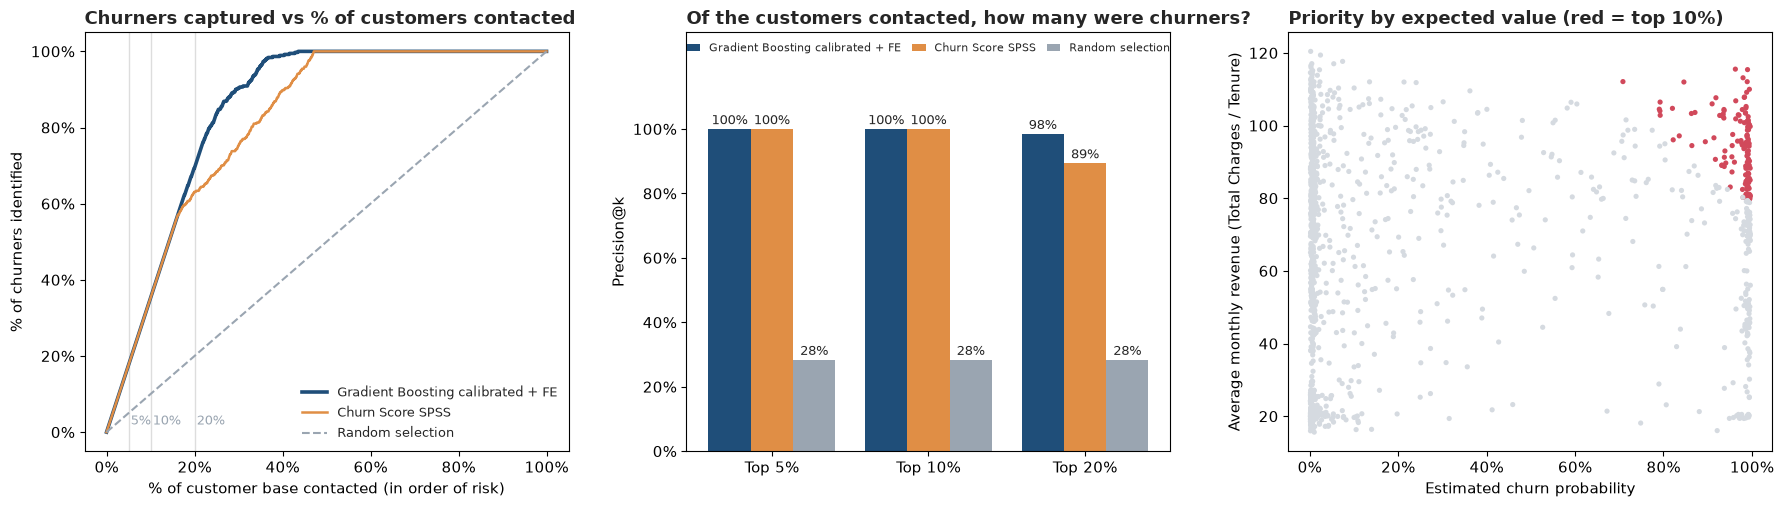

In [153]:
def gains_curve(y_true, scores):
    d = pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(scores)}).sort_values(
        "s", ascending=False, kind="mergesort"
    )
    x = np.arange(1, len(d) + 1) / len(d)
    return np.insert(x, 0, 0), np.insert(d["y"].cumsum().values / d["y"].sum(), 0, 0)


spss = model_df.loc[X_test.index, "Churn Score"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Cumulative gains curve
x, g_mod = gains_curve(y_test, p_test)
_, g_spss = gains_curve(y_test, spss)
axes[0].plot(x, g_mod, color=MAIN_COLOR, linewidth=2.6, label=f"{best}")
axes[0].plot(x, g_spss, color="#e08e45", linewidth=1.8, label="Churn Score SPSS")
axes[0].plot(
    [0, 1], [0, 1], color=NEUTRAL_COLOR, linestyle="--", label="Random selection"
)
for f in (0.05, 0.10, 0.20):
    axes[0].axvline(f, color="#dddddd", linewidth=1, zorder=0)
    axes[0].text(f + 0.005, 0.02, f"{int(f*100)}%", color=NEUTRAL_COLOR, fontsize=9)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set(
    xlabel="% of customer base contacted (in order of risk)",
    ylabel="% of churners identified",
)
axes[0].set_title(
    "Churners captured vs % of customers contacted", loc="left", fontweight="bold"
)
axes[0].legend(frameon=False, loc="lower right", fontsize=9)

# Precision@k: of the customers contacted, how many were churners?
tk_m, tk_s = topk_table(y_test, p_test), topk_table(y_test, spss)
base = y_test.mean()
pos = np.arange(3)
axes[1].bar(pos - 0.27, tk_m["Precision@k"], 0.27, color=MAIN_COLOR, label=best)
axes[1].bar(pos, tk_s["Precision@k"], 0.27, color="#e08e45", label="Churn Score SPSS")
axes[1].bar(pos + 0.27, [base] * 3, 0.27, color=NEUTRAL_COLOR, label="Random selection")
for i in range(3):
    axes[1].text(
        i - 0.27,
        tk_m["Precision@k"][i] + 0.015,
        f"{tk_m['Precision@k'][i]:.0%}",
        ha="center",
        fontsize=9,
    )
    axes[1].text(
        i,
        tk_s["Precision@k"][i] + 0.015,
        f"{tk_s['Precision@k'][i]:.0%}",
        ha="center",
        fontsize=9,
    )
    axes[1].text(i + 0.27, base + 0.015, f"{base:.0%}", ha="center", fontsize=9)
axes[1].set_xticks(pos)
axes[1].set_xticklabels(["Top 5%", "Top 10%", "Top 20%"])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_ylim(0, 1.3)
axes[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
axes[1].set(ylabel="Precision@k")
axes[1].set_title(
    "Of the customers contacted, how many were churners?", loc="left", fontweight="bold"
)
axes[1].legend(
    frameon=False,
    fontsize=8,
    loc="upper center",
    ncol=3,
    columnspacing=1.0,
    handlelength=1.2,
)

# Probability vs CLTV: who enters the top 10% by expected value
colors3 = np.where(priorities_ev.index.isin(top_ev), HIGHLIGHT_COLOR, "#d5dae0")
axes[2].scatter(
    priorities_ev["Churn Probability"],
    priorities_ev["Avg Monthly Revenue"],
    c=colors3,
    s=14,
    edgecolors="none",
)
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[2].set(
    xlabel="Estimated churn probability",
    ylabel="Average monthly revenue (Total Charges / Tenure)",
)
axes[2].set_title(
    "Priority by expected value (red = top 10%)", loc="left", fontweight="bold"
)
plt.tight_layout()
plt.show()

In [154]:
# Compute monthly revenue, risk value, and top segment thresholds
d = pd.DataFrame(
    {
        "prob": p_test,
        "revenue": model_df.loc[X_test.index, "Total Charges"]
        / model_df.loc[X_test.index, "Tenure in Months"],
    }
)
d["value"] = d["prob"] * d["revenue"]

TOP_PCT = 0.05
threshold = d["value"].quantile(1 - TOP_PCT)
d["top"] = d["value"] >= threshold

n_total, n_top = len(d), int(d["top"].sum())
share_top = d.loc[d["top"], "value"].sum() / d["value"].sum()
base_title = f"{n_top} customers ({TOP_PCT:.0%}) concentrate {share_top:.0%} of expected value at risk"

In [155]:
def add_frame(fig, title, subtitle, source="Source: Telco customer churn"):
    fig.text(0.02, 0.97, title, fontsize=15, fontweight="bold", ha="left", va="top")
    fig.text(0.02, 0.905, subtitle, fontsize=11, color=MID_GRAY, ha="left", va="top")
    fig.text(0.02, 0.01, source, fontsize=9, color=MID_GRAY, ha="left", va="bottom")

def strip_axes(ax, keep_y=False, keep_x=False):
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    if keep_y:
        ax.spines["left"].set_visible(True); ax.spines["left"].set_color(TEXT_COLOR)
    if keep_x:
        ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color(TEXT_COLOR)
    ax.grid(False)

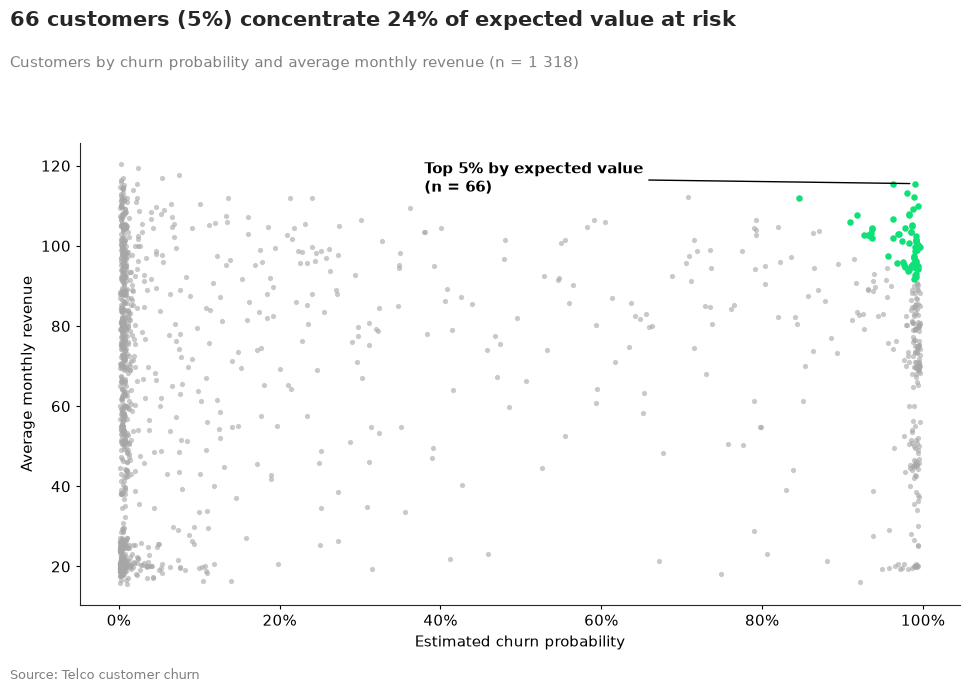

In [156]:
fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.09, right=0.97)

rest, top = d[~d["top"]], d[d["top"]]
ax.scatter(rest["prob"], rest["revenue"], s=14, color=LIGHT_GRAY, alpha=0.6, linewidths=0)
ax.scatter(top["prob"], top["revenue"], s=22, color=GREEN, linewidths=0)

ax.annotate(f"Top {TOP_PCT:.0%} by expected value\n(n = {n_top})",
            xy=(top["prob"].median(), top["revenue"].max()),
            xytext=(0.38, d["revenue"].max() * 0.97),
            fontsize=11, fontweight="bold", color=BLACK, va="center",
            arrowprops=dict(arrowstyle="-", color=BLACK, lw=1))

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Estimated churn probability", color=BLACK)
ax.set_ylabel("Average monthly revenue", color=BLACK)
ax.tick_params(colors=BLACK, length=3)
strip_axes(ax, keep_y=True, keep_x=True)

add_frame(fig, base_title,
        f"Customers by churn probability and average monthly revenue (n = {n_total:,})".replace(",", " "))
plt.show()

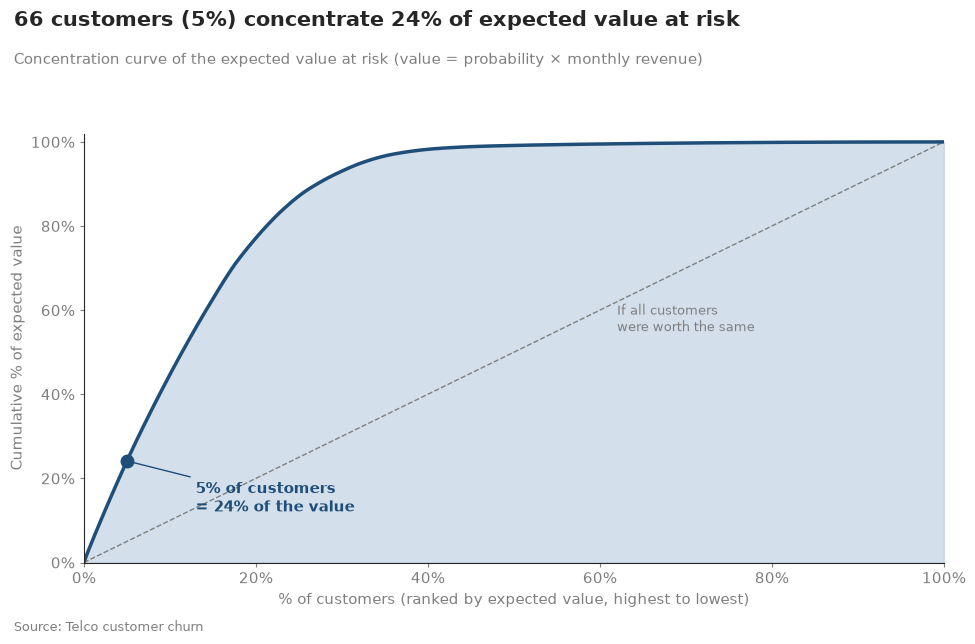

In [157]:
v = d["value"].sort_values(ascending=False).to_numpy()
x = np.arange(1, len(v) + 1) / len(v)
y = np.cumsum(v) / v.sum()

fig, ax = plt.subplots(figsize=(10, 6.5))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.09, right=0.95)

ax.plot([0, 1], [0, 1], color=MID_GRAY, ls="--", lw=1)             # uniform distribution
ax.text(0.62, 0.55, "If all customers\nwere worth the same", color=MID_GRAY, fontsize=9, ha="left")

ax.fill_between(x, y, color=LIGHT_BLUE, alpha=0.5)
ax.plot(x, y, color=NAVY, lw=2.5)
ax.plot(TOP_PCT, share_top, "o", ms=9, color=NAVY)
ax.annotate(f"{TOP_PCT:.0%} of customers\n= {share_top:.0%} of the value",
            xy=(TOP_PCT, share_top), xytext=(TOP_PCT + 0.08, share_top - 0.12),
            fontsize=11, fontweight="bold", color=NAVY,
            arrowprops=dict(arrowstyle="-", color=NAVY, lw=1))

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("% of customers (ranked by expected value, highest to lowest)", color=MID_GRAY)
ax.set_ylabel("Cumulative % of expected value", color=MID_GRAY)
ax.tick_params(colors=MID_GRAY, length=3)
strip_axes(ax, keep_y=True, keep_x=True)

add_frame(fig, base_title, "Concentration curve of the expected value at risk (value = probability × monthly revenue)")
plt.show()

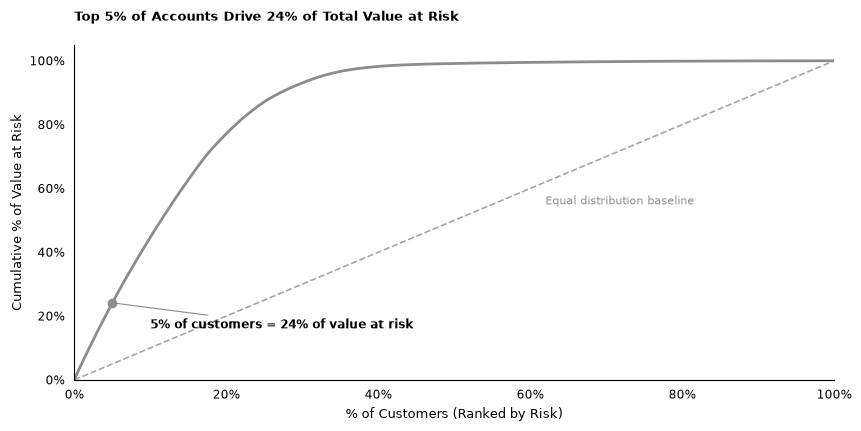

In [158]:
# IBCS Lorenz Curve: Value at Risk Concentration
fig, ax = plt.subplots(figsize=(8.5, 4.2), layout="constrained")

# Equal distribution reference baseline
ax.plot([0, 1], [0, 1], color=LIGHT_GRAY, ls="--", lw=1.2)
ax.text(0.62, 0.55, "Equal distribution baseline", color=DARK_GRAY, fontsize=8, ha="left")

# Primary curve and focal point callout in gray
ax.plot(x, y, color=DARK_GRAY, lw=2)
ax.plot(TOP_PCT, share_top, marker="o", ms=6, color=DARK_GRAY)

# Direct data annotation with black callout values
ax.annotate(
    f"{TOP_PCT:.0%} of customers = {share_top:.0%} of value at risk",
    xy=(TOP_PCT, share_top),
    xytext=(TOP_PCT + 0.05, share_top - 0.08),
    fontsize=8.5,
    weight="bold",
    color=BLACK,
    arrowprops=dict(arrowstyle="-", color=DARK_GRAY, lw=0.8),
)

# Axis formatters and limits in solid black
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("% of Customers (Ranked by Risk)", color=BLACK, fontsize=9)
ax.set_ylabel("Cumulative % of Value at Risk", color=BLACK, fontsize=9)
ax.tick_params(colors=BLACK, labelsize=8.5, bottom=False, left=False)

# IBCS spine styling
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
for s in ["bottom", "left"]:
    ax.spines[s].set_color(BLACK)

# Compact Action Title
ax.set_title(
    f"Top {TOP_PCT:.0%} of Accounts Drive {share_top:.0%} of Total Value at Risk\n",
    loc="left",
    weight="bold",
    fontsize=9.5,
    color=BLACK,
)

plt.show()

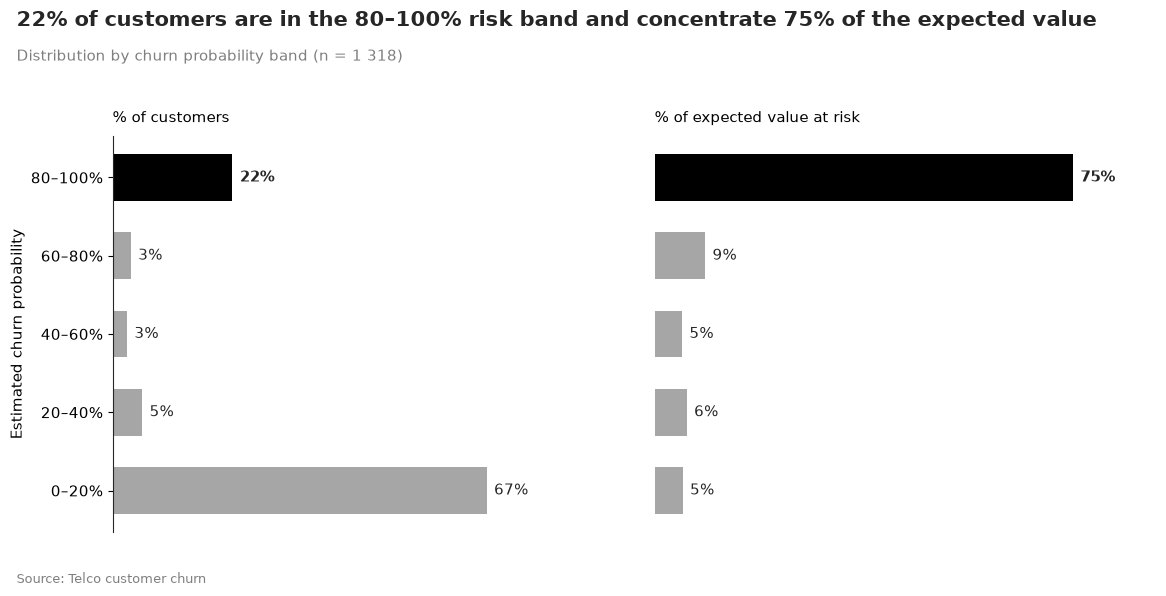

In [159]:
bins = [0, .2, .4, .6, .8, 1.0001]
labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
prob_band = pd.cut(d["prob"], bins=bins, right=False, labels=labels)

pct_customers = prob_band.value_counts(normalize=True).reindex(labels)
pct_value = d.groupby(prob_band, observed=False)["value"].sum().reindex(labels) / d["value"].sum()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
fig.subplots_adjust(top=0.76, bottom=0.10, left=0.10, right=0.97, wspace=0.08)

ypos = np.arange(len(labels))
colors = [BLACK if l == labels[-1] else LIGHT_GRAY for l in labels]
xmax = max(pct_customers.max(), pct_value.max()) * 1.2          # same scale on both panels

for ax, series, name in [(a1, pct_customers, "% of customers"), (a2, pct_value, "% of expected value at risk")]:
    ax.barh(ypos, series.values, height=0.6, color=colors)
    for yi, val, l in zip(ypos, series.values, labels):
        ax.text(val + xmax * 0.015, yi, f"{val:.0%}", va="center",
                fontweight="bold" if l == labels[-1] else "normal")
    ax.set_xlim(0, xmax)
    ax.set_xticks([])
    ax.set_title(name, loc="left", fontsize=11, color=BLACK, pad=10)
    strip_axes(ax, keep_y=(ax is a1))

a1.set_yticks(ypos); a1.set_yticklabels(labels)
a1.set_ylabel("Estimated churn probability", color=BLACK)
a2.tick_params(left=False)

add_frame(fig,
        f"{pct_customers.iloc[-1]:.0%} of customers are in the 80–100% risk band and concentrate {pct_value.iloc[-1]:.0%} of the expected value",
        f"Distribution by churn probability band (n = {n_total:,})".replace(",", " "))
plt.show()